In [47]:
import pandas as pd          # manejo de datos tabulares (DataFrames)
import numpy as np            # algebra lineal y operaciones numericas
import statsmodels.api as sm  # modelos estadisticos (OLS, pruebas, resumenes)
import sklearn as sk          # machine learning (usado para seleccion de variables)
import matplotlib.pyplot as plt  # graficos
from scipy import stats       # distribuciones de probabilidad y pruebas estadisticas

# Ayudantía 7: Análisis de Modelos de Regresión

Para abrir en colab: <a target="_blank" href="https://githubtocolab.com/SysBioengLab/IIQ3402-Statistical-Design/blob/main/Ayudantias/Ayudantia7_AnalisisDeModelosLineales.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


# Regresión Lineal Simple

In [48]:
df = pd.read_csv(
    'https://github.com/SysBioengLab/IIQ3402-Statistical-Design/blob/main/SetDeDatos/Fish.csv?raw=true',    
) # descargamos el dataset
df

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340
...,...,...,...,...,...,...,...
154,Smelt,12.2,11.5,12.2,13.4,2.0904,1.3936
155,Smelt,13.4,11.7,12.4,13.5,2.4300,1.2690
156,Smelt,12.2,12.1,13.0,13.8,2.2770,1.2558
157,Smelt,19.7,13.2,14.3,15.2,2.8728,2.0672


## EDA 


> Realice un análisis exploratorio univariado y bivariado de las variables `Width` y `Height`. ¿Presentan alguna distribución particular? ¿Existen valores atípicos o sesgos?


Previo a cualquier análisis es importante saber con lo que se está trabajando. Para esto realizamos un EDA.

In [49]:
width = df['Width'] # extraemos la columna Width
height = df['Height'] # extraemos la columna Height

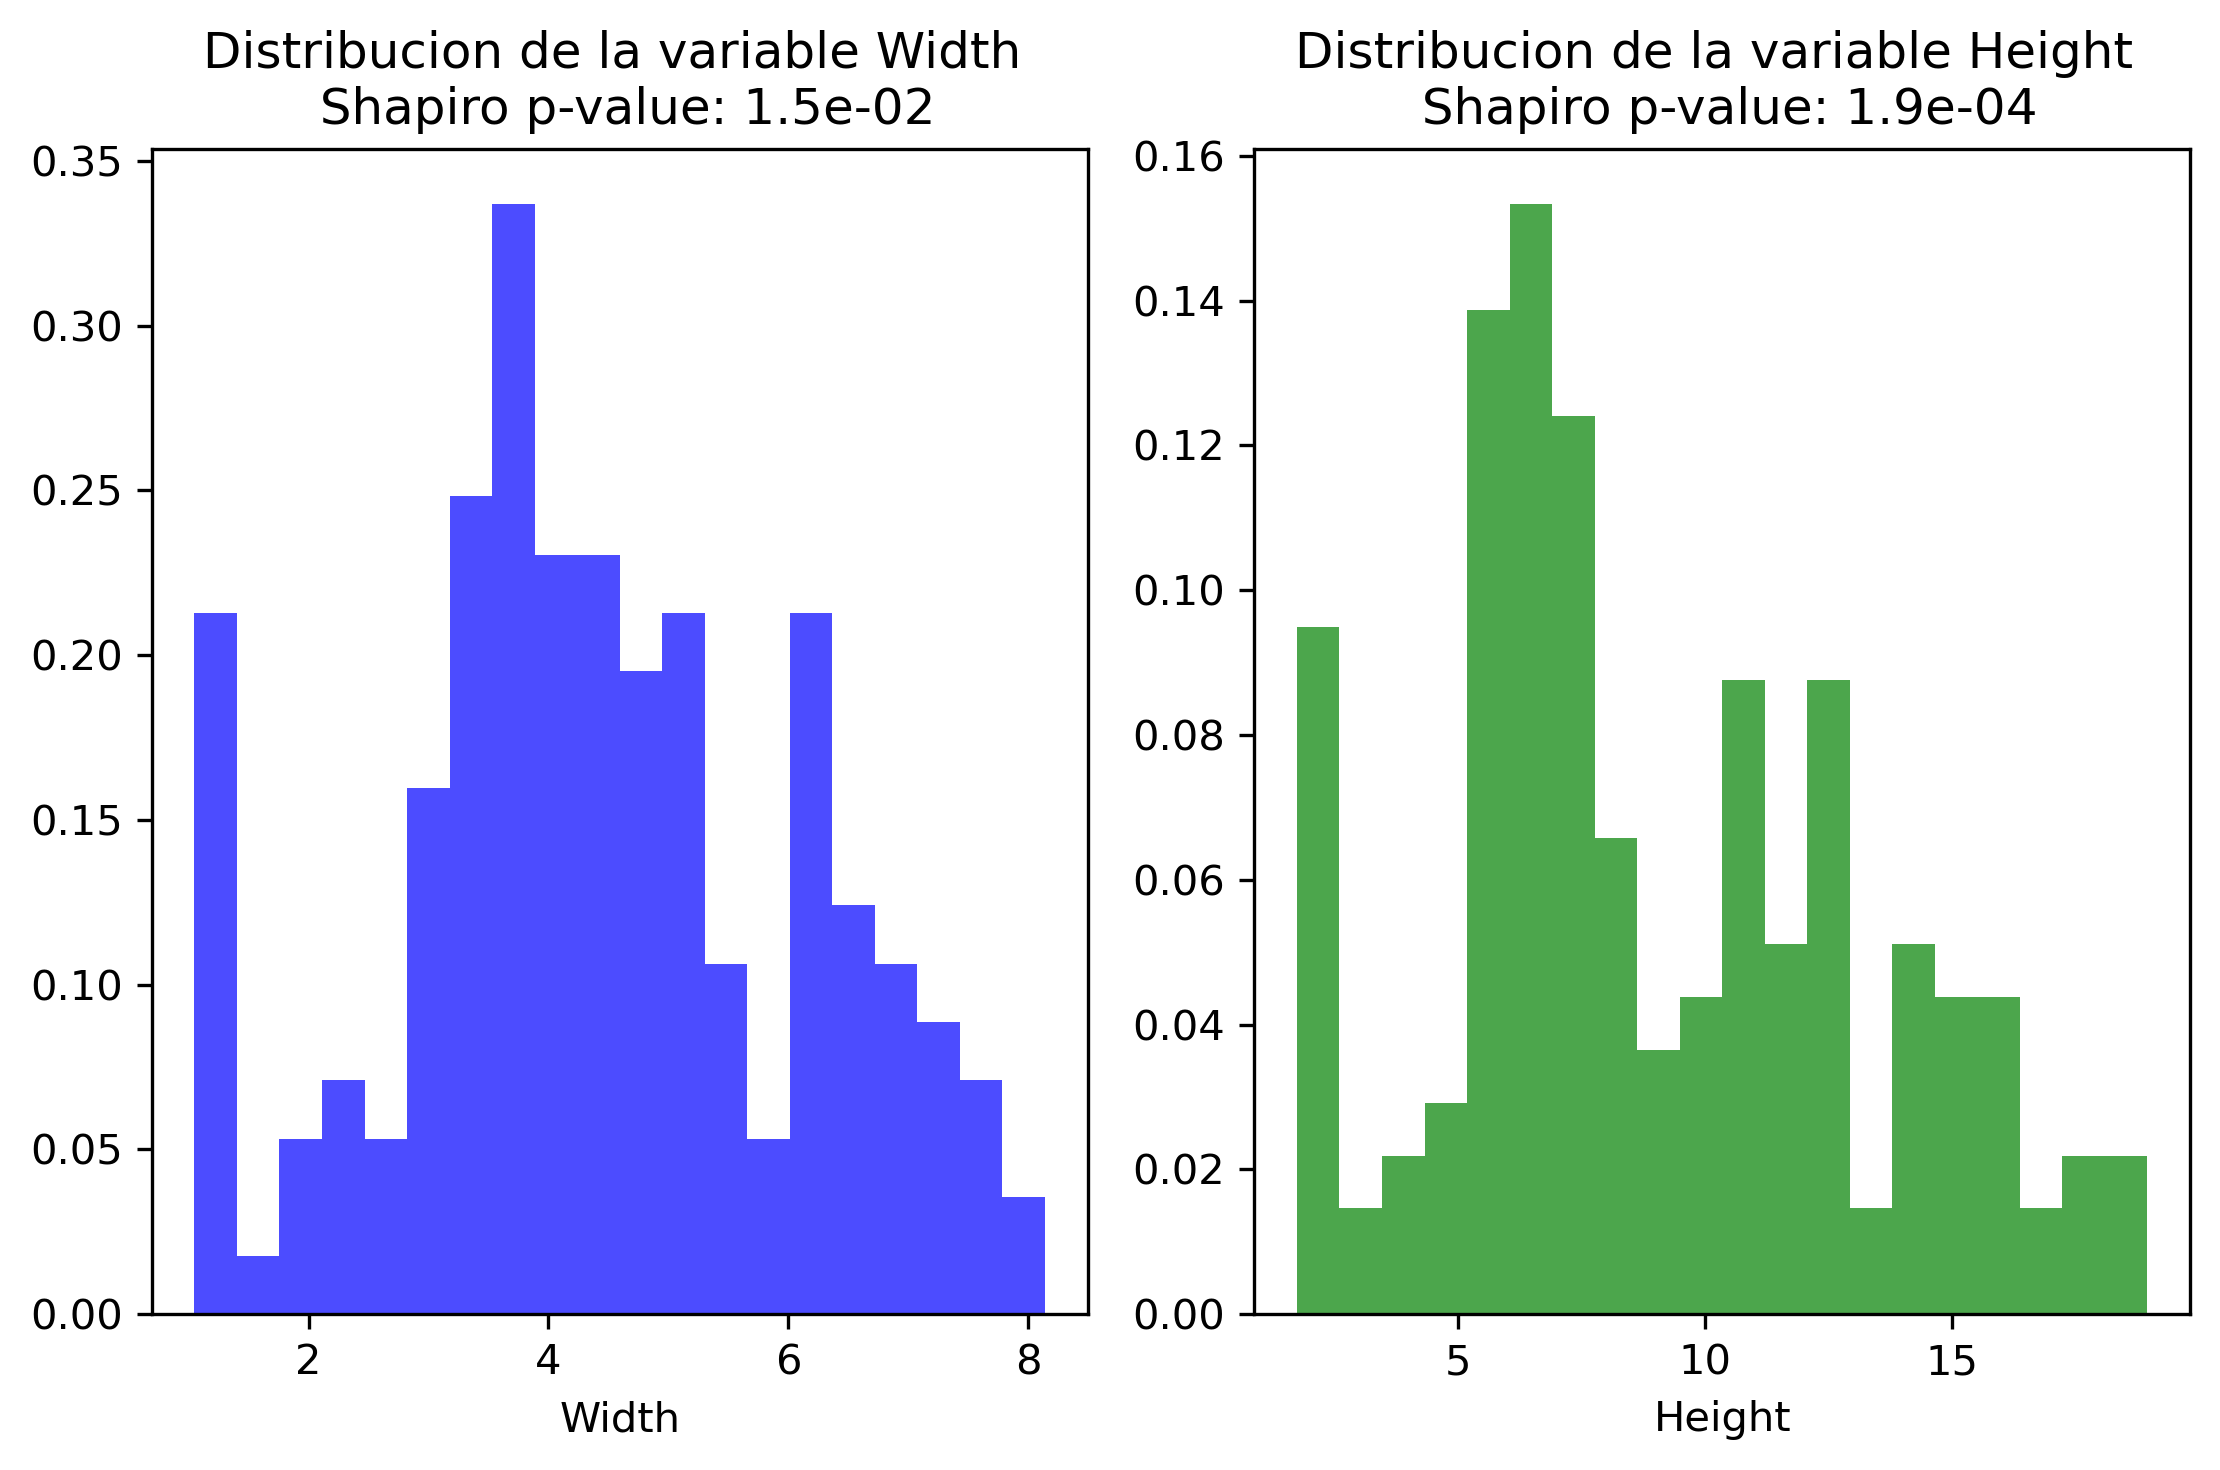

In [50]:
# Graficamos la distribucion empirica de cada variable por separado
# density=True normaliza el histograma para que el area total sea 1 (densidad de probabilidad)
fig, ax = plt.subplots(1, 2, figsize=(7.5, 5), dpi=300)

# -- Width --
shapiro_p = stats.shapiro(width)[1]  # prueba de normalidad de Shapiro-Wilk; [1] extrae el p-value
ax[0].hist(width, bins=20, color='blue', alpha=0.7, density=True)
ax[0].set_title('Distribucion de la variable Width \n Shapiro p-value: {:.1e}'.format(shapiro_p))
ax[0].set_xlabel('Width')

# -- Height --
shapiro_p = stats.shapiro(height)[1]
ax[1].hist(height, bins=20, color='green', alpha=0.7, density=True)
ax[1].set_title('Distribucion de la variable Height \n Shapiro p-value: {:.1e}'.format(shapiro_p))
ax[1].set_xlabel('Height')

fig.tight_layout()
plt.show()

Podemos ver que ambas distribuciones no son normales. Pero no es un problema debido a que los supuestos de normalidad una regresión lineal se aplican a los residuos :D

/var/folders/d4/fcz_093s76vfkprz49zjtkmc0000gn/T/ipykernel_82626/3104479398.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs['scatter'].legend(loc='upper left')


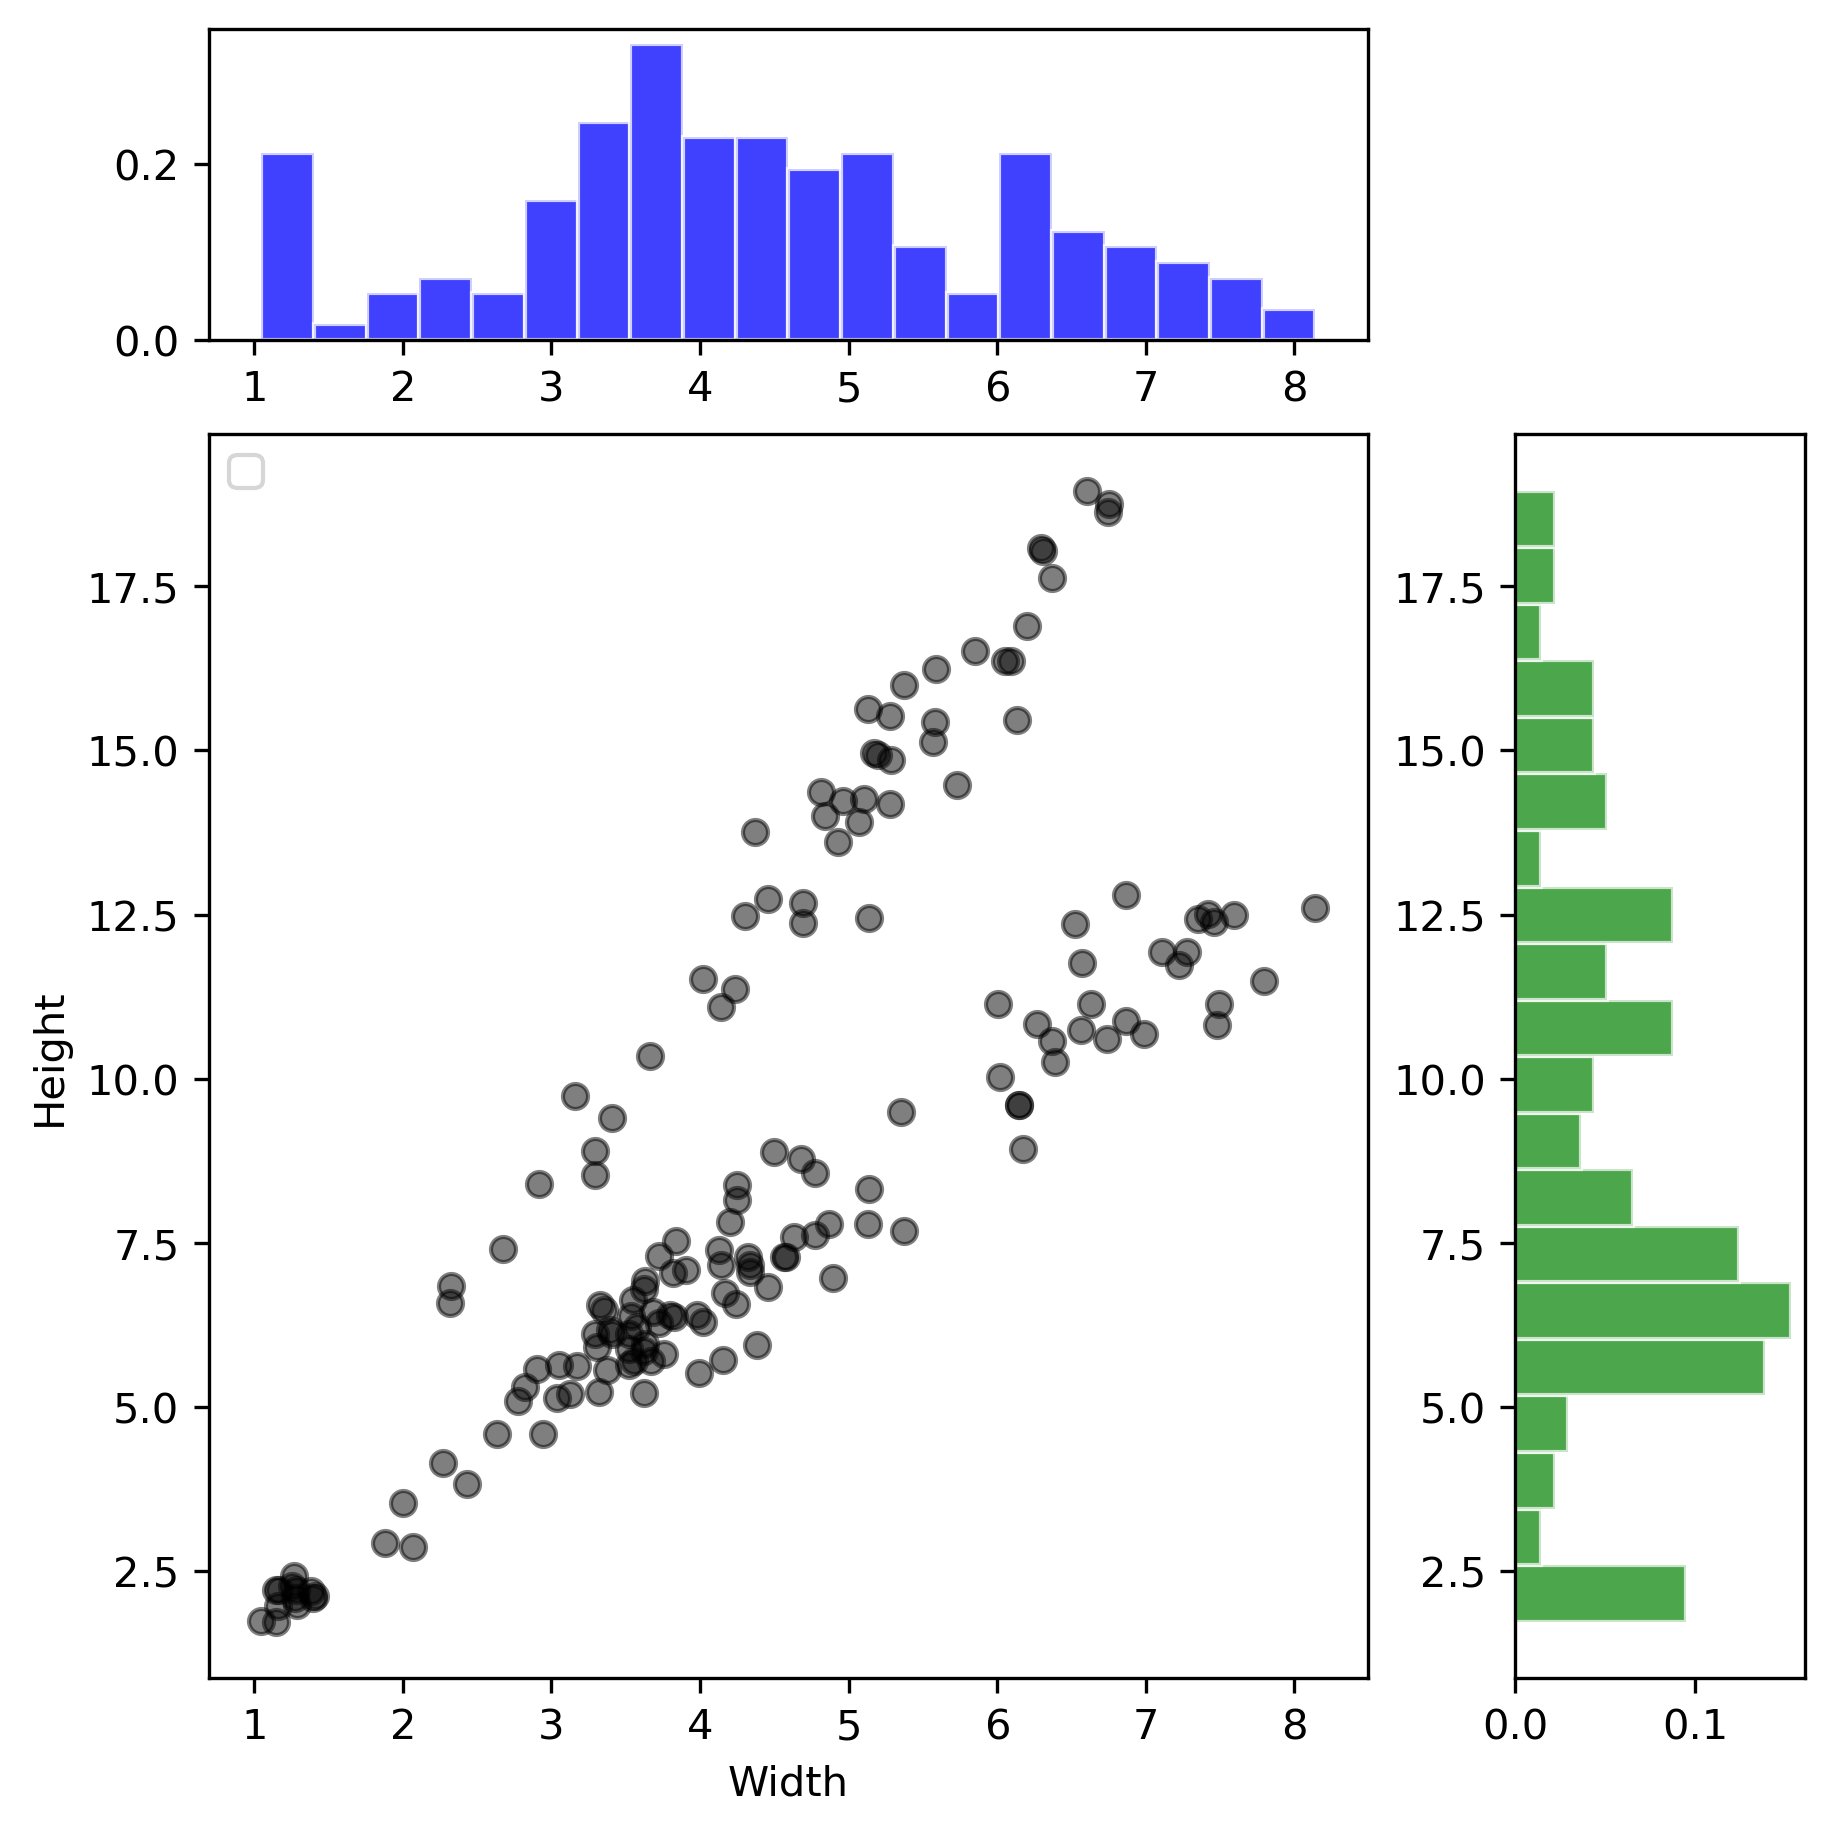

In [51]:
# subplot_mosaic define un layout con nombre para cada panel:
#   'histx' = histograma horizontal (arriba), 'scatter' = dispersion (abajo-izq), 'histy' = histograma vertical (abajo-der)
# width_ratios y height_ratios controlan las proporciones relativas de cada panel
fig, axs = plt.subplot_mosaic(
    [['histx', '.'],
     ['scatter', 'histy']],
    figsize=(6, 6),
    width_ratios=(4, 1), height_ratios=(1, 4),
    layout='constrained', dpi=300
)

axs['scatter'].scatter(width, height, alpha=0.5, color='black')

# orientation='horizontal' rota el histograma de Height para alinearlo con el eje y del scatter
axs['histx'].hist(width, bins=20, color='blue', alpha=0.75, density=True, edgecolor='white')
axs['histy'].hist(height, bins=20, color='green', alpha=0.7, density=True, orientation='horizontal', edgecolor='white')

axs['scatter'].set_xlabel('Width')
axs['scatter'].set_ylabel('Height')
axs['scatter'].legend(loc='upper left')

Podemos ver diferentes "zonas" en la linea de regresión. ¿Qué pasa si agregamos la especie del pez en estos casos?

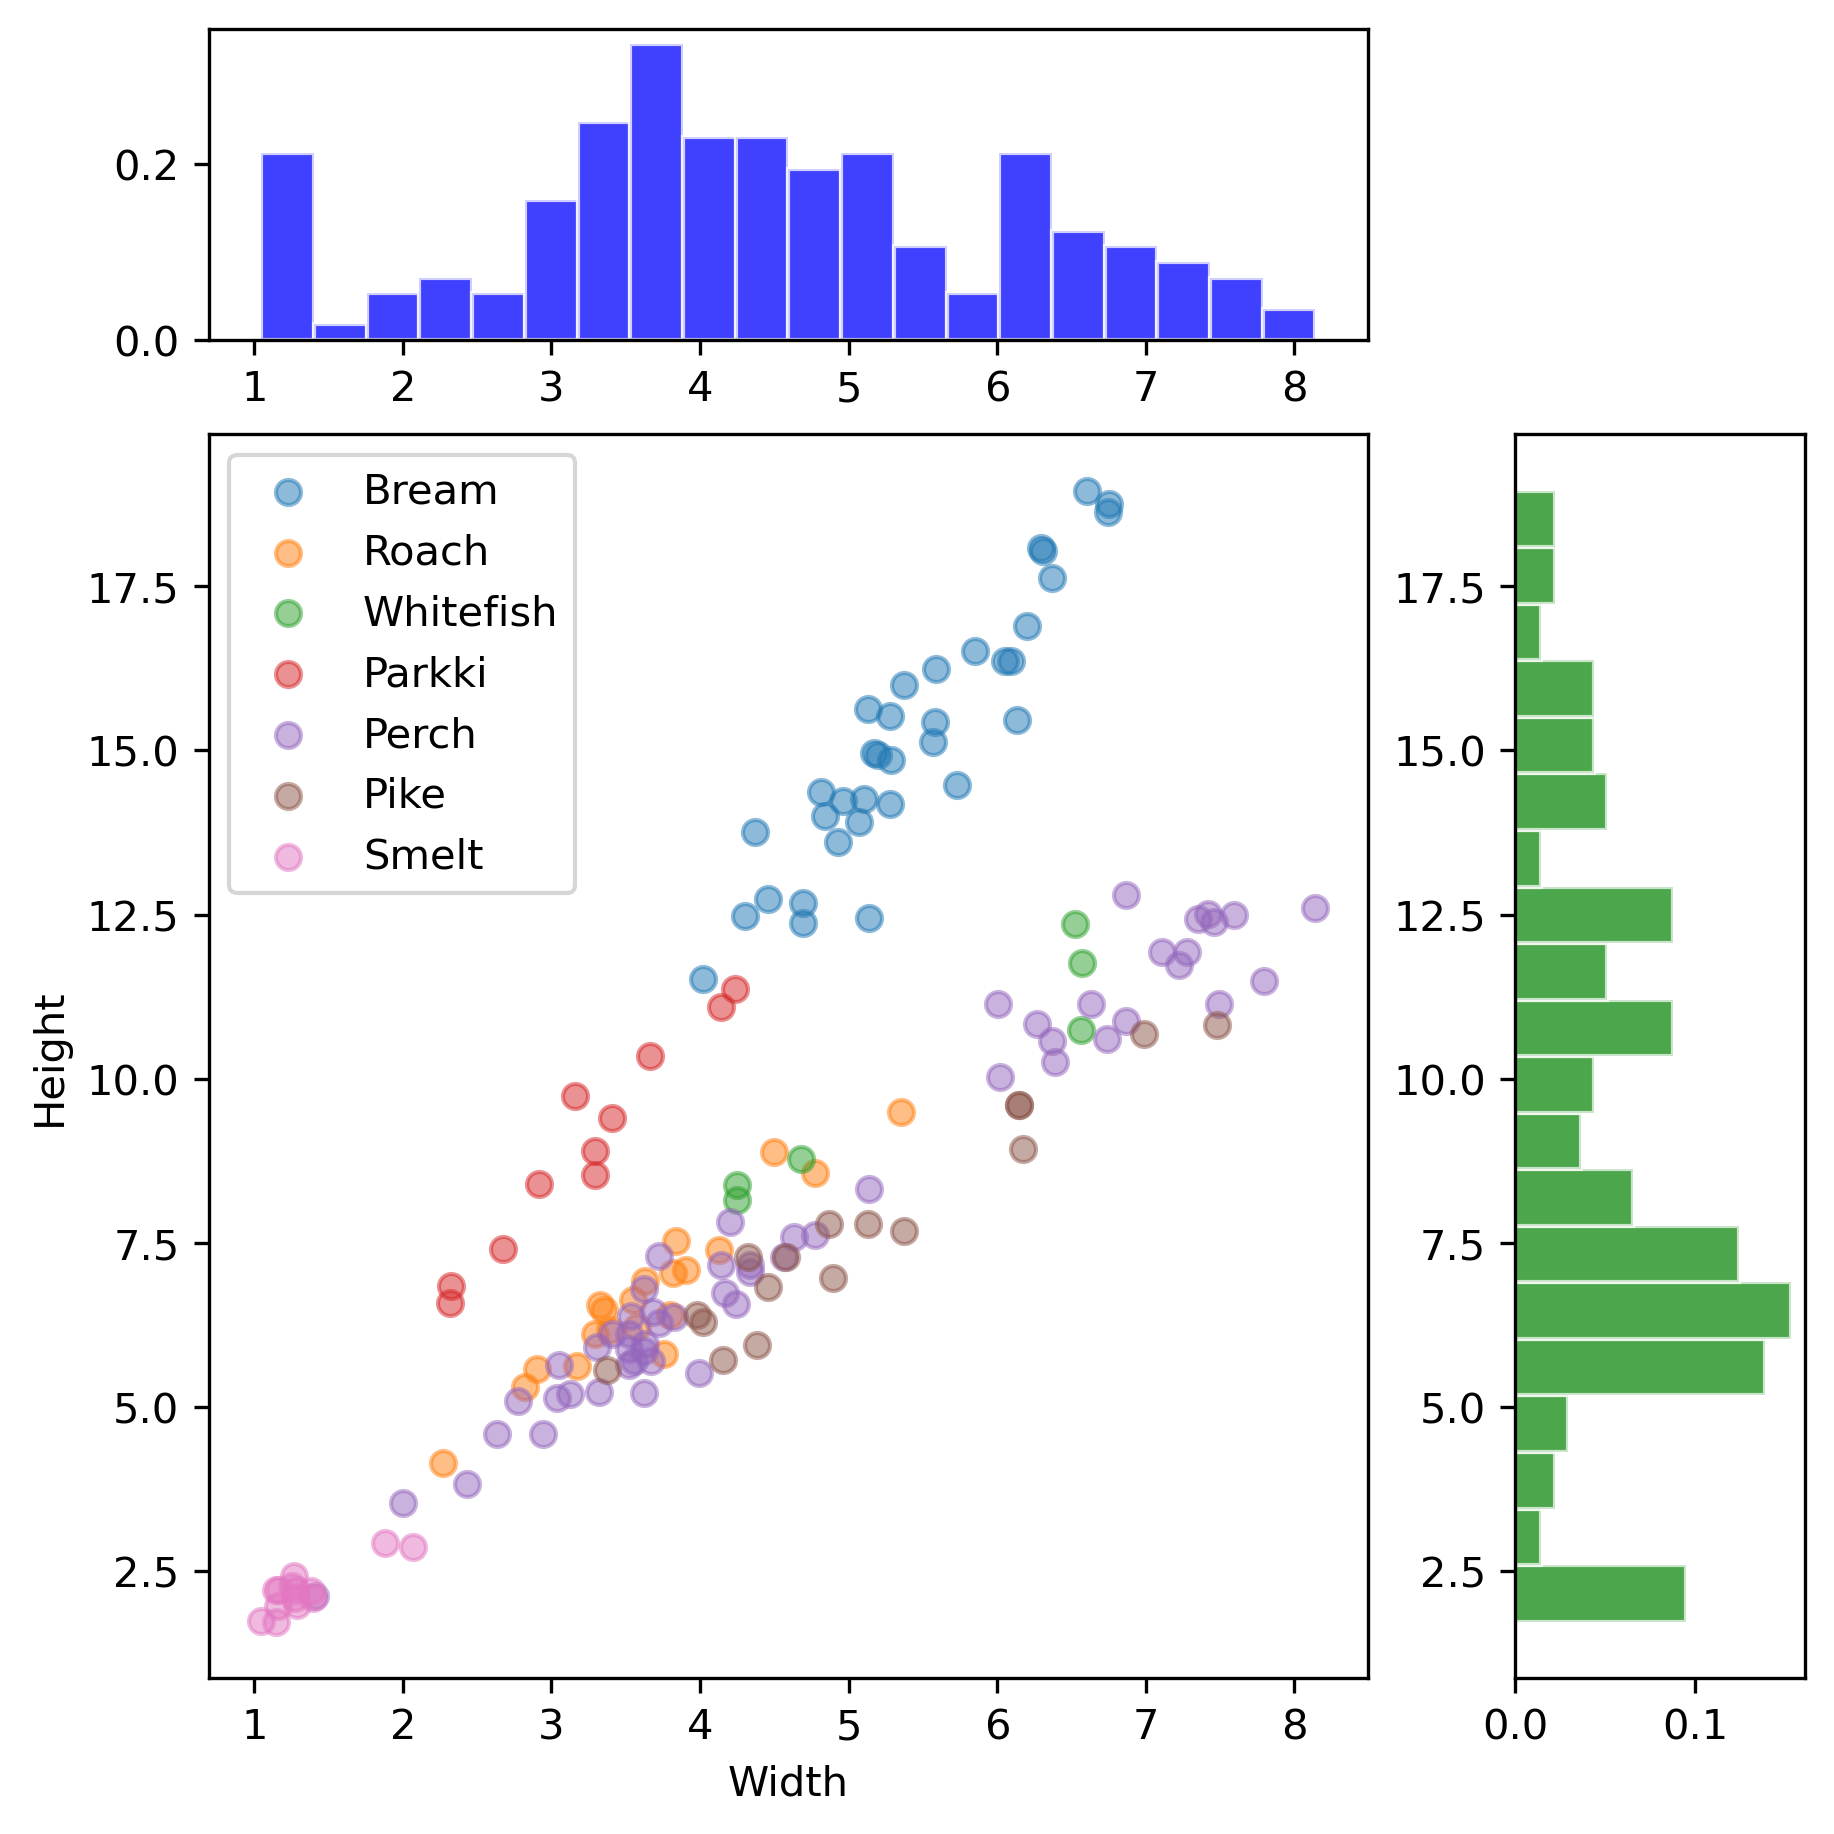

In [52]:
# Repetimos el grafico anterior pero diferenciando por especie para ver si los grupos
# explican las "zonas" observadas en el scatter anterior
fig, axs = plt.subplot_mosaic(
    [['histx', '.'],
     ['scatter', 'histy']],
    figsize=(6, 6),
    width_ratios=(4, 1), height_ratios=(1, 4),
    layout='constrained', dpi=300
)

specie = df['Species']  # columna con la especie de cada pez
for i in specie.unique():
    # specie == i produce una mascara booleana que filtra las filas de esa especie
    axs['scatter'].scatter(width[specie == i], height[specie == i], alpha=0.5, label=i)

axs['histx'].hist(width, bins=20, color='blue', alpha=0.75, density=True, edgecolor='white')
axs['histy'].hist(height, bins=20, color='green', alpha=0.7, density=True, orientation='horizontal', edgecolor='white')
axs['scatter'].set_xlabel('Width')
axs['scatter'].set_ylabel('Height')
axs['scatter'].legend(loc='upper left')

## Cálculo de Regresión lineal
>Estime los coeficientes de un modelo de regresión lineal simple que relacione `Height` como variable respuesta y `Width` como predictor. Grafique los datos junto con la recta ajustada. 
>>Agregue en la esquina superior derecha una etiqueta que indique el coeficiente de correlación de Pearson y su valor-$p$.

Recordando que la regresión lineal posee la forma 
$$
\mathbf{y} = \beta_0 + \beta_1 \mathbf{x}
$$
Donde $\mathbf{y}$ es el vector de datos respuesta y $\mathbf{x}$ es el vector con los datos explicativos. Ahora, podemos calcular los valores de $\beta_0$ y $\beta_1$ por medio de las siguientes ecuaciones:

$$
\widehat{\beta}_1 = \frac{S_{xy}}{S_{xx}}
$$
$$
\widehat{\beta}_0 = \overline{y} - \widehat{\beta}_1 \overline{x}
$$

Donde, x es `Width` e y es `Height`.

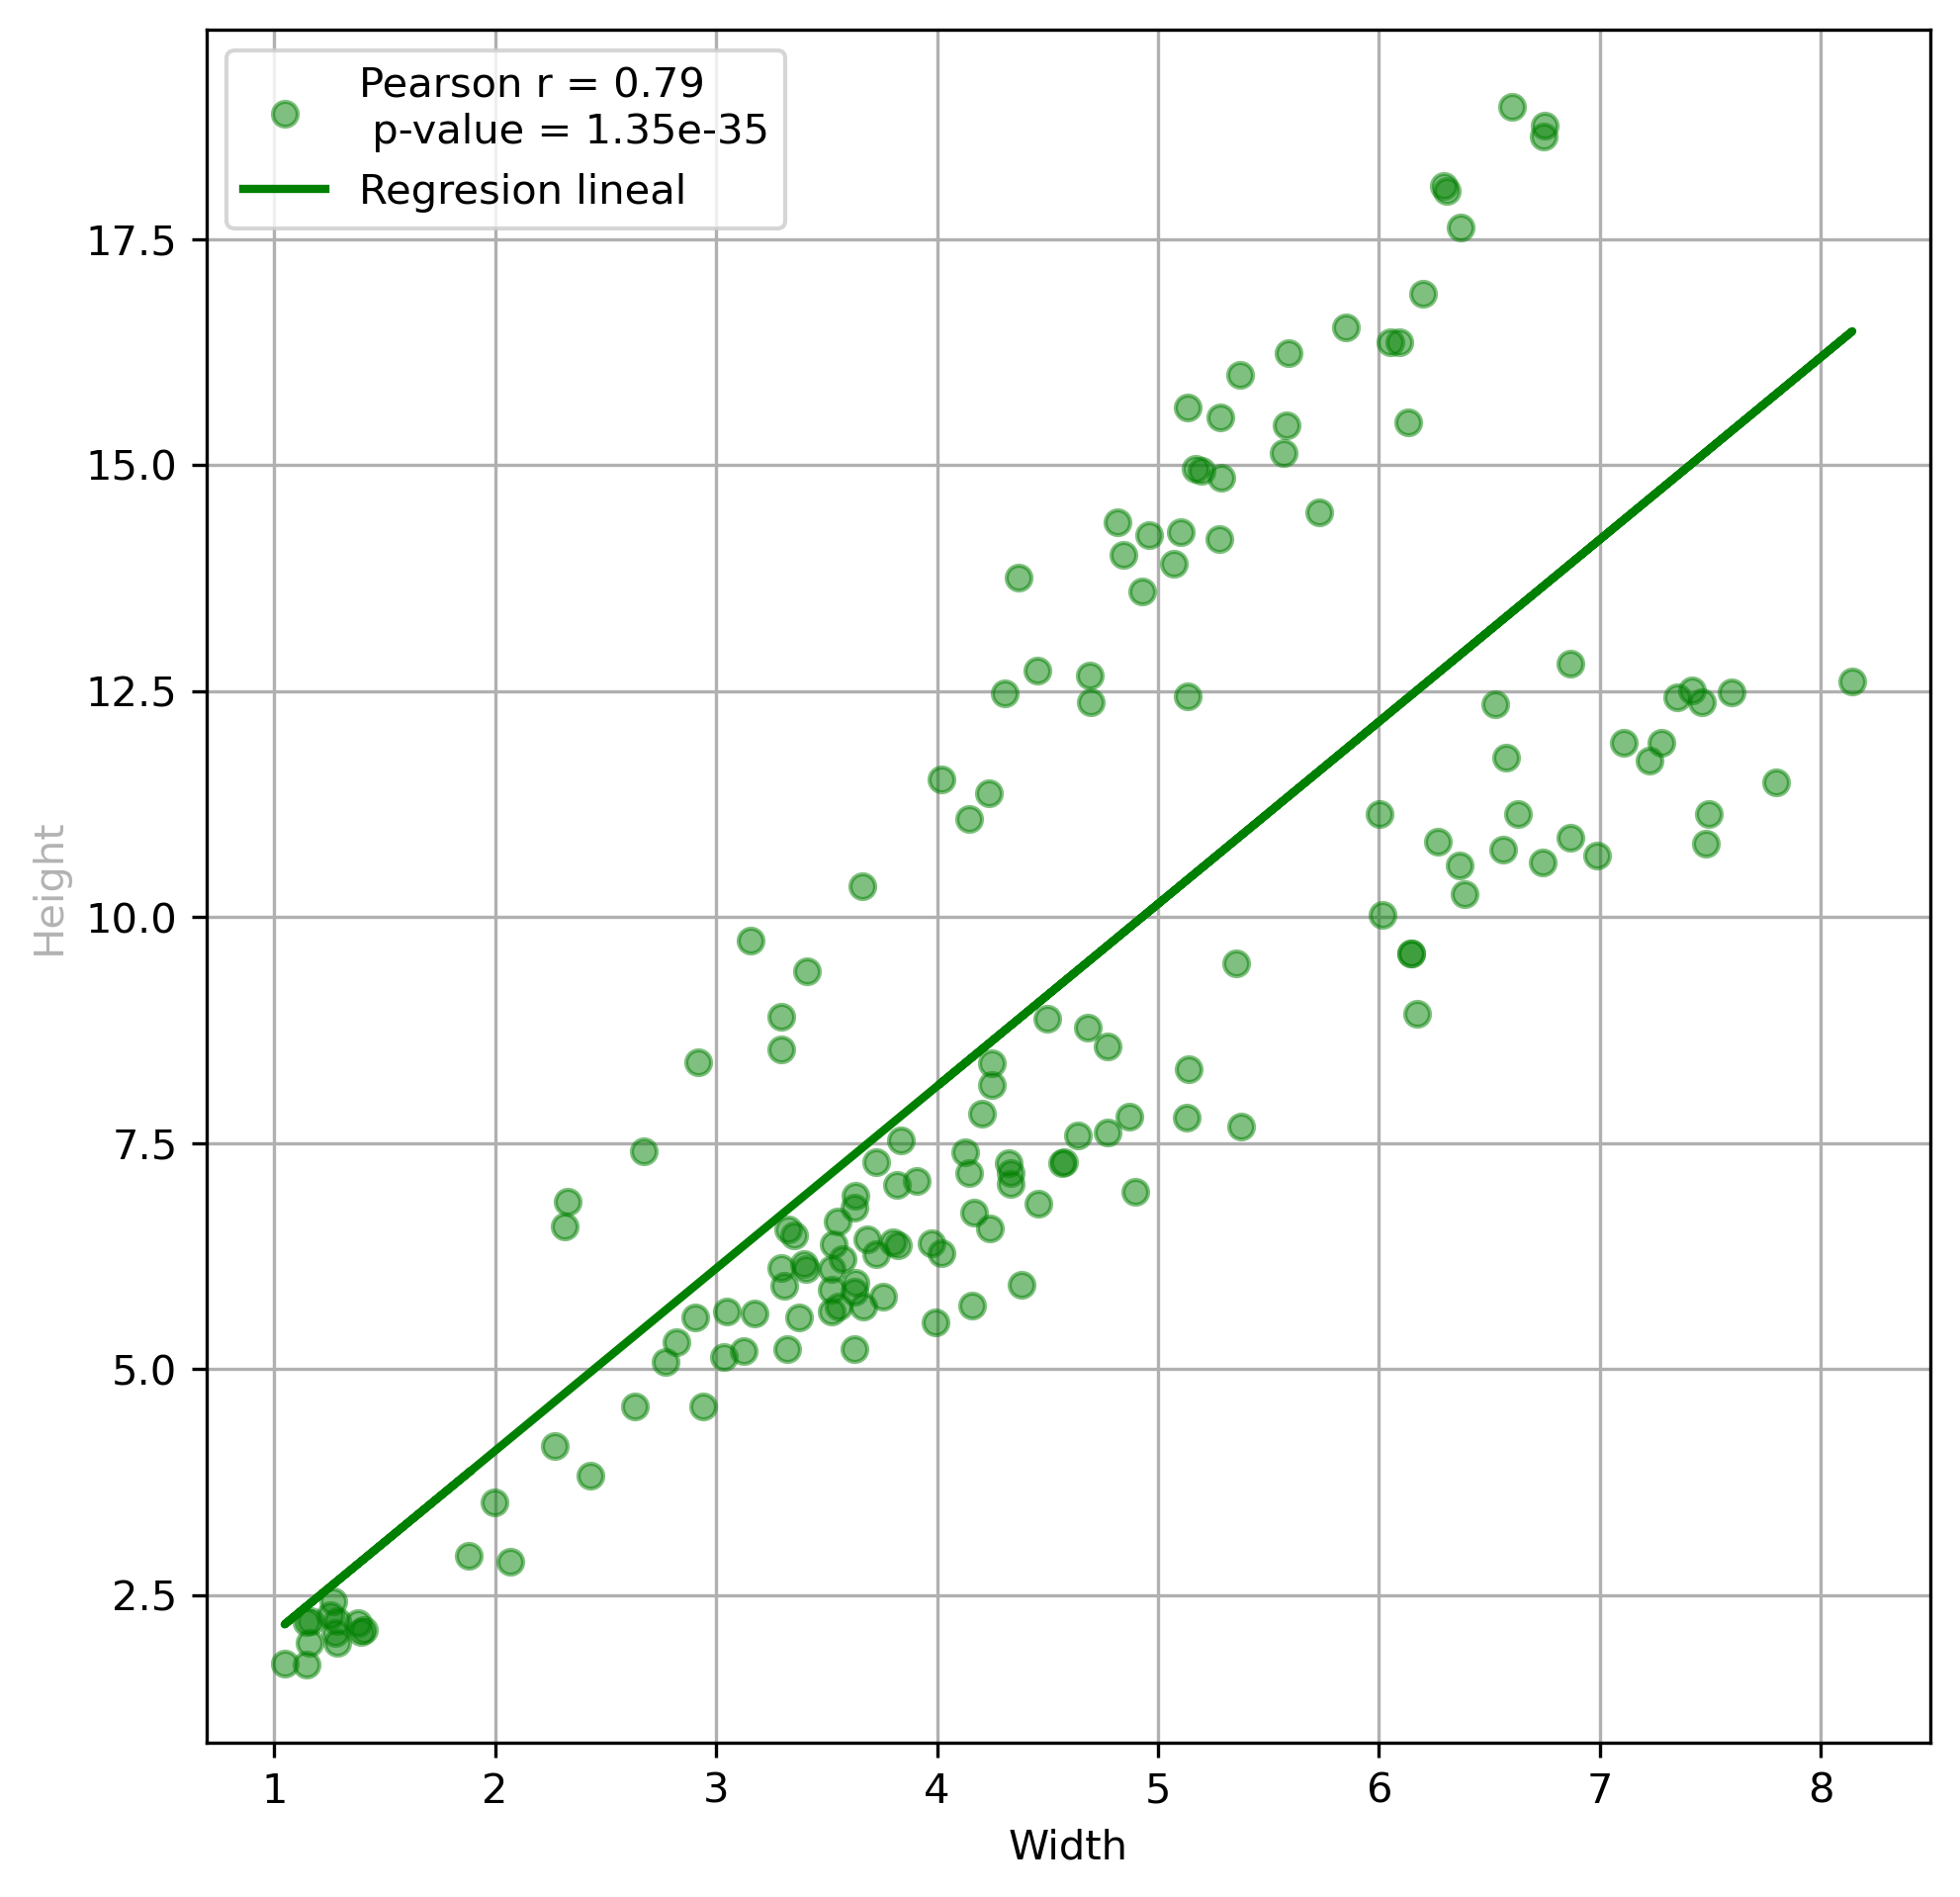

In [ ]:
# S_xx = sum of squares of X = sum((x_i - x_mean)^2)
# Mide la variabilidad total de la variable explicativa (Width)
S_xx = np.sum((width - np.mean(width))**2)

# S_xy = sum of cross products = sum((x_i - x_mean)(y_i - y_mean))
# Mide como covarian conjuntamente Width y Height
S_xy = np.sum((width - np.mean(width)) * (height - np.mean(height)))

# Estimador de la pendiente: beta_1 = S_xy / S_xx
hat_beta_1 = S_xy / S_xx

# Estimador del intercepto: beta_0 = y_mean - beta_1 * x_mean
hat_beta_0 = np.mean(height) - hat_beta_1 * np.mean(width)

# -- Grafico de dispersion con la recta ajustada --
fig, ax = plt.subplots(figsize=(7.5, 7.5), dpi=300)

# stats.pearsonr retorna (coeficiente, p-value); r mide correlacion lineal en [-1, 1]
pearson_r, pearson_pval = stats.pearsonr(width, height)

ax.scatter(width, height, alpha=0.5, color='green',
           label=f'Pearson r = {pearson_r:.2f} \n p-value = {pearson_pval:.2e}', zorder=3)

# Evaluamos la recta en todos los puntos de Width
ax.plot(width, hat_beta_1 * width + hat_beta_0, linewidth=2, color='green',
        label='Regresion lineal', zorder=3)

ax.legend(loc='upper left')
ax.set_xlabel('Width')
ax.set_ylabel('Height', alpha=0.3, zorder=0)
ax.grid()
plt.show()

## Coeficiente de determinación
> Calcule el coeficiente de determinación ($R^2$) del modelo. ¿Qué proporción de la varianza de la altura es explicada por la anchura?

Recordemos que el coeficiente de determinacion probee una noción de la proporción de varianza que explica el modelo de regresión lineal. La formula por la cual uno es capaz de calcular dicho coeficiente es:
$$
R^2 = \frac{SS_R}{SS_T} = 1 - \frac{SS_E}{SS_T}
$$

Donde 
$$
SS_T = SS_R + SS_E
$$

$$
SS_T = \sum_{i=1}^n (y_i - \overline{y})^2
$$
$$
SS_E = SS_T - \widehat{\beta}_1S_{xy} = \sum_{i=1}^n (y_i - \widehat{y}_i)^2
$$


In [54]:
# SS_T = variabilidad total de Height (sin ningún modelo)
SS_T = np.sum((height - np.mean(height))**2)

# SS_E = variabilidad no explicada por el modelo (residuos)
# Equivale a SS_T - beta_1 * S_xy (formula analitica que evita calcular los residuos uno a uno)
SS_E = SS_T - hat_beta_1 * S_xy

# R^2 = fraccion de variabilidad de Height explicada por Width
# Un R^2 cercano a 1 indica mejor ajuste
R2 = 1 - SS_E / SS_T

print(f'R2 = {R2:.3f}')

R2 = 0.629


## Test-t sobre coeficientes
> Calcule los estadísticos $t$ (bilaterales) para los coeficientes $\beta_0$ y $\beta_1$. ¿Qué hipótesis se está testeando en cada caso? ¿Qué puede concluir?

Es posible realizar test de hipótesis sobre los coeficientes de una regresión lineal. En este caso, realizamos un test-t sobre los coeficientes para evaluar cual es la confianza que tenemos sobre el valor del mismo. Para esto planteamos la siguiente prueba para el intercepto:
$$
H_0: \beta_0 = 0
$$
$$
H_a: \beta_0 \neq 0
$$

Y para el coeficiente $\beta_1$:
$$
H_0: \beta_1 = 0
$$
$$
H_a: \beta_1 \neq 0
$$
Notar que puede ser otro valor diferente de 0, pero dejarlo en 0 nos entrega más información

**¿Por qué?**


Para realizar la prueba-t debemos calcular los estadísticos respectivos. Para la prueba sobre $\beta_0$:

$$
T_0 = \frac{\widehat{\beta_0} - \beta_{0,0} (= 0 )}{\sqrt{\widehat{\sigma}^2 \left[ \frac{1}{n} + \frac{\overline{x}^2}{S_{xx}} \right]  }} = \frac{\widehat{\beta_0}}{se(\widehat{\beta}_0)}
$$
Y sobre $\beta_1$:
$$
T_0 = \frac{\widehat{\beta}_1 - \beta_{1,0} (=0)}{\sqrt{\frac{\widehat{\sigma}^2}{S_{xx}}}}  = \frac{\widehat{\beta_1}}{se(\widehat{\beta}_1)}
$$

Recordando que
$$
\widehat{\sigma}^2 = \frac{SS_E}{n-2}
$$
La cual es la varianza estimada del error del modelo ($\epsilon$).

In [55]:
n = len(height)  # numero de observaciones

# varianza estimada del error: sigma^2 = SS_E / (n - 2)
# se divide por n-2 porque se estimaron 2 parametros (beta_0 y beta_1)
hat_sigma_2 = SS_E / (n - 2)

# estadistico T para beta_0: T = beta_0 / se(beta_0)
# el error estandar de beta_0 depende de la varianza del error y de la posicion de x_mean
T_0_beta0 = hat_beta_0 / np.sqrt(hat_sigma_2 * (1/n + np.mean(width)**2 / S_xx))

# estadistico T para beta_1: T = beta_1 / se(beta_1)
# el error estandar de beta_1 depende solo de la varianza del error y de S_xx
T_0_beta1 = hat_beta_1 / np.sqrt(hat_sigma_2 / S_xx)

print(f'T_0_beta0 = {T_0_beta0:.3f}')
print(f'T_0_beta1 = {T_0_beta1:.3f}')

T_0_beta0 = 0.112
T_0_beta1 = 16.303


In [56]:
# Prueba bilateral: p-value = 2 * P(T > |T_0|) bajo H0
# stats.t.sf(x, df) = P(T > x) con df grados de libertad (survival function = 1 - CDF)
# np.abs() asegura que tomamos la cola correcta independientemente del signo del estadistico
p_value_beta0 = 2 * stats.t.sf(np.abs(T_0_beta0), n - 2)  # p-value para la interseccion
p_value_beta1 = 2 * stats.t.sf(np.abs(T_0_beta1), n - 2)  # p-value para la pendiente

print(f'p-value beta0 = {p_value_beta0:.3e}')
print(f'p-value beta1 = {p_value_beta1:.3e}')

p-value beta0 = 9.107e-01
p-value beta1 = 1.348e-35


## ANOVA sobre una regresión Lineal
> Aplique un análisis de varianza sobre el modelo. Interprete el resultado del valor-$p$.

Al igual que el test ANOVA, un análisis de varianza sobre el modelo de regresión lineal nos va a permitir evaluar si es posible relacionar las variables por medio de un modelo de regresión lineal. 

El test se perfila de la siguiente manera
$$
H_0 : \beta_1 = 0
$$
$$
H_a: \beta_1 \neq 0
$$

El cálculo del test se realiza por medio del siguiente estadístico
$$
F_0 = \frac{MS_R}{MS_E}
$$
Donde 
$$
MS_R = \frac{SS_R}{1} = \frac{\widehat{\beta}_1 S_{xy}}{1}
$$
$$
MS_E = \frac{SS_E}{n-2} = \frac{SS_T - \widehat{\beta}_1 SS_{xy}}{n-2}
$$

Y posteriormente rechazamos la hipótesis nula calculando el valor-p mediante una distrubición $f_{1, n-2}$



In [57]:
# MS_R = SS_R / 1 = variabilidad explicada por el modelo (1 grado de libertad en SLR)
# SS_R = beta_1 * S_xy (fraccion de SS_T atribuida a la pendiente)
MS_R = hat_beta_1 * S_xy / 1

# MS_E = SS_E / (n-2) = varianza estimada del error (ya calculada como hat_sigma_2)
MS_E = SS_E / (n - 2)

# F_0 = MS_R / MS_E: si el modelo no aporta nada, ambas cantidades estiman sigma^2 y F_0 ~ 1
# Un F_0 grande indica que el modelo explica mucho mas de lo que se esperaria por azar
F_0 = MS_R / MS_E

print(f'F_0 = {F_0:.3f}')

F_0 = 265.793


In [58]:
# Bajo H0, F_0 sigue una distribucion F con (1, n-2) grados de libertad
# stats.f.sf(x, dfn, dfd) = P(F > x) = p-value de cola superior
p_value_F = stats.f.sf(F_0, 1, n - 2)

print(f'p-value F = {p_value_F:.3e}')

p-value F = 1.348e-35


## Intervalos de confianza en Regresión Lineal
> Calcule el intervalo de confianza del 95\% para la respuesta media $\mu_{Y|x_0}$ en varios puntos $x_0$ del predictor. Grafique nuevamente el modelo incluyendo estos intervalos de confianza.

Un concepto importante a tener en cuenta es que los modelos nunca son perfectos. En particular, George E. P. Box (estadístico británico) menciona
> En esencia , todos los modelos están equivocados, pero algunos son útiles.

Por lo cual, es necesario incorporar un poco más de utilidad a los modelos al agregar la incertidumbre del modelo con el fin de estar al tanto de este. Existen muchas formas para realizar esto, existen métodos de
- Boostraping: https://towardsdatascience.com/linear-regression-with-bootstrapping-4924c05d2a9/
- Programación Probabilistica: https://www.pymc.io/projects/docs/en/stable/learn/core_notebooks/GLM_linear.html
Pero en este caso analizaremos los intervalos de confianza desde el punto de vista analítico, incorportando las distribuciones de los parámetros del modelo.

Recordemos que: 
$$
\mathbb{E}[Y|x_0] = \mu_{Y|x_0 } = \beta_0 + \beta_1 x_0 
$$
Dado que estimamos los parámetros, tenemos:
$$
\mathbb{E}[Y|x_0] = \widehat{\mu}_{Y|x_0 } = \widehat{\beta}_0 + \widehat{\beta}_1 x_0 
$$

La varianza del modelo viene dada por $\mu_{Y|x_0 }$: 
$$
\mathbb{Var}(\widehat{\mu}_{Y|x_0 }) = \sigma^2 \left[ \frac{1}{n} + \frac{(x_0 -\overline{x})^2}{S_{xx}}  \right]
$$

Dado a que $\beta_0$, $\beta_1$ y $\widehat{\mu}_{Y|x_0 }$ poseen una distribución normal, y utilizando $\widehat{\sigma}^2$ como estimador de la varianza del error, podemos definir:
$$
\frac{\widehat{\mu}_{Y|x_0 } - \mu_{Y|x_0 }}{ \sqrt{\widehat{\sigma}^2 \left[ \frac{1}{n} + \frac{(x_0 -\overline{x})^2}{S_{xx}}  \right]}}
$$
Como una variable aleatoria que sigue una distribución $t$ con $n-2$ grados de libertad. Así, podemos definir el intervalo de confianza $100(1-\alpha)\%$ para la respuesta media como:

$$
\widehat{\mu}_{Y|x_0 } - t_{\alpha/2, n-2} \sqrt{\widehat{\sigma}^2 \left[ \frac{1}{n} + \frac{(x_0 -\overline{x})^2}{S_{xx}}  \right]} \leq \mu_{Y|x_0} \leq \widehat{\mu}_{Y|x_0 } + t_{\alpha/2, n-2} \sqrt{\widehat{\sigma}^2 \left[ \frac{1}{n} + \frac{(x_0 -\overline{x})^2}{S_{xx}}  \right]} 
$$


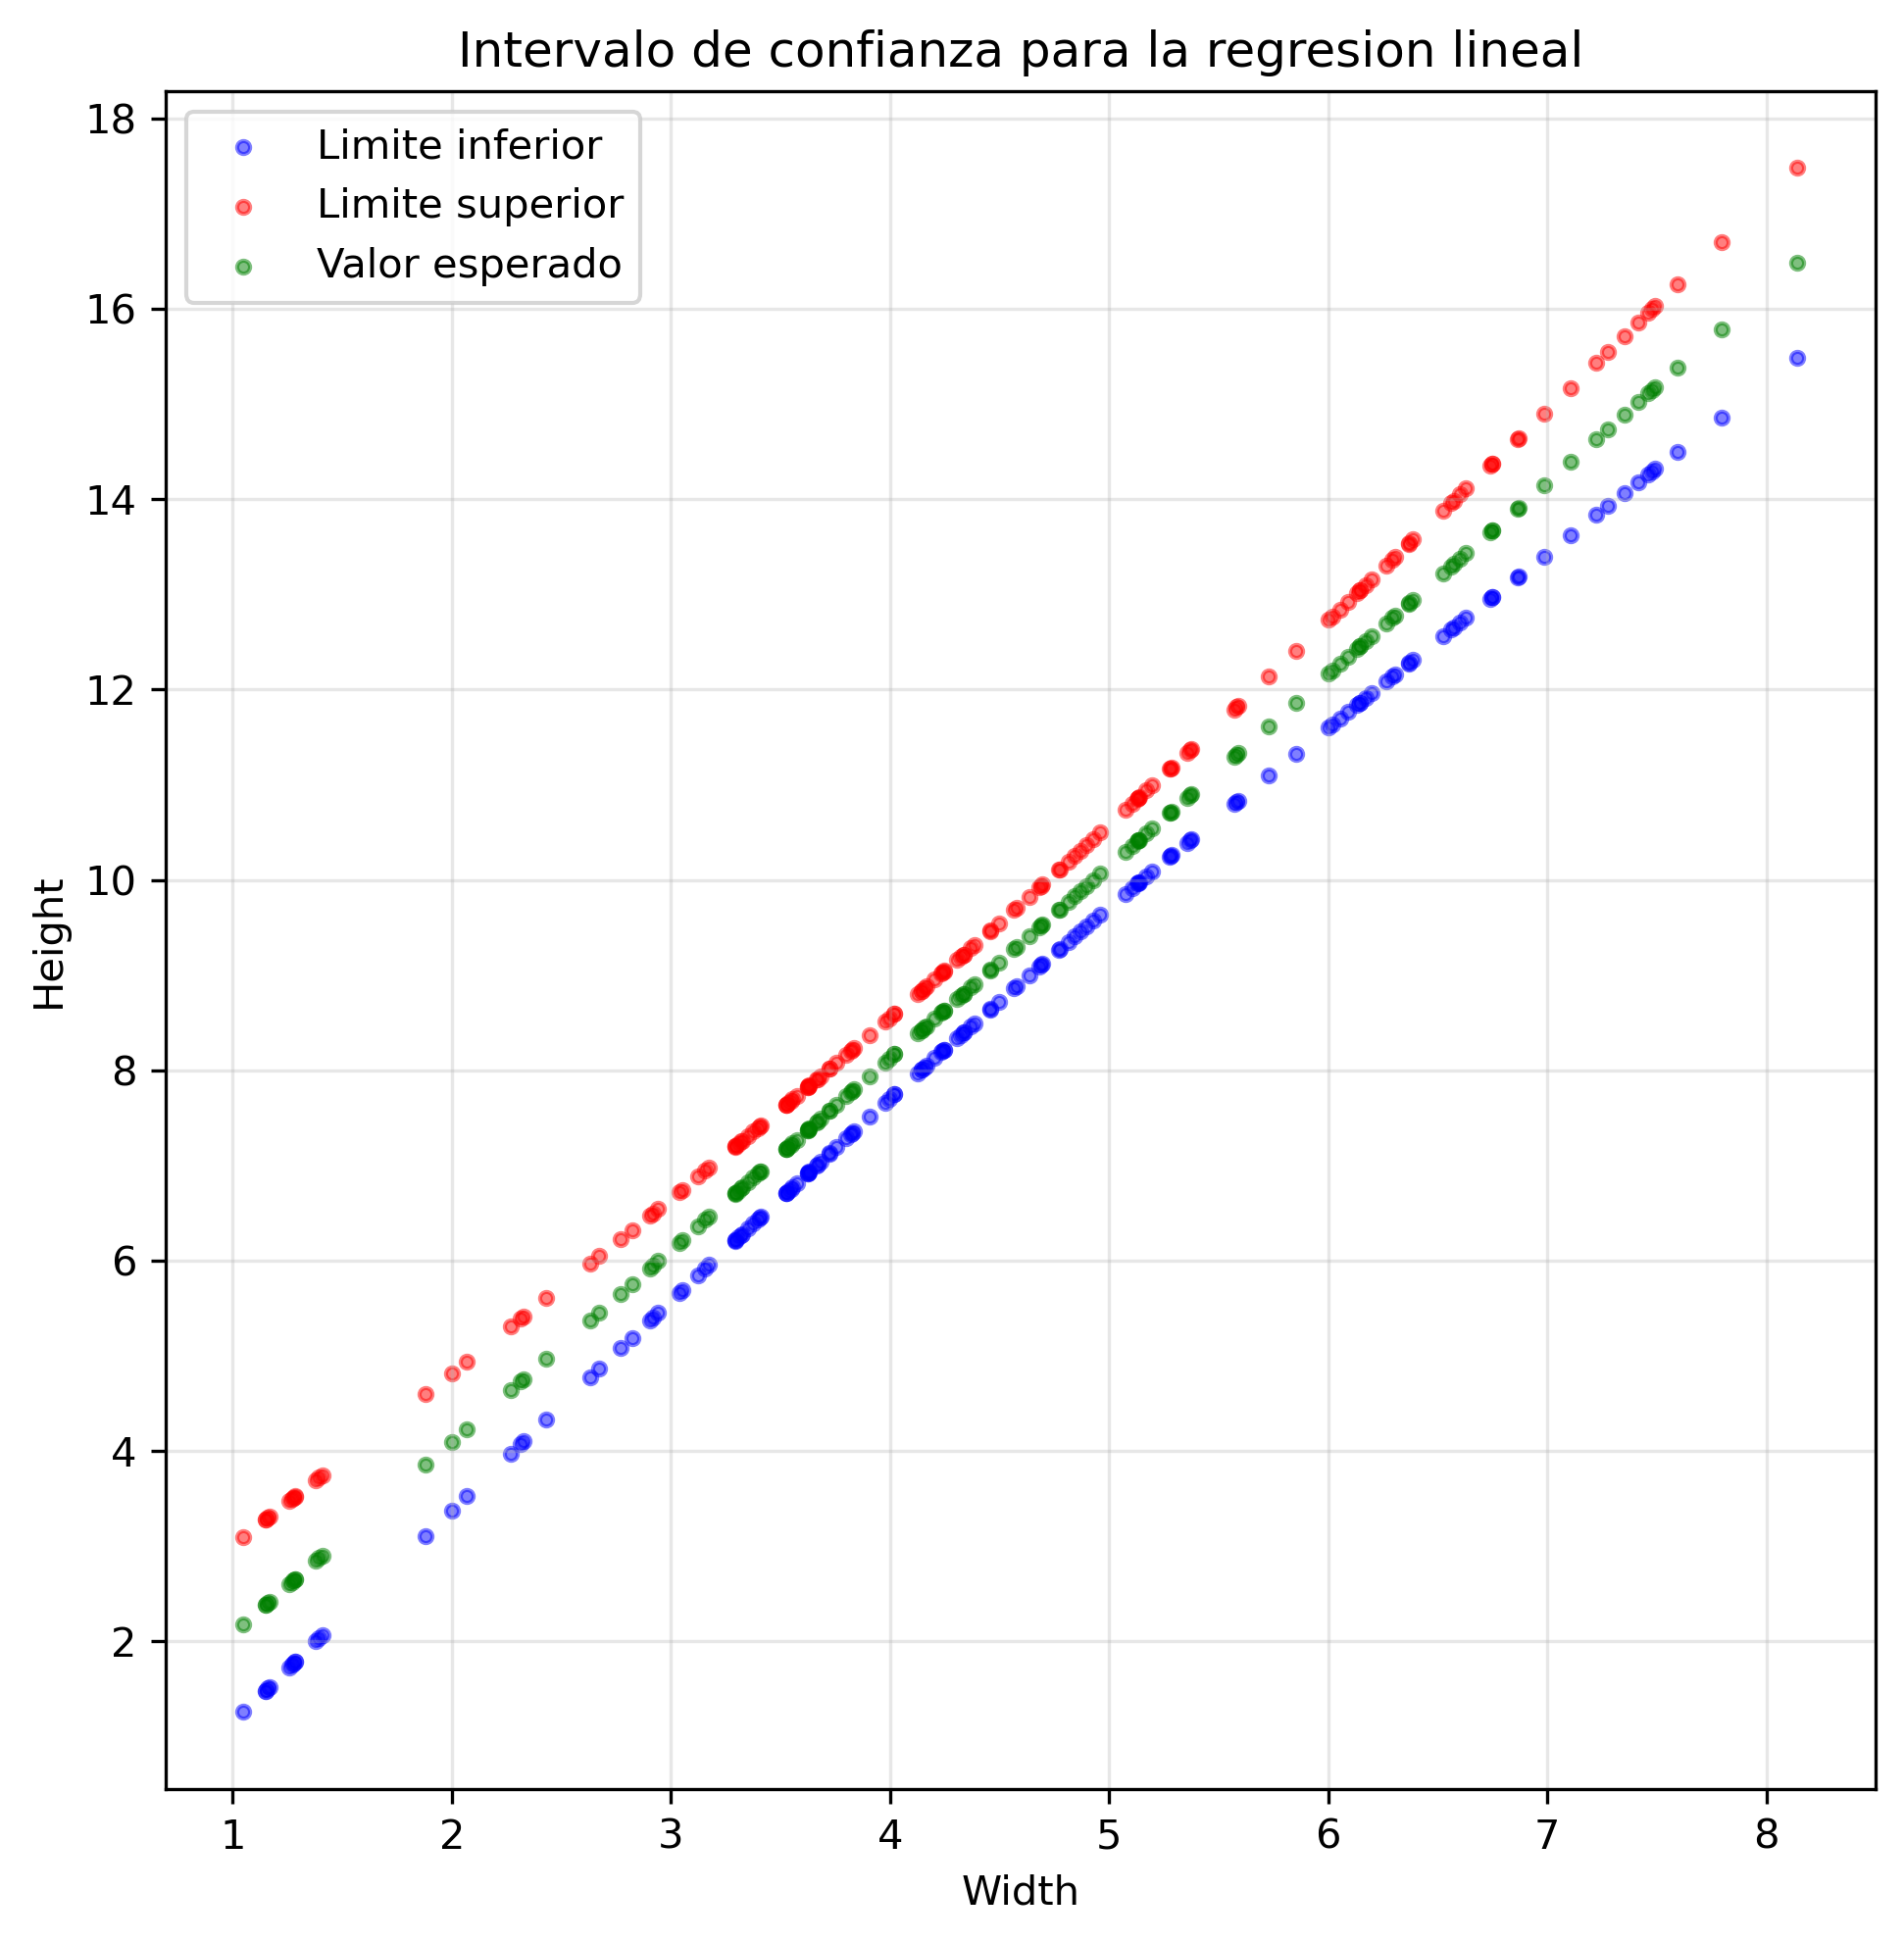

In [ ]:
def uncertain_regresion(beta_0, beta_1, x_0, xbar, sigma_2, n, S_xx, alpha):
    """
    Intervalo de confianza para la RESPUESTA MEDIA en x_0: E[Y | x_0] = mu_{Y|x_0}.


    Parametros
    ----------
    beta_0 : float  -- intercepto estimado
    beta_1 : float  -- pendiente estimada
    x_0    : float o array  -- valor(es) del predictor donde evaluar el IC
    xbar   : float  -- media muestral de x
    sigma_2: float  -- varianza estimada del error (hat_sigma^2 = SS_E/(n-2))
    n      : int    -- numero de observaciones
    S_xx   : float  -- suma de cuadrados de x
    alpha  : float  -- nivel de significancia (ej. 0.05 para IC del 95%)

    Retorna
    -------
    (Lower, Upper) : limites del intervalo de confianza
    """
    mu_y_x0 = beta_0 + beta_1 * x_0  # valor predicho de Height en x_0

    # valor critico t_{alpha/2, n-2}: cuantil de la t con n-2 grados de libertad
    t_alpha_2 = stats.t.ppf(1 - alpha / 2, n - 2)

    # varianza de mu_hat: crece cuando x_0 se aleja de xbar (menos informacion en los extremos)
    var = sigma_2 * (1/n + (x_0 - xbar)**2 / S_xx)

    Upper = mu_y_x0 + t_alpha_2 * np.sqrt(var)
    Lower = mu_y_x0 - t_alpha_2 * np.sqrt(var)
    return Lower, Upper


# -- Calculo del IC para cada valor observado de Width --
alpha = 0.05
x_0 = width
xbar = np.mean(width)
sigma_2 = hat_sigma_2
n = len(width)
S_xx = np.sum((width - np.mean(width))**2)
beta_0 = hat_beta_0
beta_1 = hat_beta_1
Lower, Upper = uncertain_regresion(beta_0, beta_1, x_0, xbar, sigma_2, n, S_xx, alpha)

fig, ax = plt.subplots(1, figsize=(7.5, 7.5), dpi=300, sharey=True)

# Graficamos limite inferior, superior y valor predicho para cada x_0
for i in range(len(x_0)):
    ax.scatter(x_0[i], Lower[i], color='blue', alpha=0.5, label='Limite inferior', s=10)
    ax.scatter(x_0[i], Upper[i], color='red', alpha=0.5, label='Limite superior', s=10)
    ax.scatter(x_0[i], beta_0 + beta_1 * x_0[i], color='green', alpha=0.5, label='Valor esperado', s=10)

# Eliminamos etiquetas duplicadas en la leyenda
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper left')

ax.set_xlabel('Width')
ax.set_ylabel('Height')
ax.set_title('Intervalo de confianza para la regresion lineal')
ax.grid(alpha=0.3)
plt.show()

Y de la misma forma, se puede realizar una estiamción de la incertidumbre en una nueva predicción del modelo. Lo que nos permite realizar desiciones informadas en la incertidumbre de los datos.

En este caso, lam varianza viene dada por:

$$
\mathbb{Var}(Y_0 - \widehat{Y}_0) =  \sigma^2 \left[ 1 + \frac{1}{n} + \frac{(x_0 -\overline{x})^2}{S_{xx}}  \right]
$$
La cual viene dada por el error de estimación. Luego, definimos nuestro intervalo de confianza mediante el siguiente valor:

$$
\frac{Y_0 - \widehat{Y}_0}{ \sqrt{ \sigma^2 \left[ 1 + \frac{1}{n} + \frac{(x_0 -\overline{x})^2}{S_{xx}}  \right]}}
$$

La cual viene dada por una distribución $t$ con $n-2$ grados de libertad. Así, los intervalos de confianza $(100 - \alpha)\%$ para una nueva predicción vienen dados por:

$$
\widehat{y}_0 - t_{\alpha/2, n-2} \sqrt{ \sigma^2 \left[ 1 + \frac{1}{n} + \frac{(x_0 -\overline{x})^2}{S_{xx}}  \right]} \le Y_0 \le \widehat{y}_0 + t_{\alpha/2, n-2} \sqrt{ \sigma^2 \left[ 1 + \frac{1}{n} + \frac{(x_0 -\overline{x})^2}{S_{xx}}  \right]}
$$

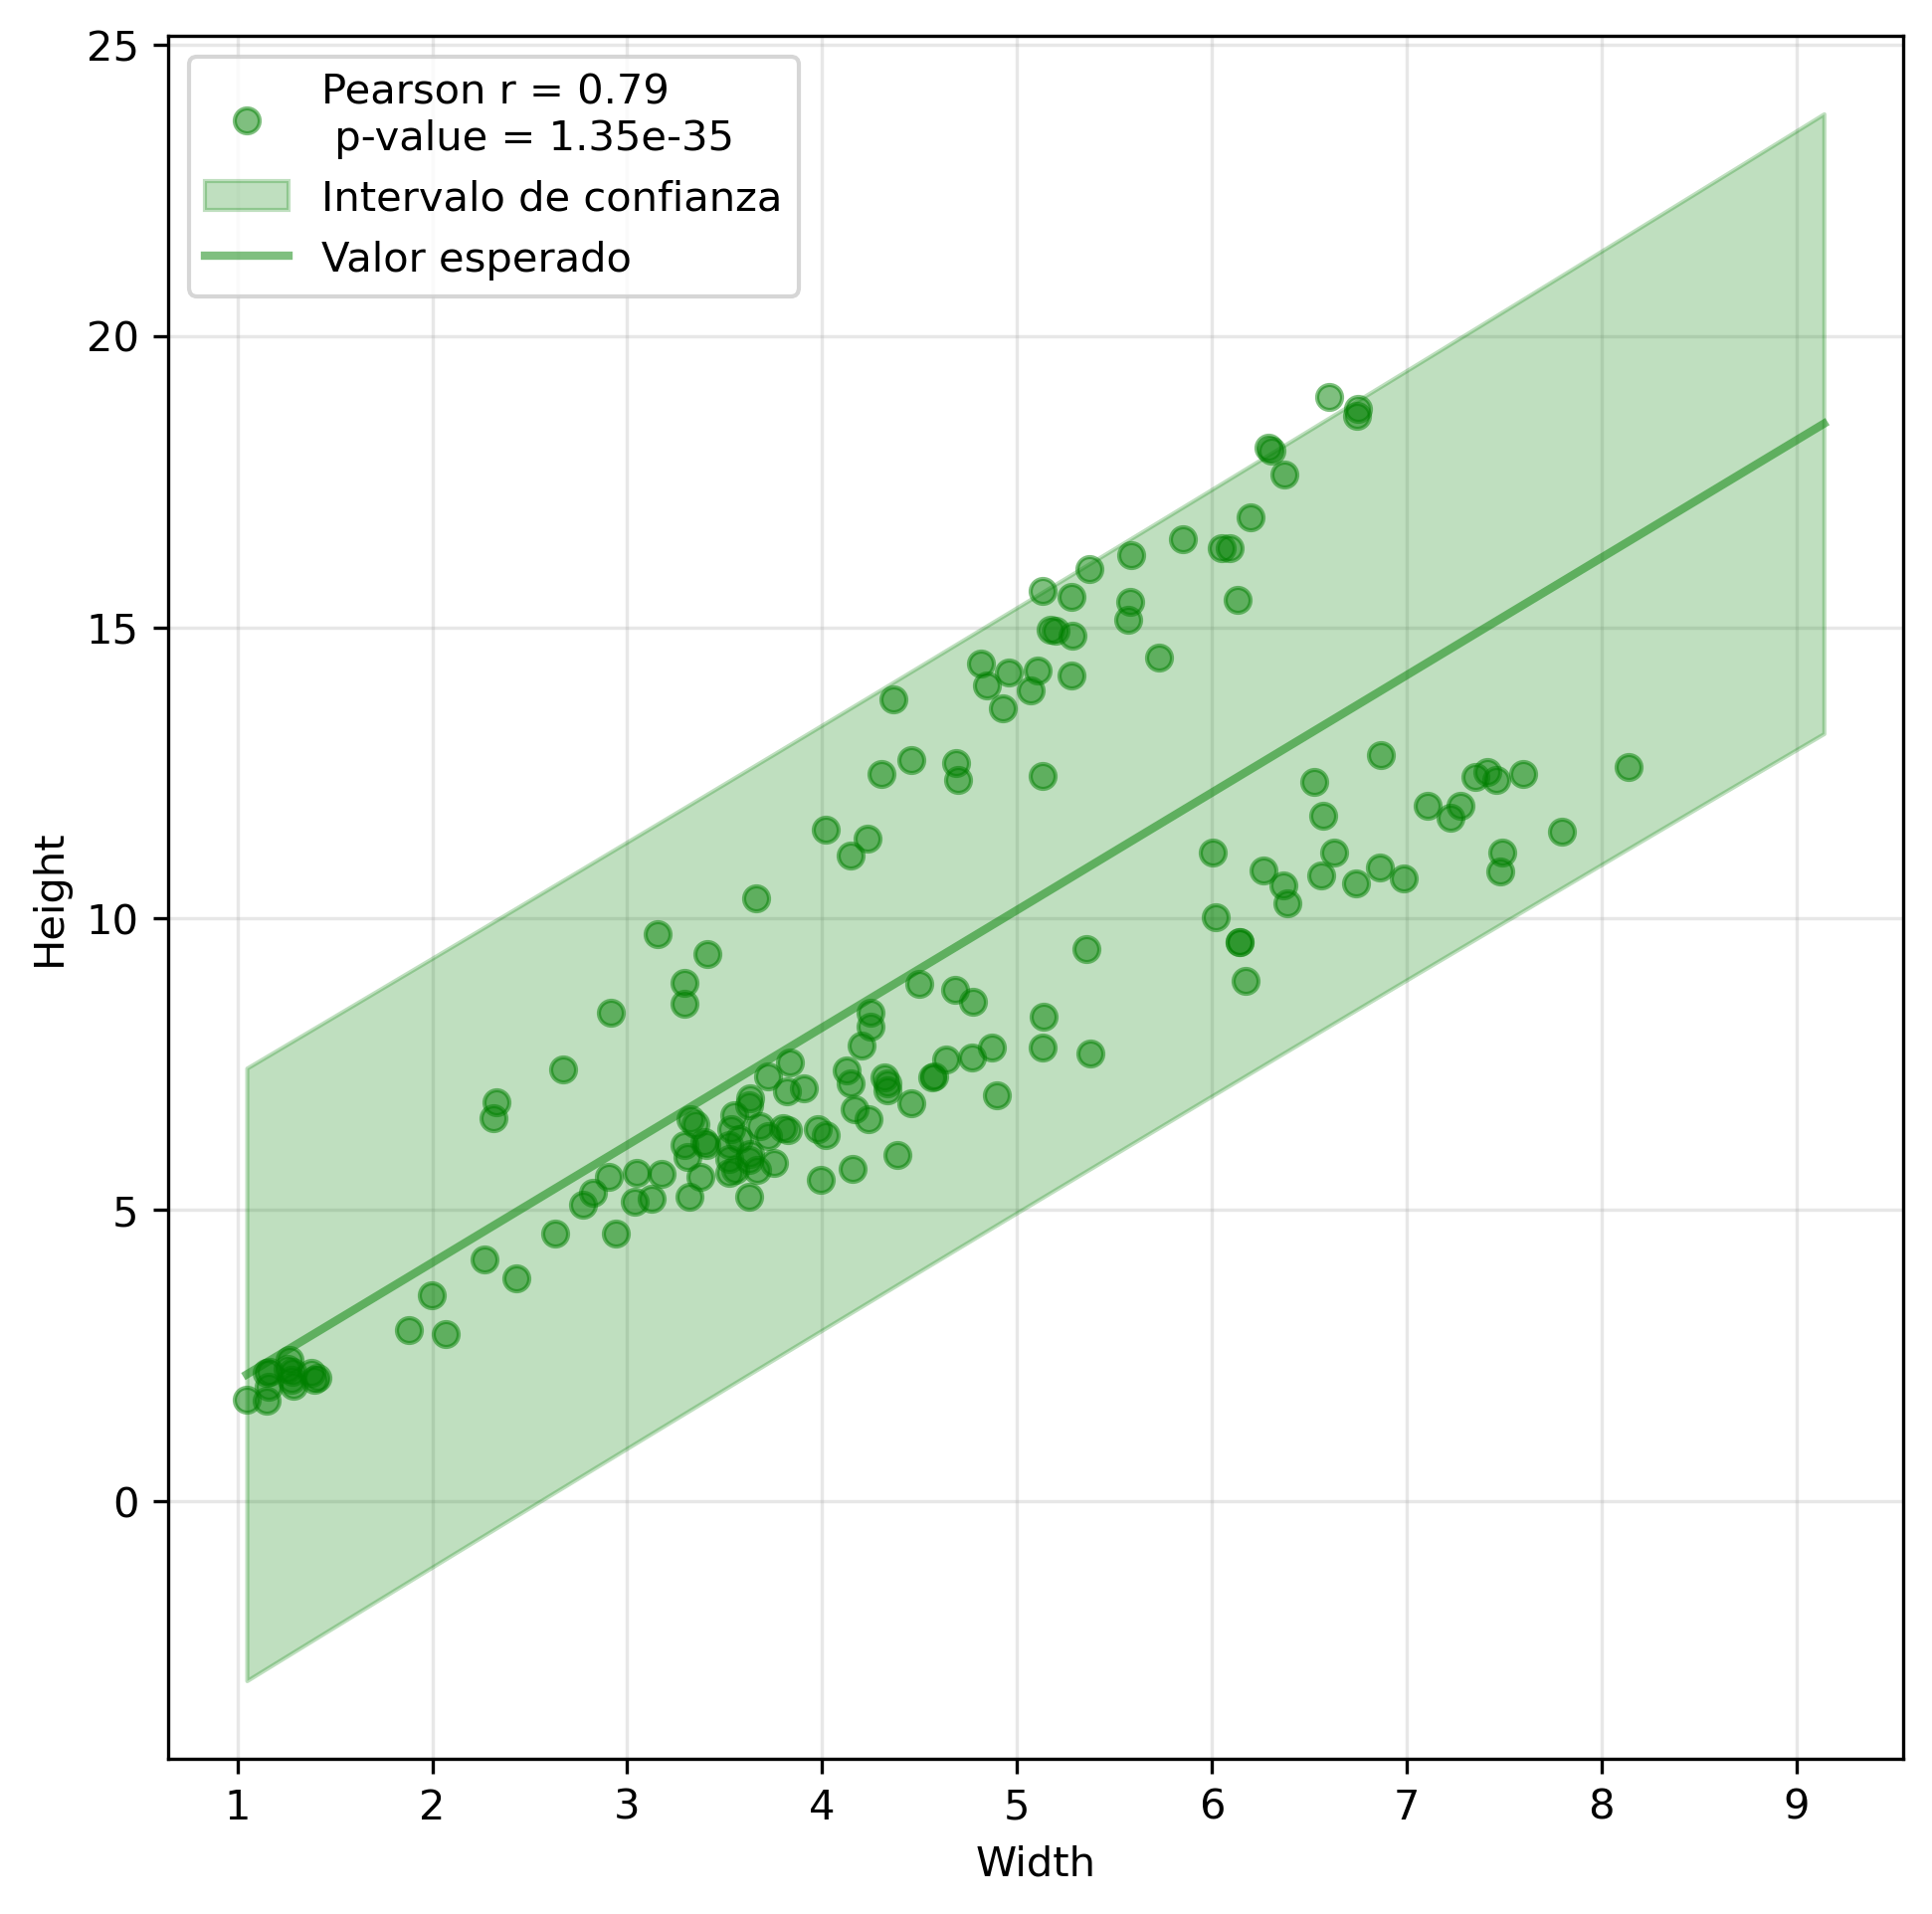

In [60]:
def uncertain_new_value(beta_0, beta_1, x_0, xbar, sigma_2, n, S_xx, alpha):
    """
    Intervalo de PREDICCION para una nueva observacion Y_0 en x_0.

    A diferencia del IC de la respuesta media, este incluye la variabilidad
    propia de una nueva observacion individual (termino '+1' en la varianza),
    por lo que siempre es mas ancho que el IC de la media.

    Parametros
    ----------
    beta_0 : float  -- intercepto estimado
    beta_1 : float  -- pendiente estimada
    x_0    : float o array  -- valor(es) del predictor para la nueva observacion
    xbar   : float  -- media muestral de x
    sigma_2: float  -- varianza estimada del error
    n      : int    -- numero de observaciones
    S_xx   : float  -- suma de cuadrados de x
    alpha  : float  -- nivel de significancia

    Retorna
    -------
    (Lower, Upper) : limites del intervalo de prediccion
    """
    mu_y_x0 = beta_0 + beta_1 * x_0  # valor predicho

    t_alpha_2 = stats.t.ppf(1 - alpha / 2, n - 2)

    # El '+1' adicional respecto al IC de la media captura la variabilidad
    # de la nueva observacion alrededor de su media
    var = sigma_2 * (1 + 1/n + (x_0 - xbar)**2 / S_xx)

    Upper = mu_y_x0 + t_alpha_2 * np.sqrt(var)
    Lower = mu_y_x0 - t_alpha_2 * np.sqrt(var)
    return Lower, Upper


# Usamos una grilla uniforme de x_0 para que la banda sea suave al graficar
alpha = 0.05
x_0 = np.linspace(width.min(), width.max() + 1, 100)
xbar = np.mean(width)
sigma_2 = hat_sigma_2
n = len(width)
S_xx = np.sum((width - np.mean(width))**2)
beta_0 = hat_beta_0
beta_1 = hat_beta_1
Lower, Upper = uncertain_new_value(beta_0, beta_1, x_0, xbar, sigma_2, n, S_xx, alpha)

fig, ax = plt.subplots(1, figsize=(7.5, 7.5), dpi=300)

ax.scatter(width, height, alpha=0.5, color='green',
           label=f'Pearson r = {pearson_r:.2f} \n p-value = {pearson_pval:.2e}', zorder=3)

# fill_between sombrea la region entre Lower y Upper a lo largo de x_0
ax.fill_between(x_0, Lower, Upper, color='green', alpha=0.25,
                label='Intervalo de confianza', zorder=2)

ax.plot(x_0, beta_0 + beta_1 * x_0, color='green', alpha=0.5,
        label='Valor esperado', linewidth=2)

ax.grid(alpha=0.3, zorder=0)
ax.set_xlabel('Width')
ax.set_ylabel('Height')
ax.legend(loc='upper left')
plt.show()

## Regresión Lineal Python

Repita todo lo anterior utilizando la función [OLS](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html) de la librería `statsmodels`. ¿Coinciden los resultados? Discuta brevemente cualquier diferencia observada.

In [61]:
from statsmodels.api import OLS

# sm.add_constant agrega una columna de unos a Width para estimar el intercepto beta_0
# sin ella, statsmodels ajustaria una recta que pasa forzosamente por el origen
modelo_ols = OLS(height, sm.add_constant(width)).fit()

# .summary() imprime la tabla completa: coeficientes, errores estandar, t, p-values,
# R^2, F-statistic, pruebas de normalidad de residuos (Omnibus, Jarque-Bera), etc.
print(modelo_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                 Height   R-squared:                       0.629
Model:                            OLS   Adj. R-squared:                  0.626
Method:                 Least Squares   F-statistic:                     265.8
Date:                Mon, 27 Apr 2026   Prob (F-statistic):           1.35e-35
Time:                        00:47:52   Log-Likelihood:                -377.76
No. Observations:                 159   AIC:                             759.5
Df Residuals:                     157   BIC:                             765.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0657      0.584      0.112      0.9

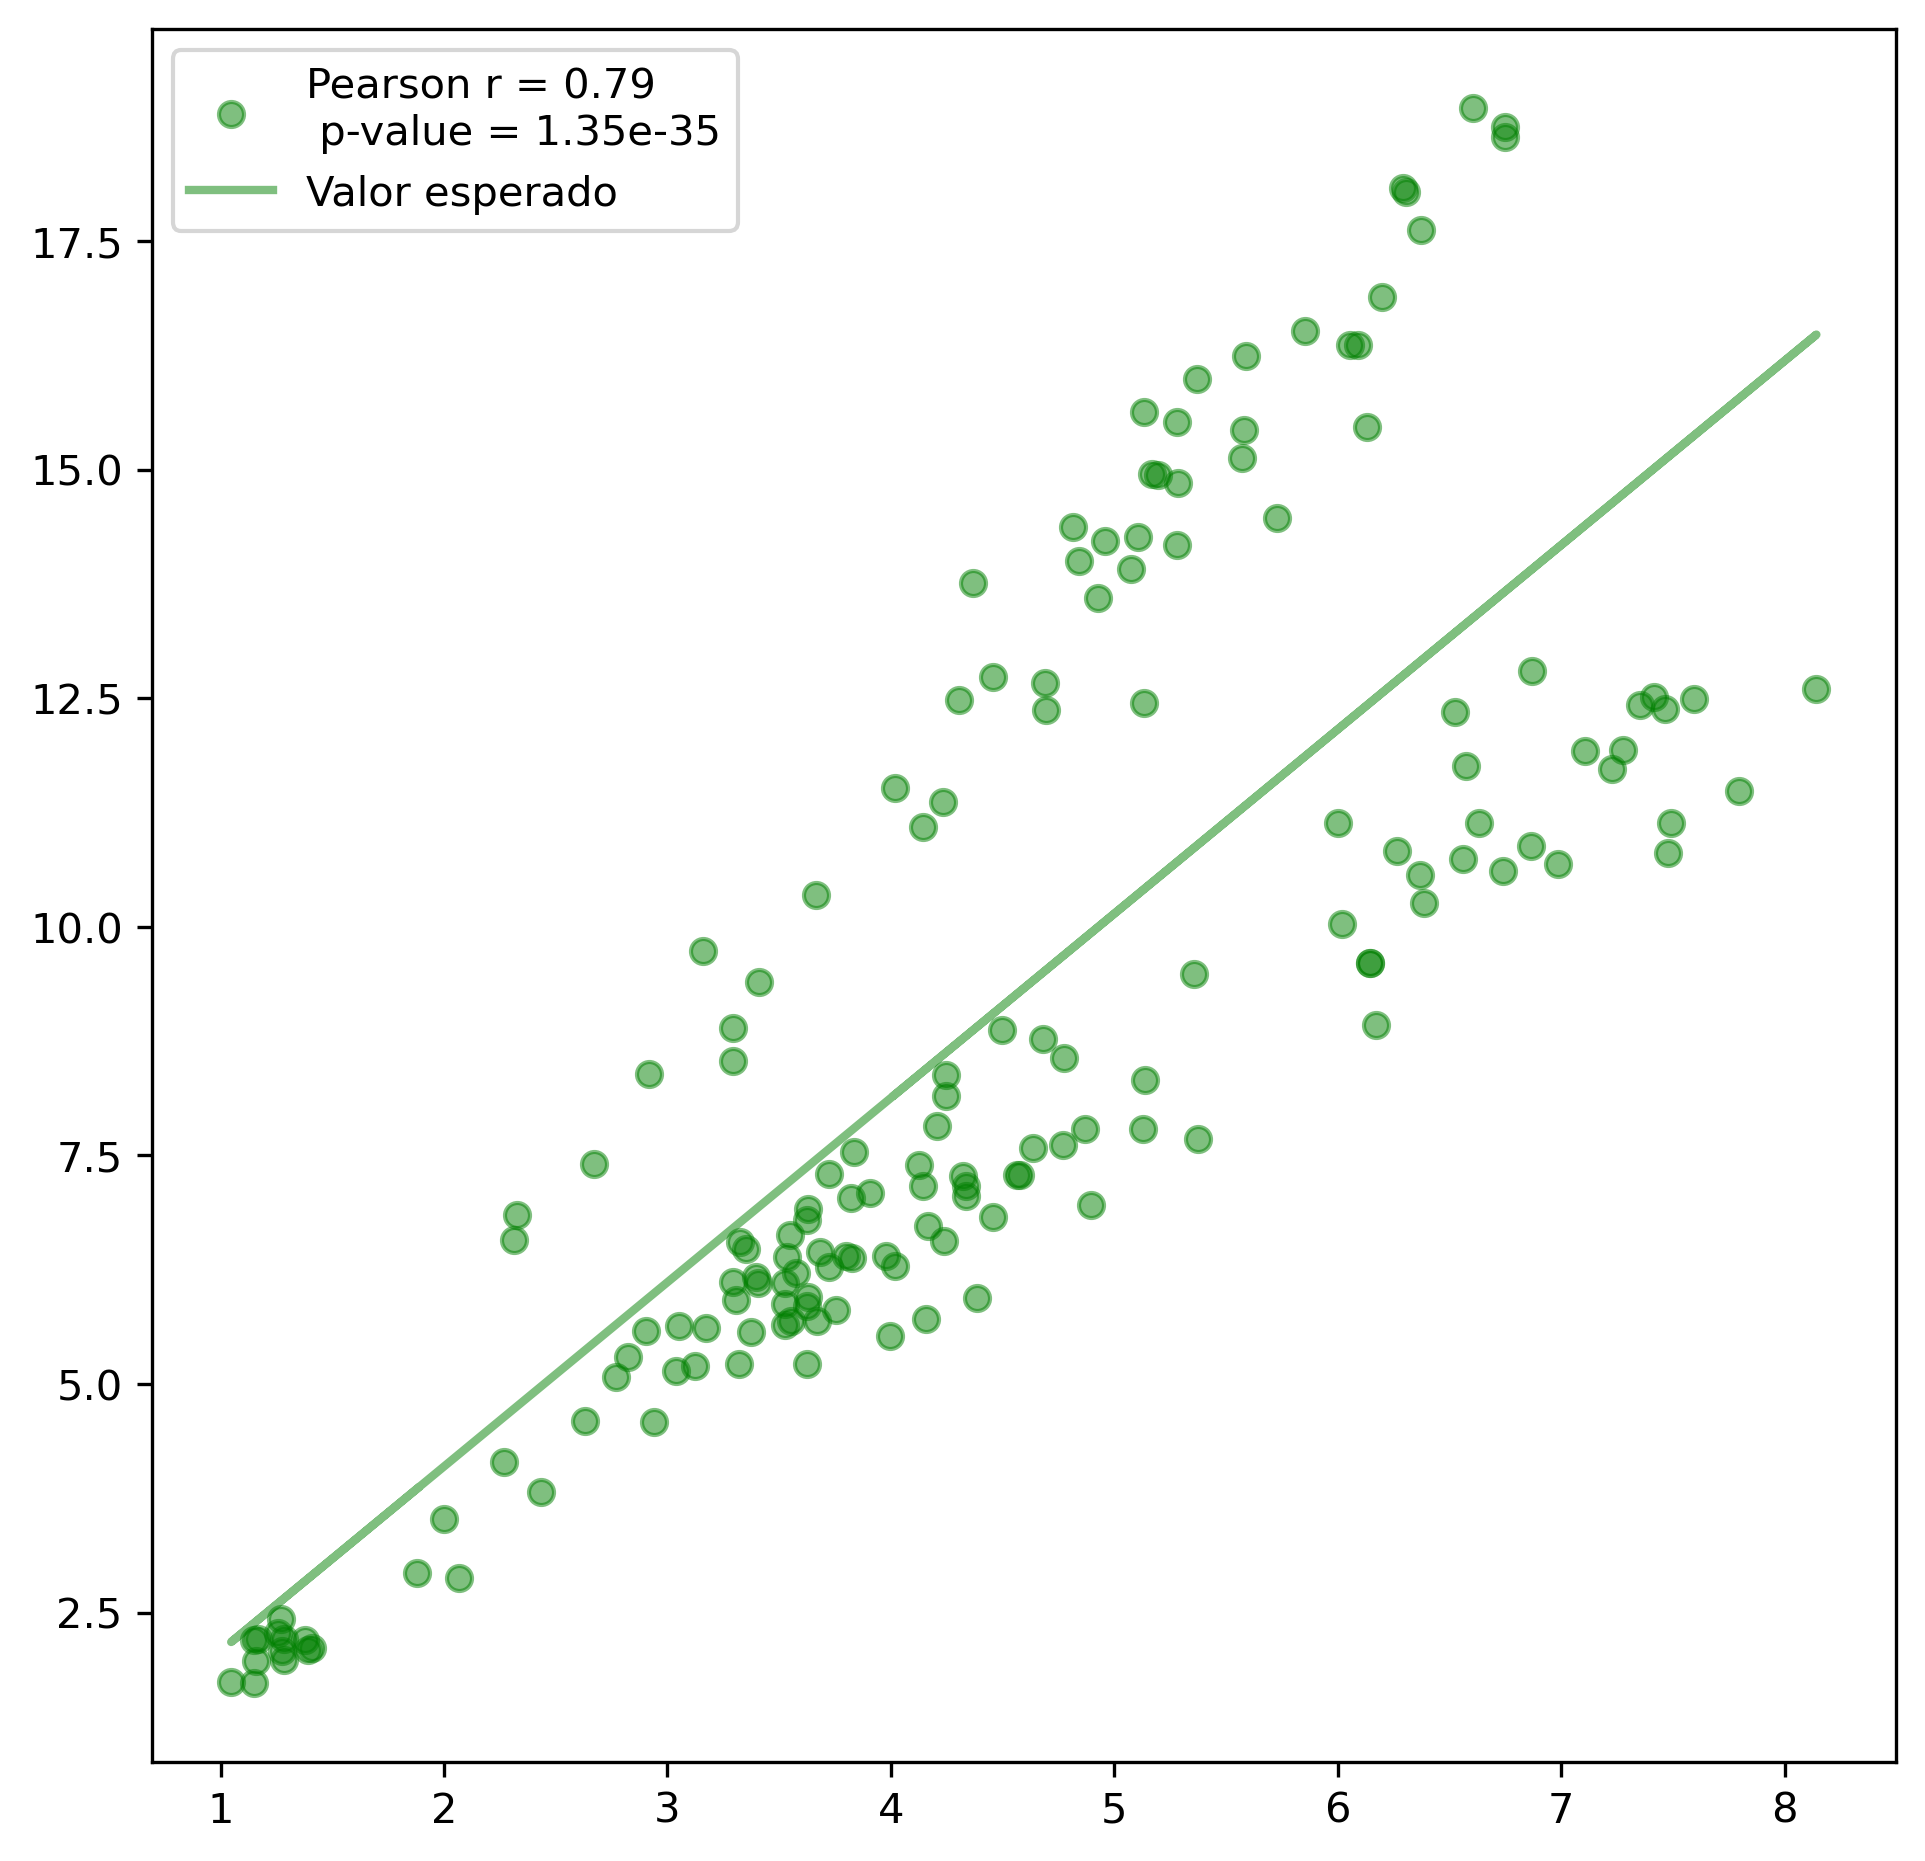

In [62]:
fig, ax = plt.subplots(1, figsize=(7.5, 7.5), dpi=300)

ax.scatter(width, height, alpha=0.5, color='green',
           label=f'Pearson r = {pearson_r:.2f} \n p-value = {pearson_pval:.2e}', zorder=3)

# modelo_ols.params es un Series con indice ['const', 'Width']
# accedemos a cada coeficiente por nombre para mayor claridad
params = modelo_ols.params
ax.plot(width, params['const'] + params['Width'] * width,
        color='green', alpha=0.5, label='Valor esperado', linewidth=2)

ax.legend()

Text(0, 0.5, 'Residuos')

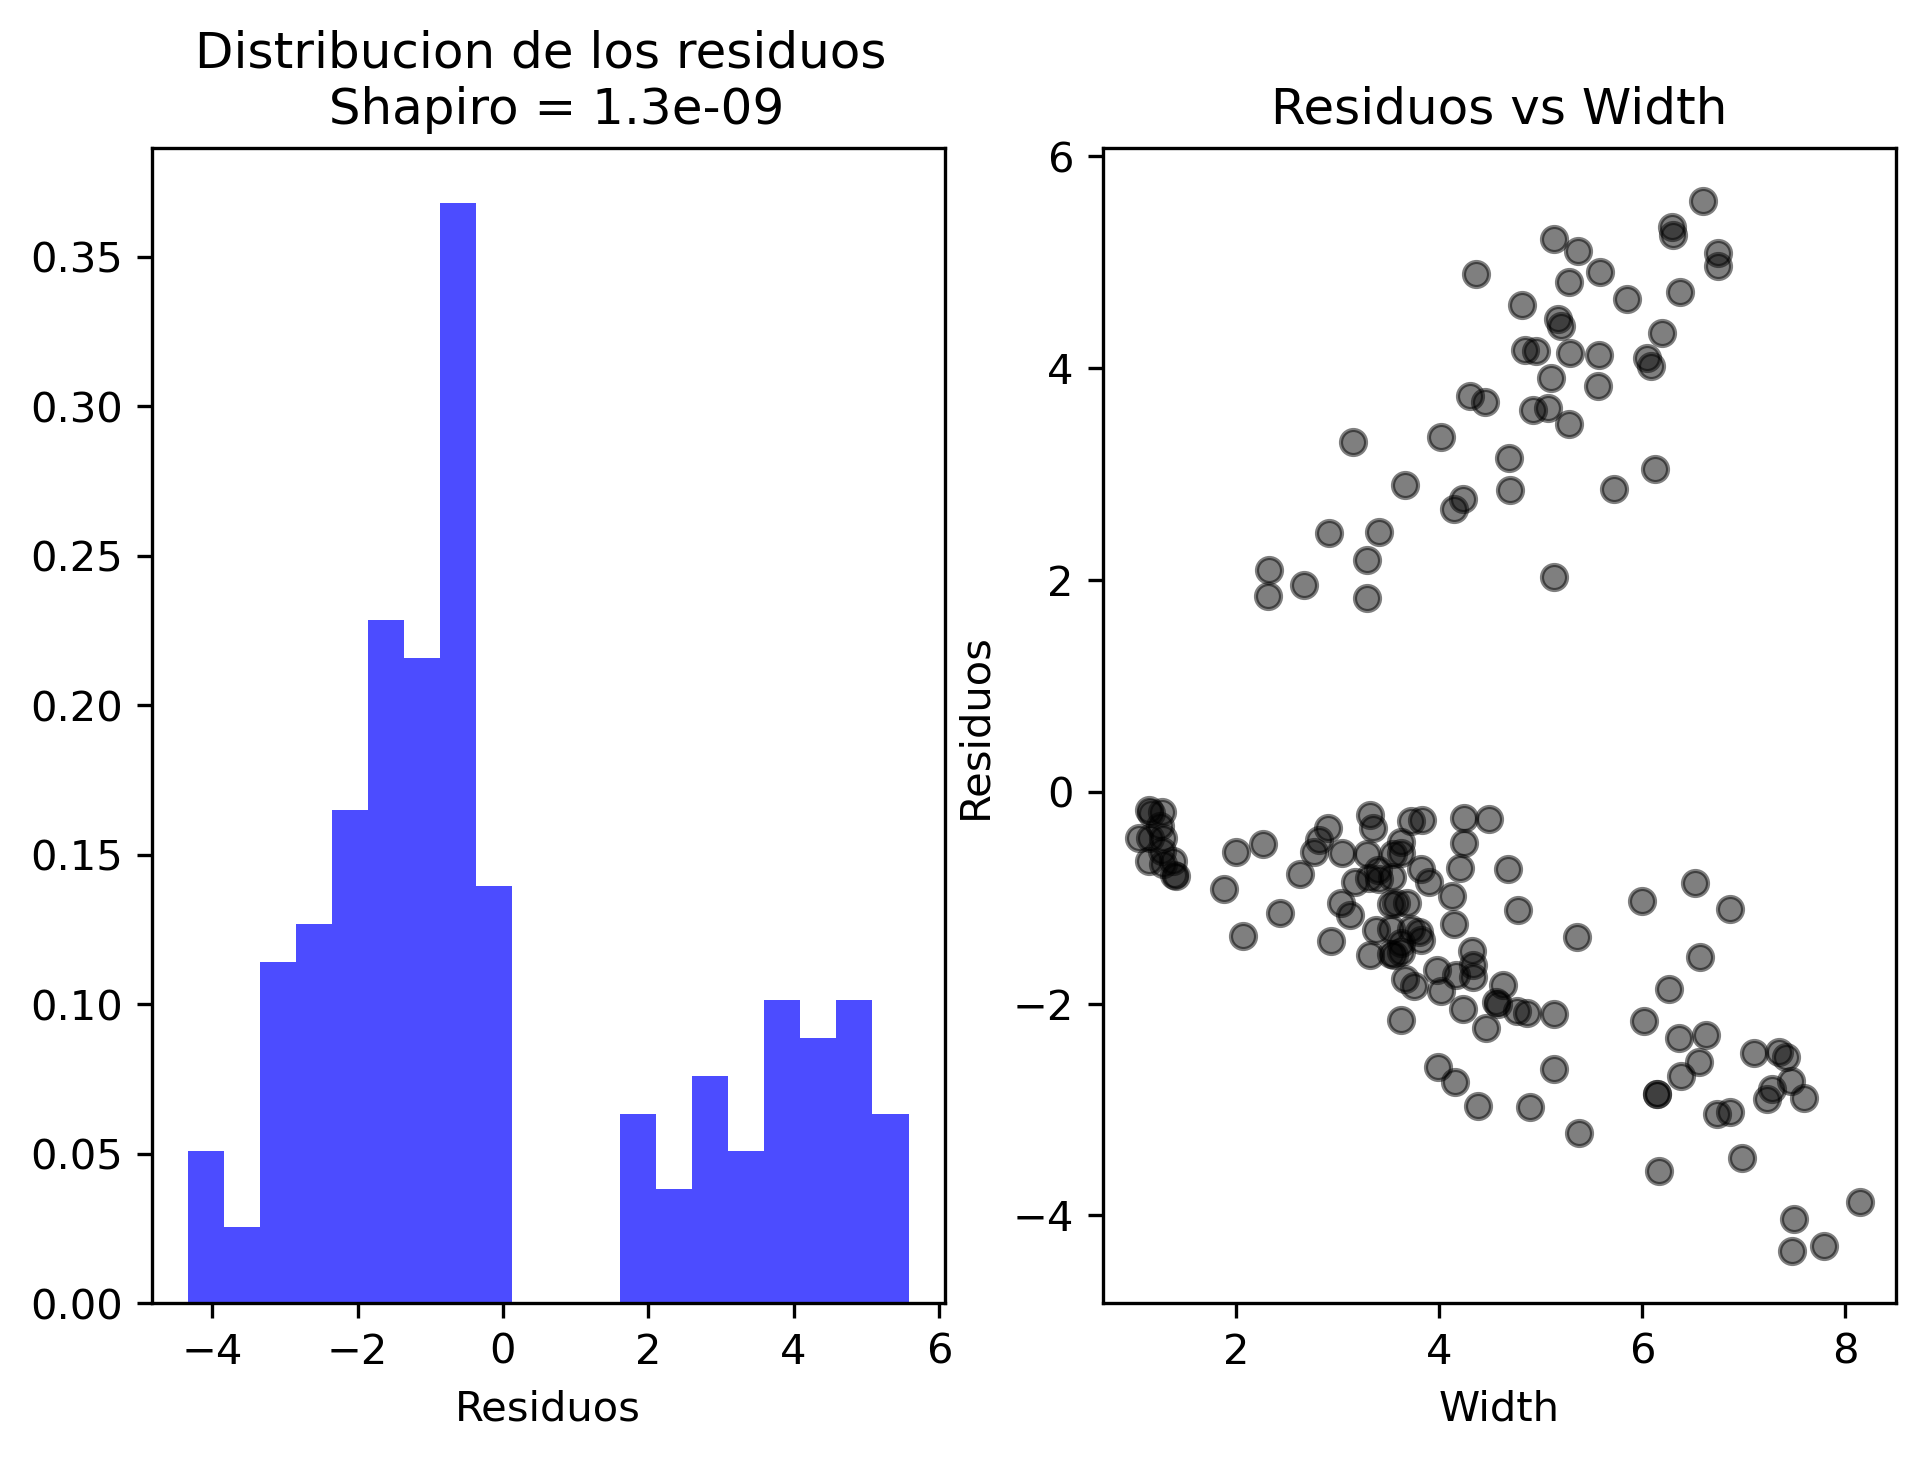

In [63]:
# Analisis de residuos: los supuestos de OLS se verifican sobre los residuos, no sobre los datos originales
# Un buen modelo debe tener residuos: (1) aproximadamente normales, (2) con varianza constante en x
residuos = modelo_ols.resid  # e_i = y_i - y_hat_i

fig, ax = plt.subplots(1, 2, figsize=(7.5, 5), dpi=300)

shapiro = stats.shapiro(residuos)  # H0: los residuos son normales

# Panel izquierdo: distribucion empirica de los residuos
ax[0].hist(residuos, bins=20, color='blue', alpha=0.7, density=True)
ax[0].set_title(f'Distribucion de los residuos \n Shapiro = {shapiro[1]:.1e}')
ax[0].set_xlabel('Residuos')

# Panel derecho: residuos vs predictor (buscar patron sistematico = problemas en el modelo)
ax[1].scatter(width, residuos, alpha=0.5, color='black')
ax[1].set_title('Residuos vs Width')
ax[1].set_xlabel('Width')
ax[1].set_ylabel('Residuos')

Nos damos que los residuos no son normales. 

**¿Qué podemos hacer?**

Dividamos según tipo de pez y analicemos que pasa.

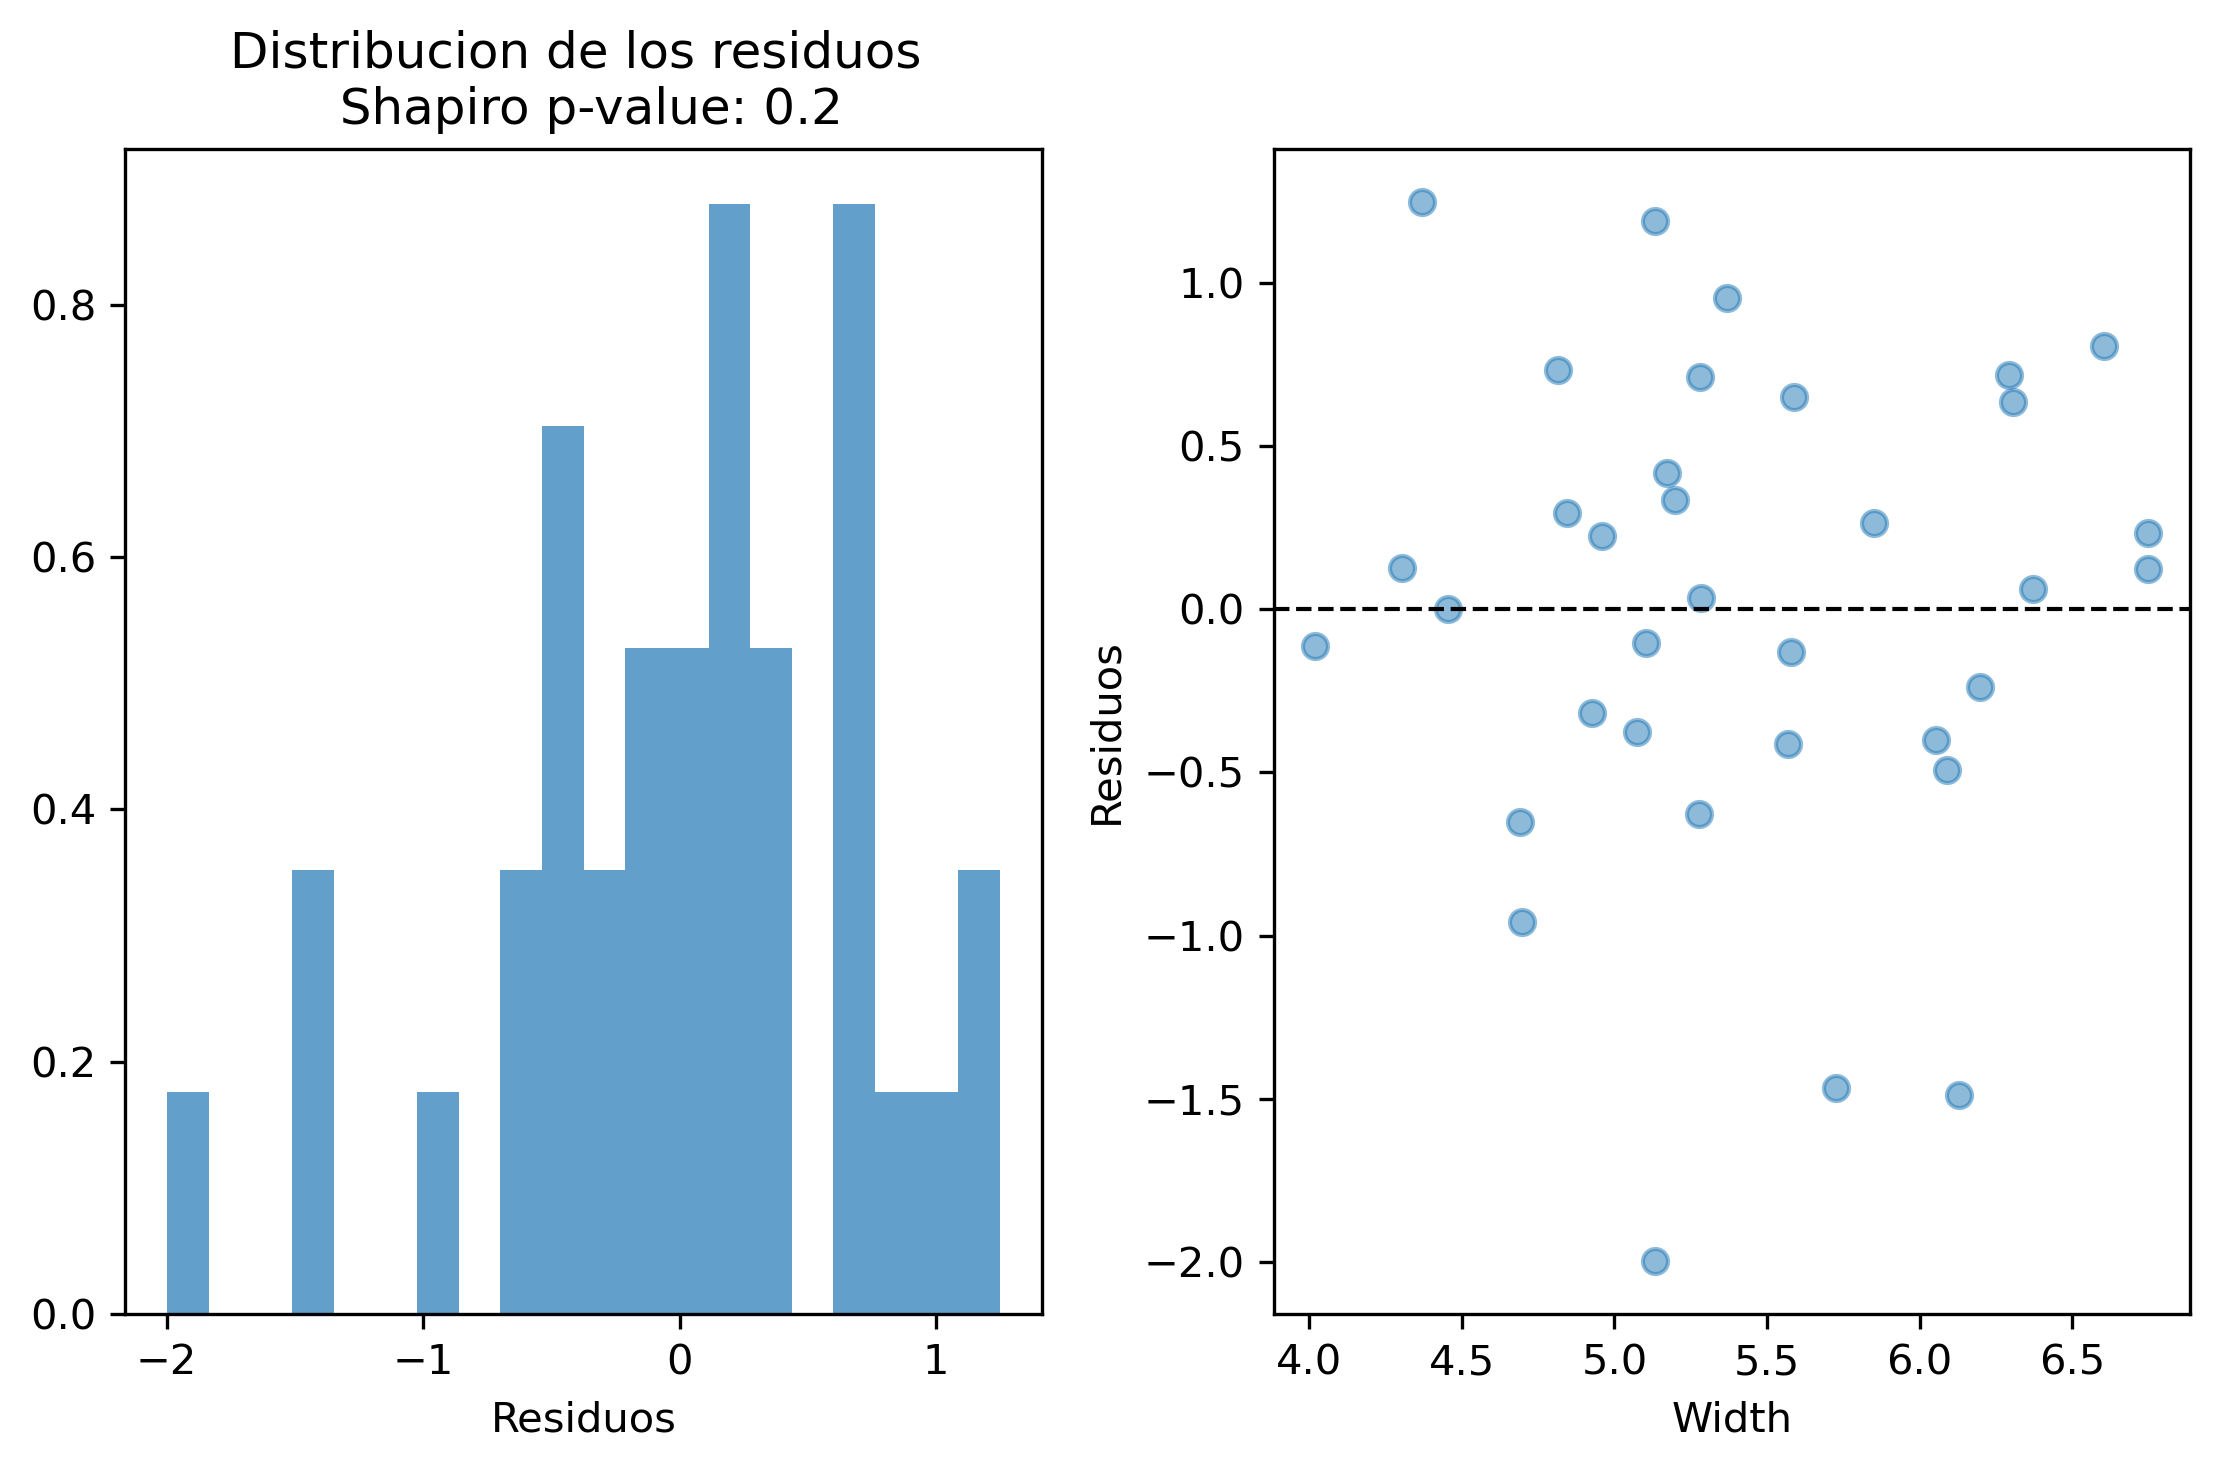

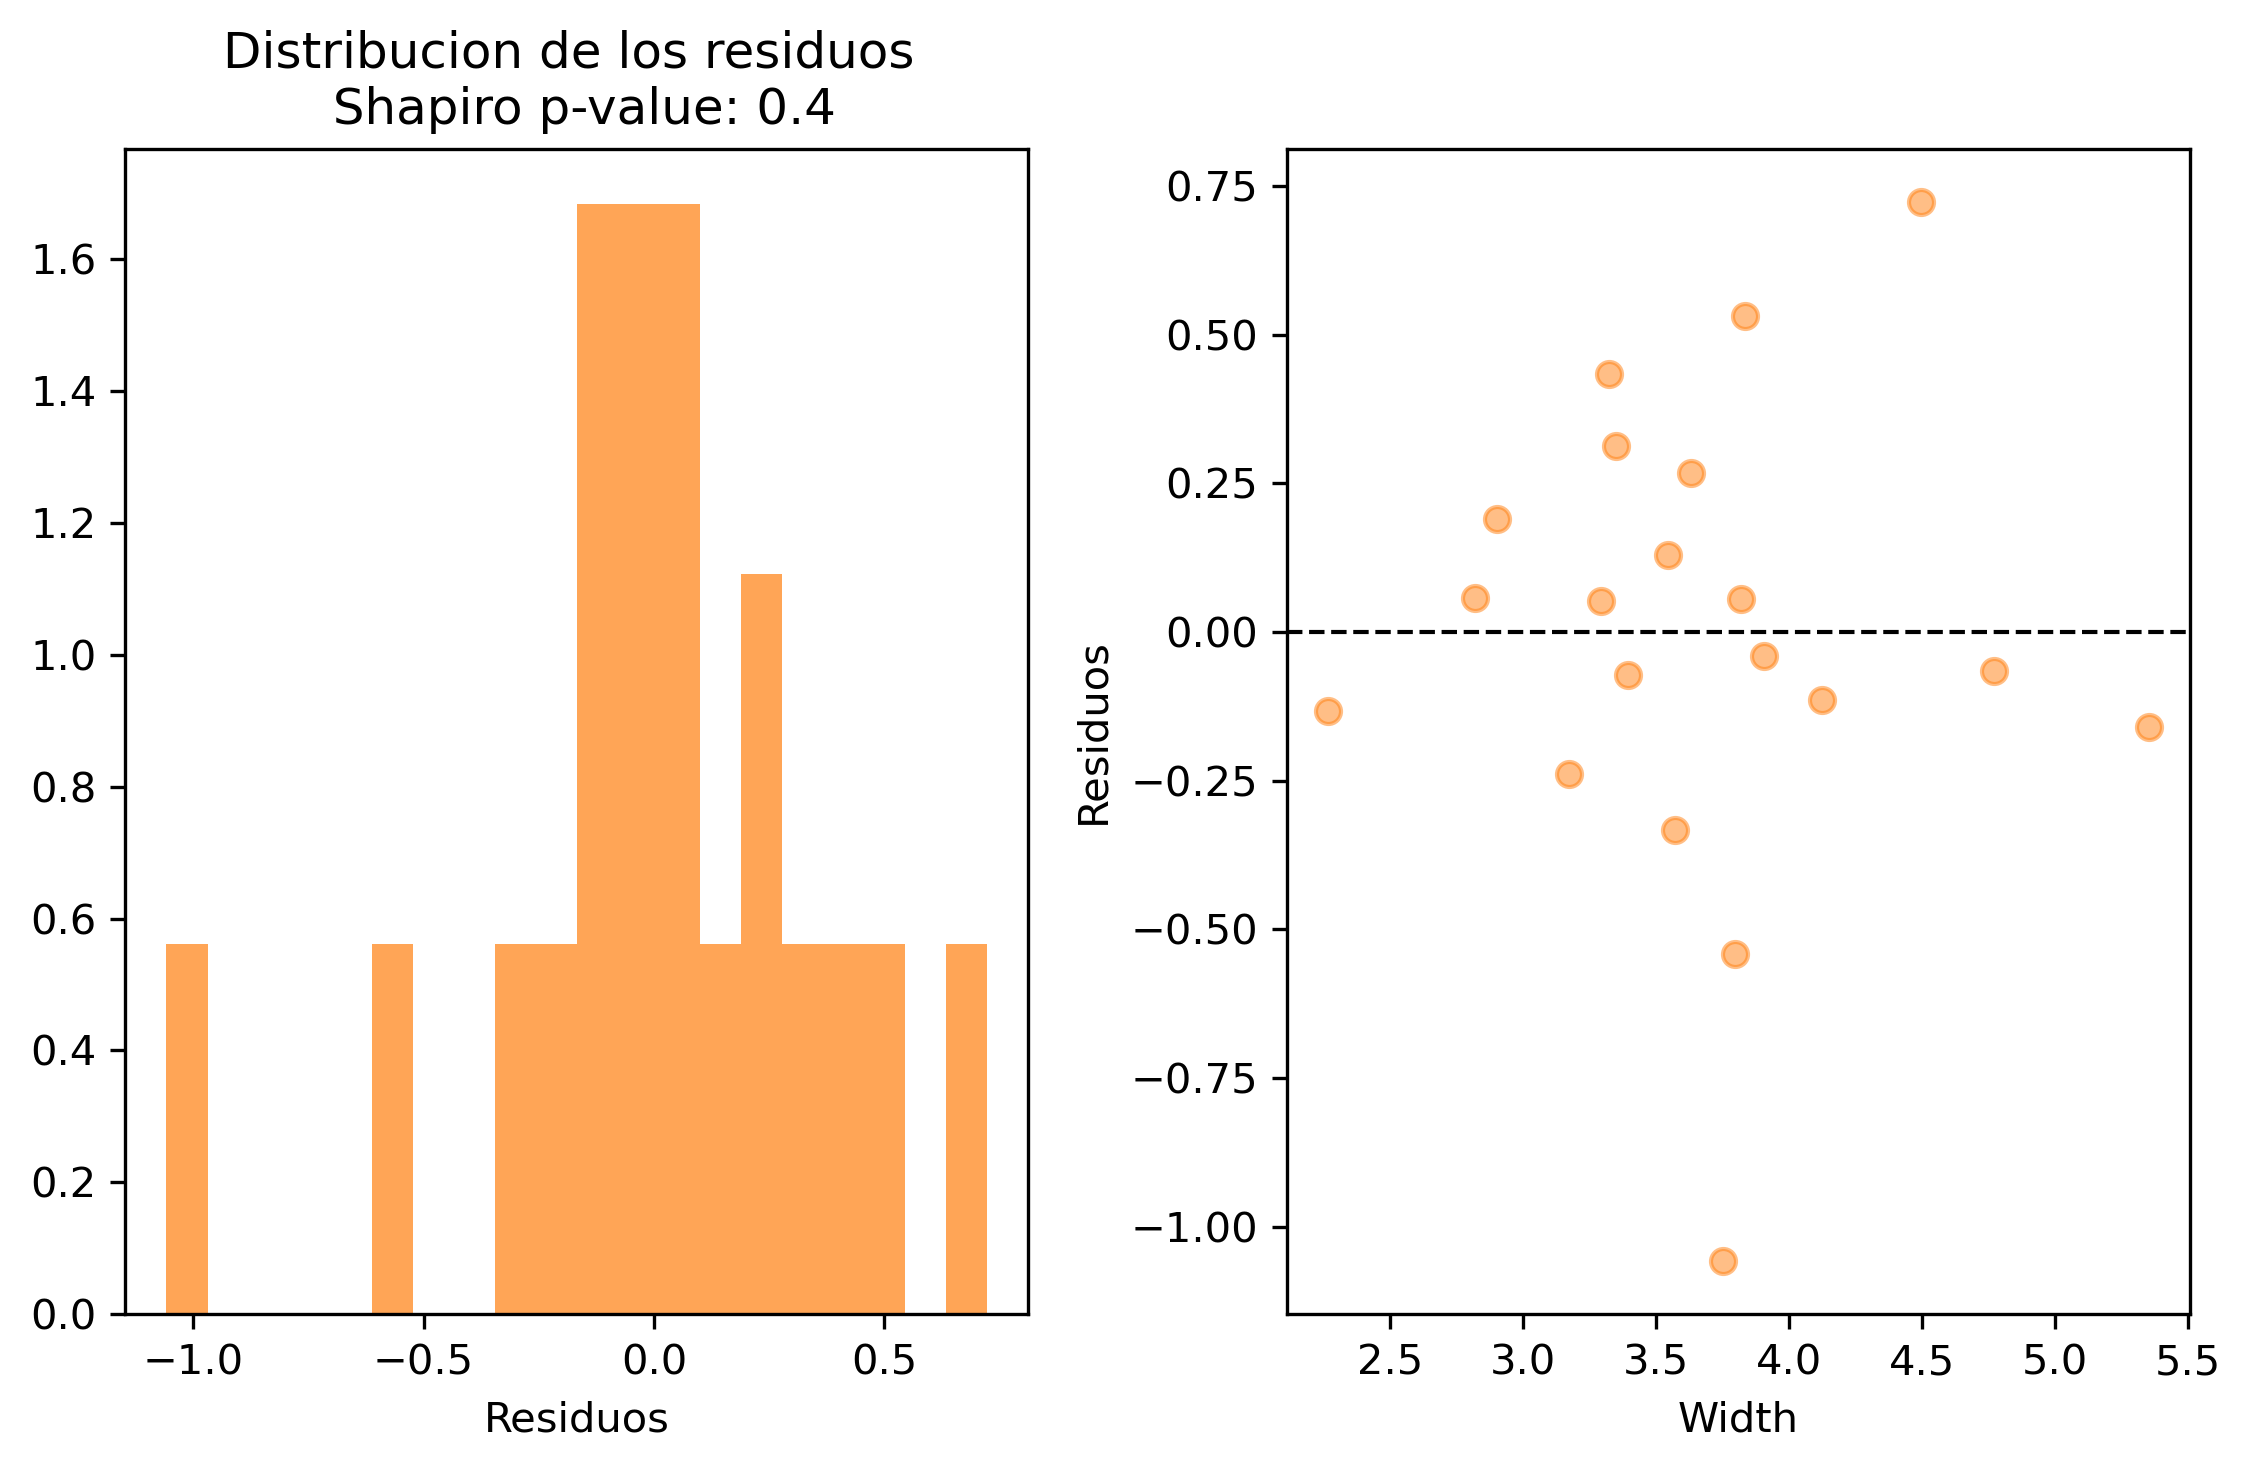

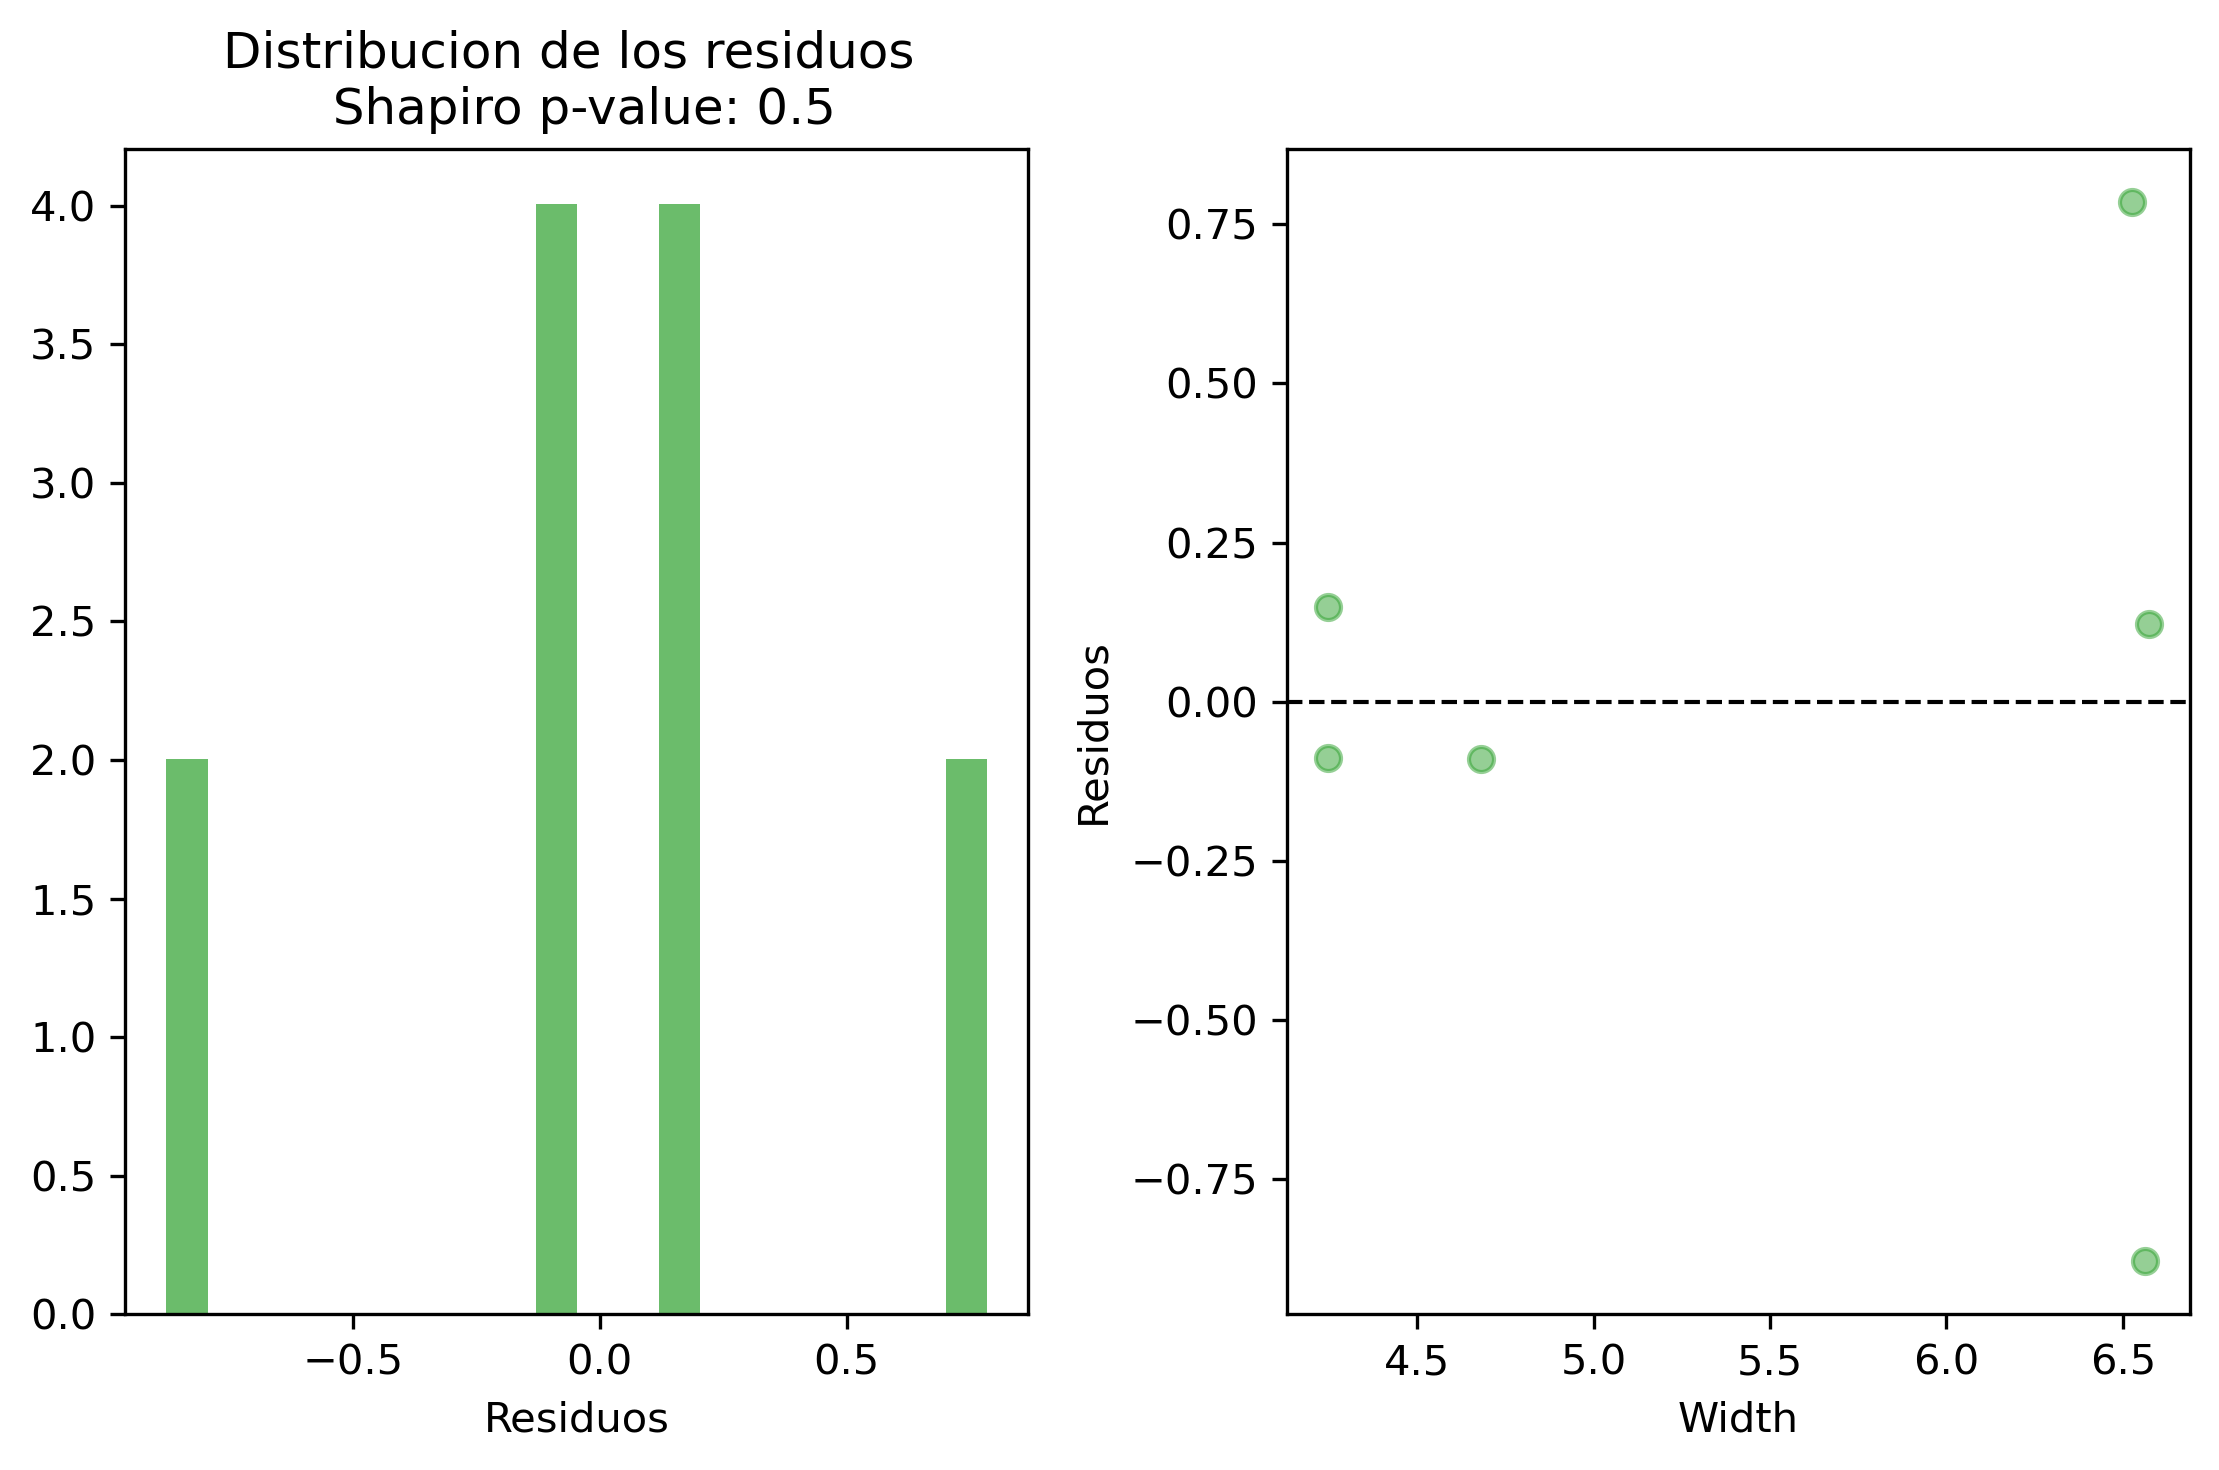

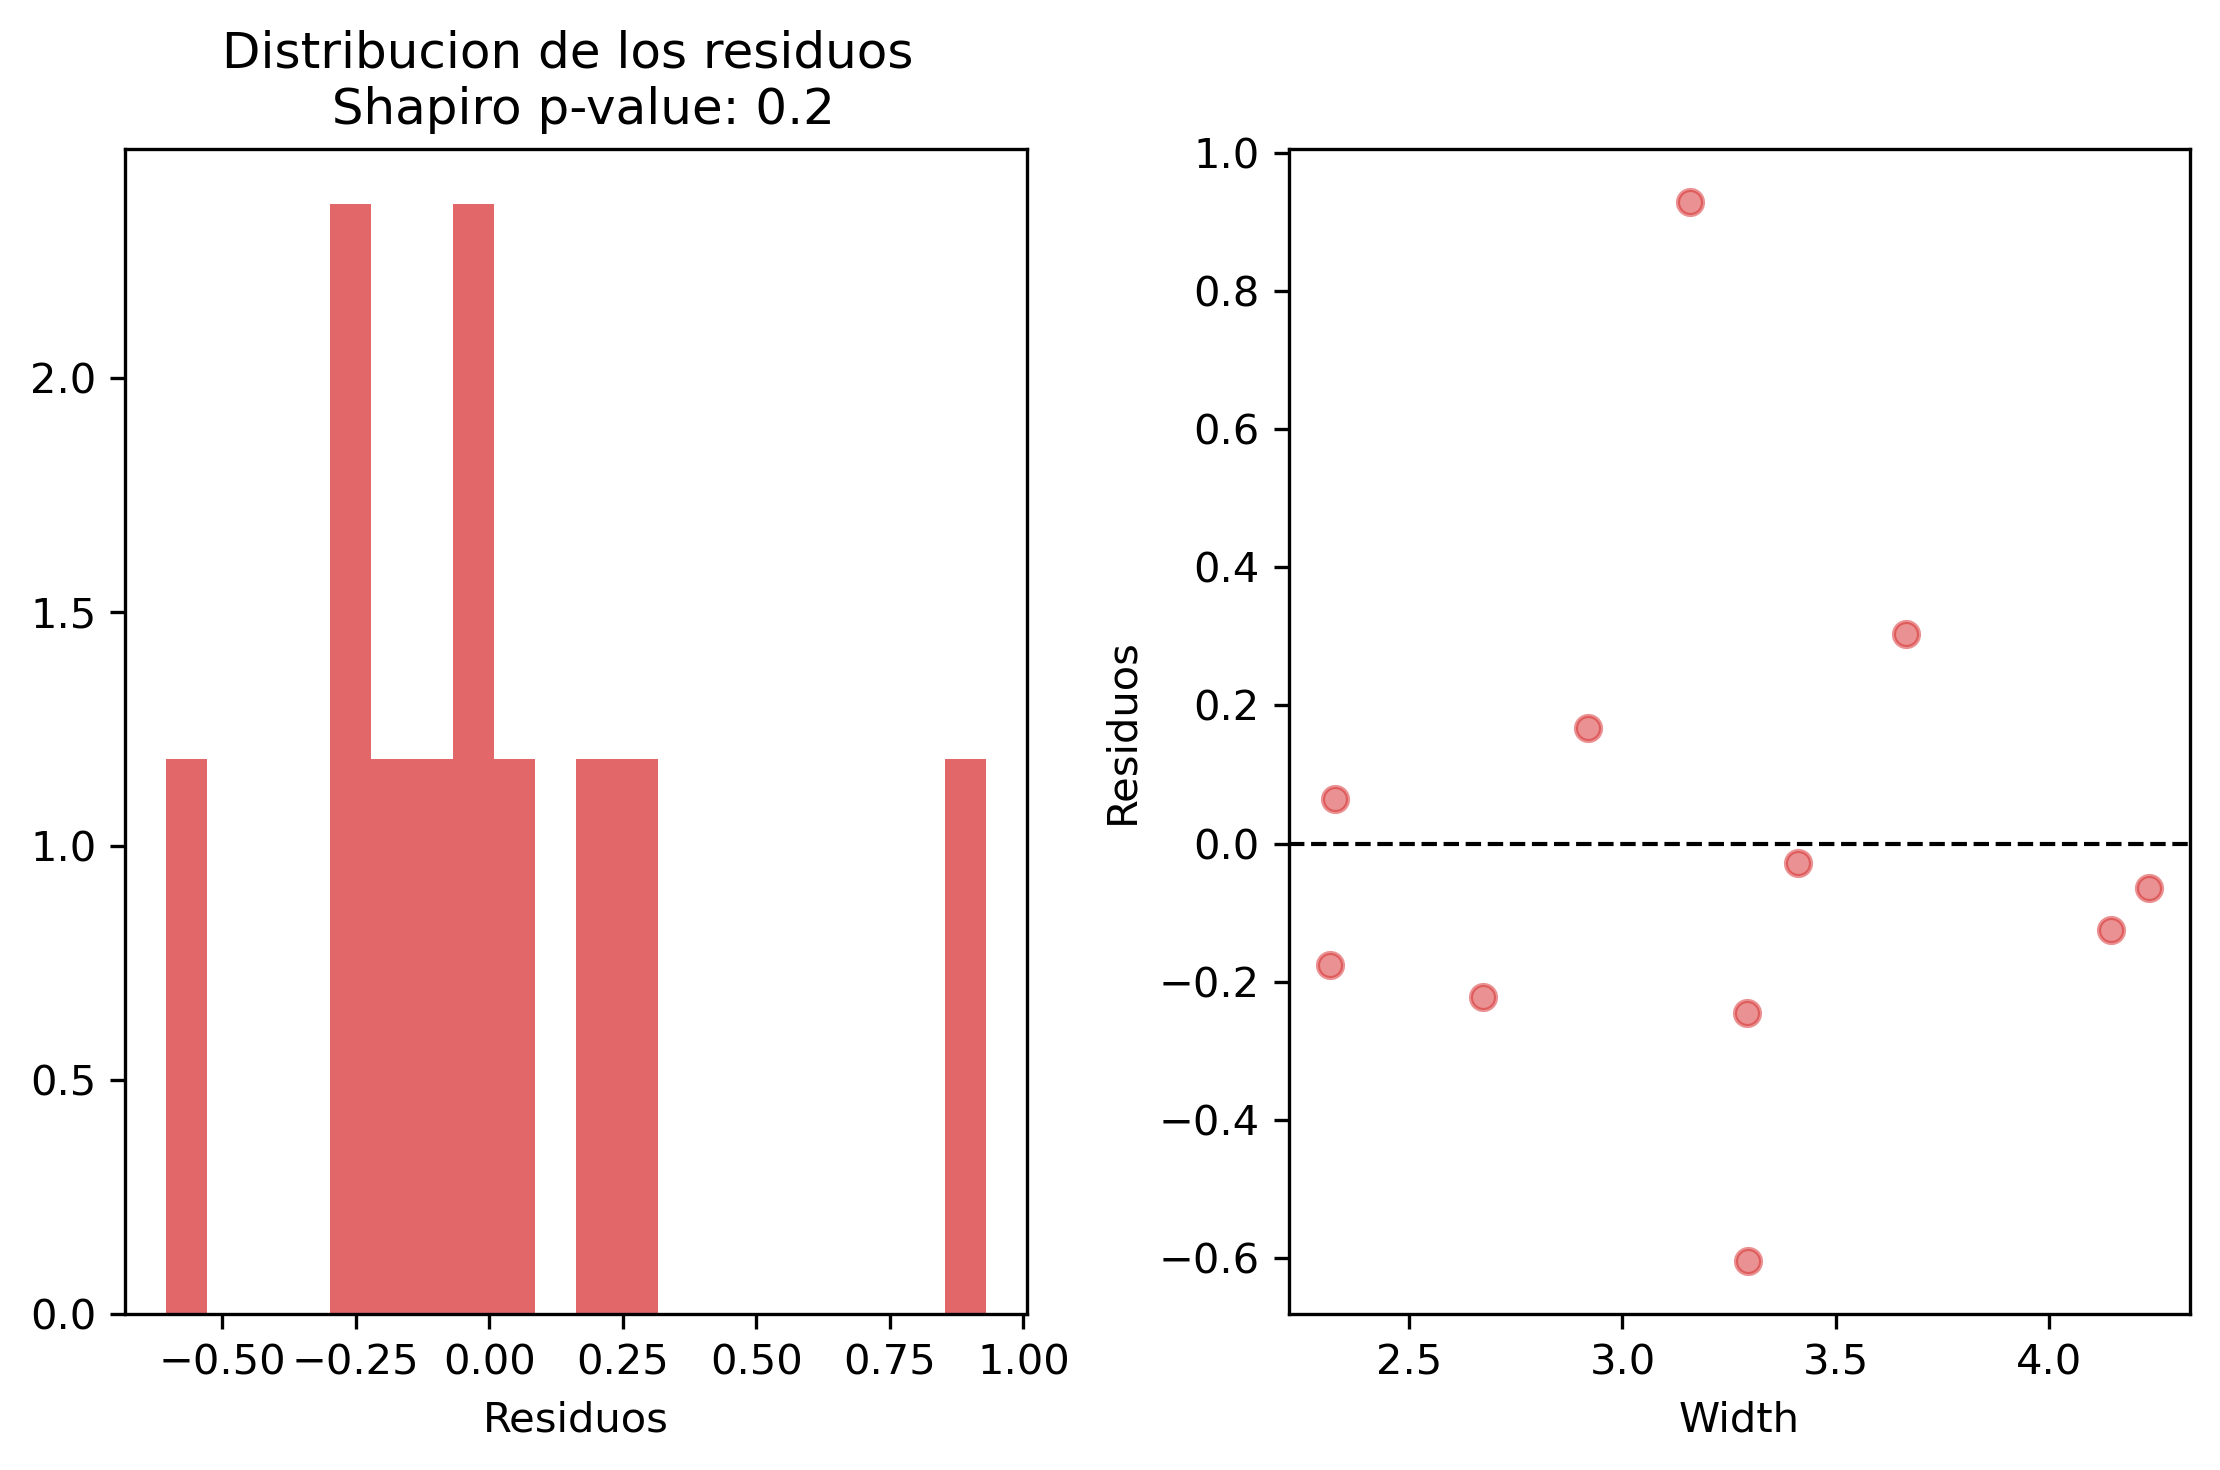

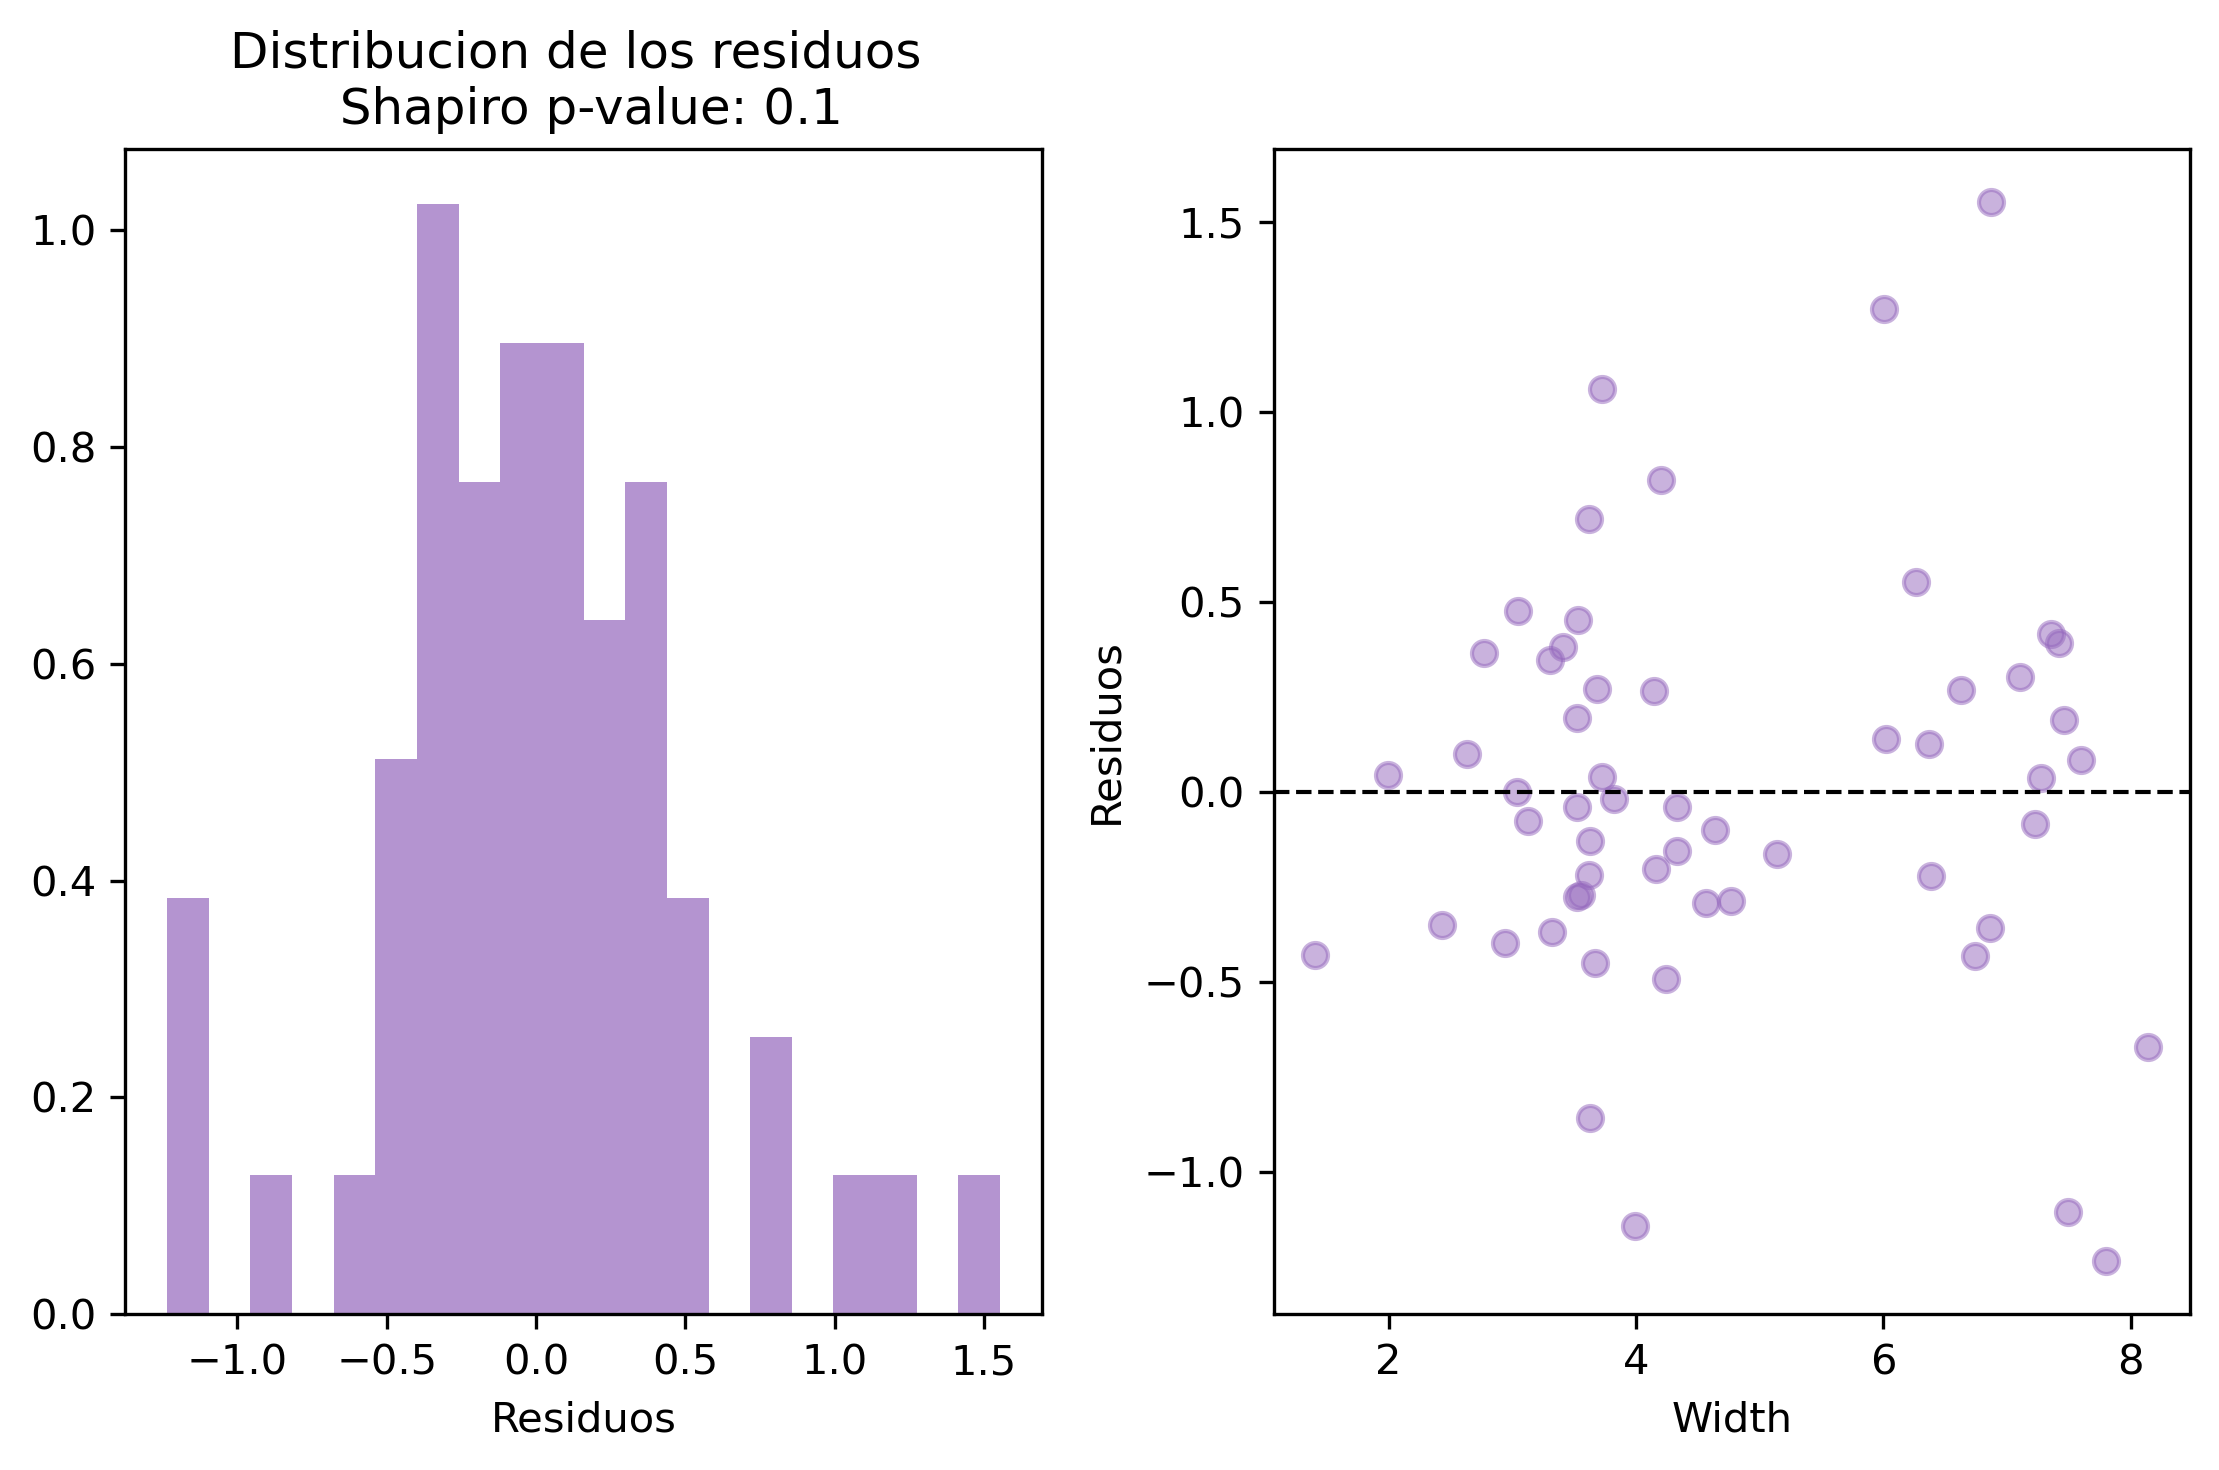

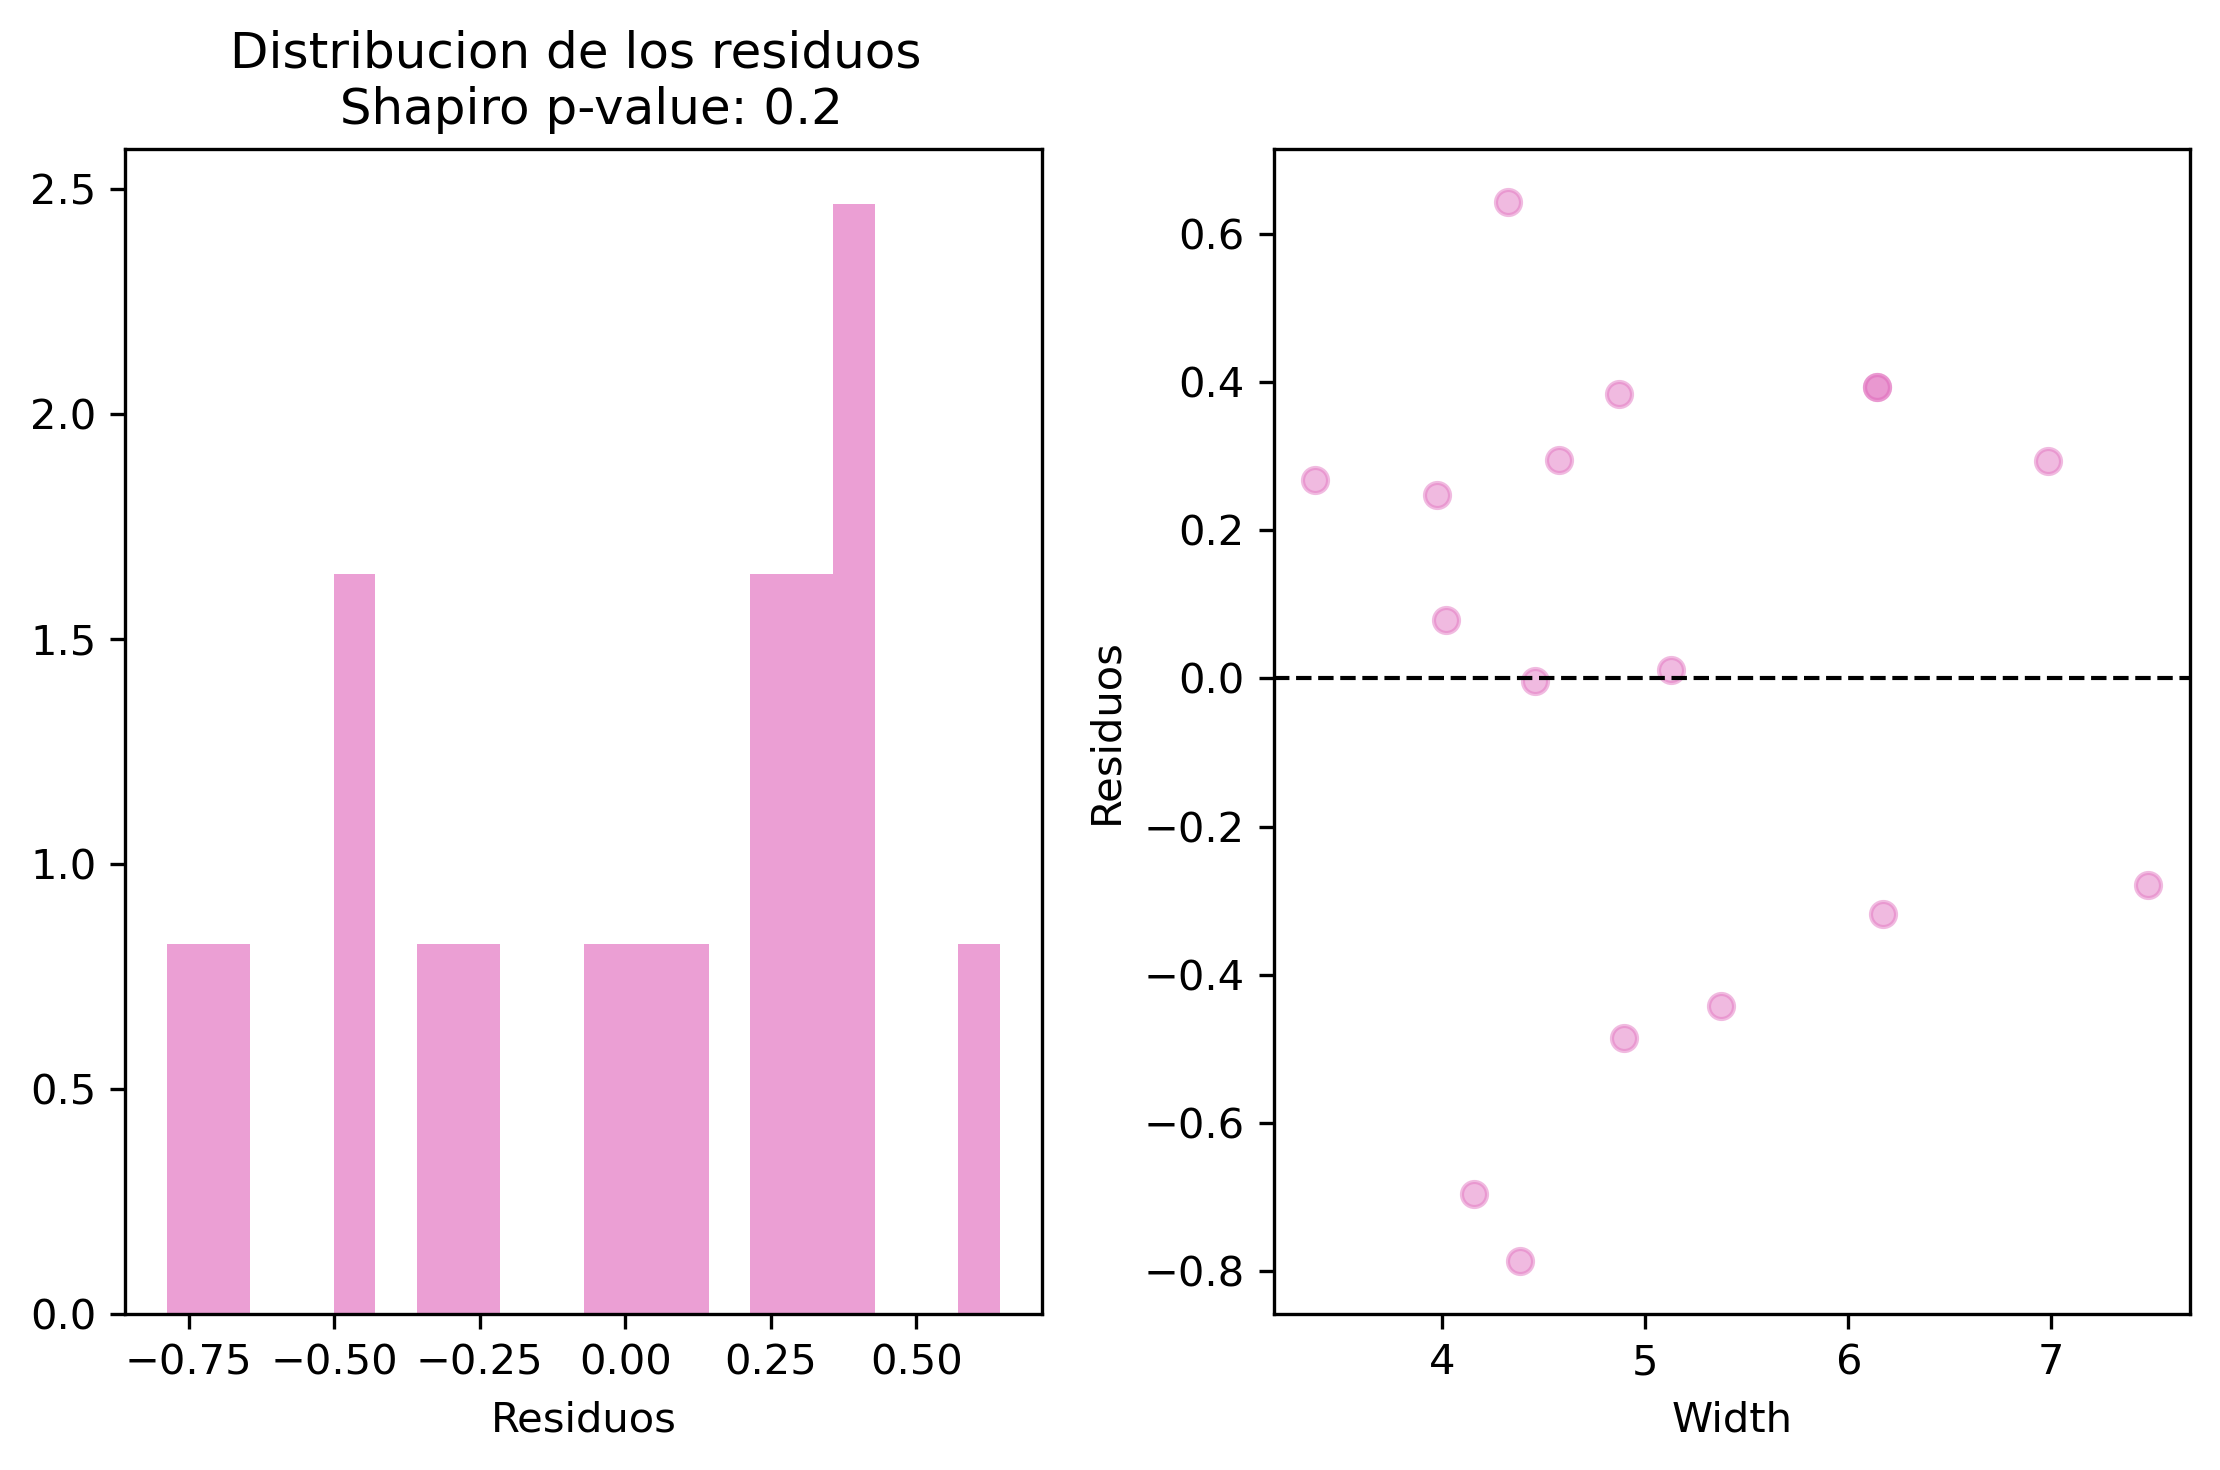

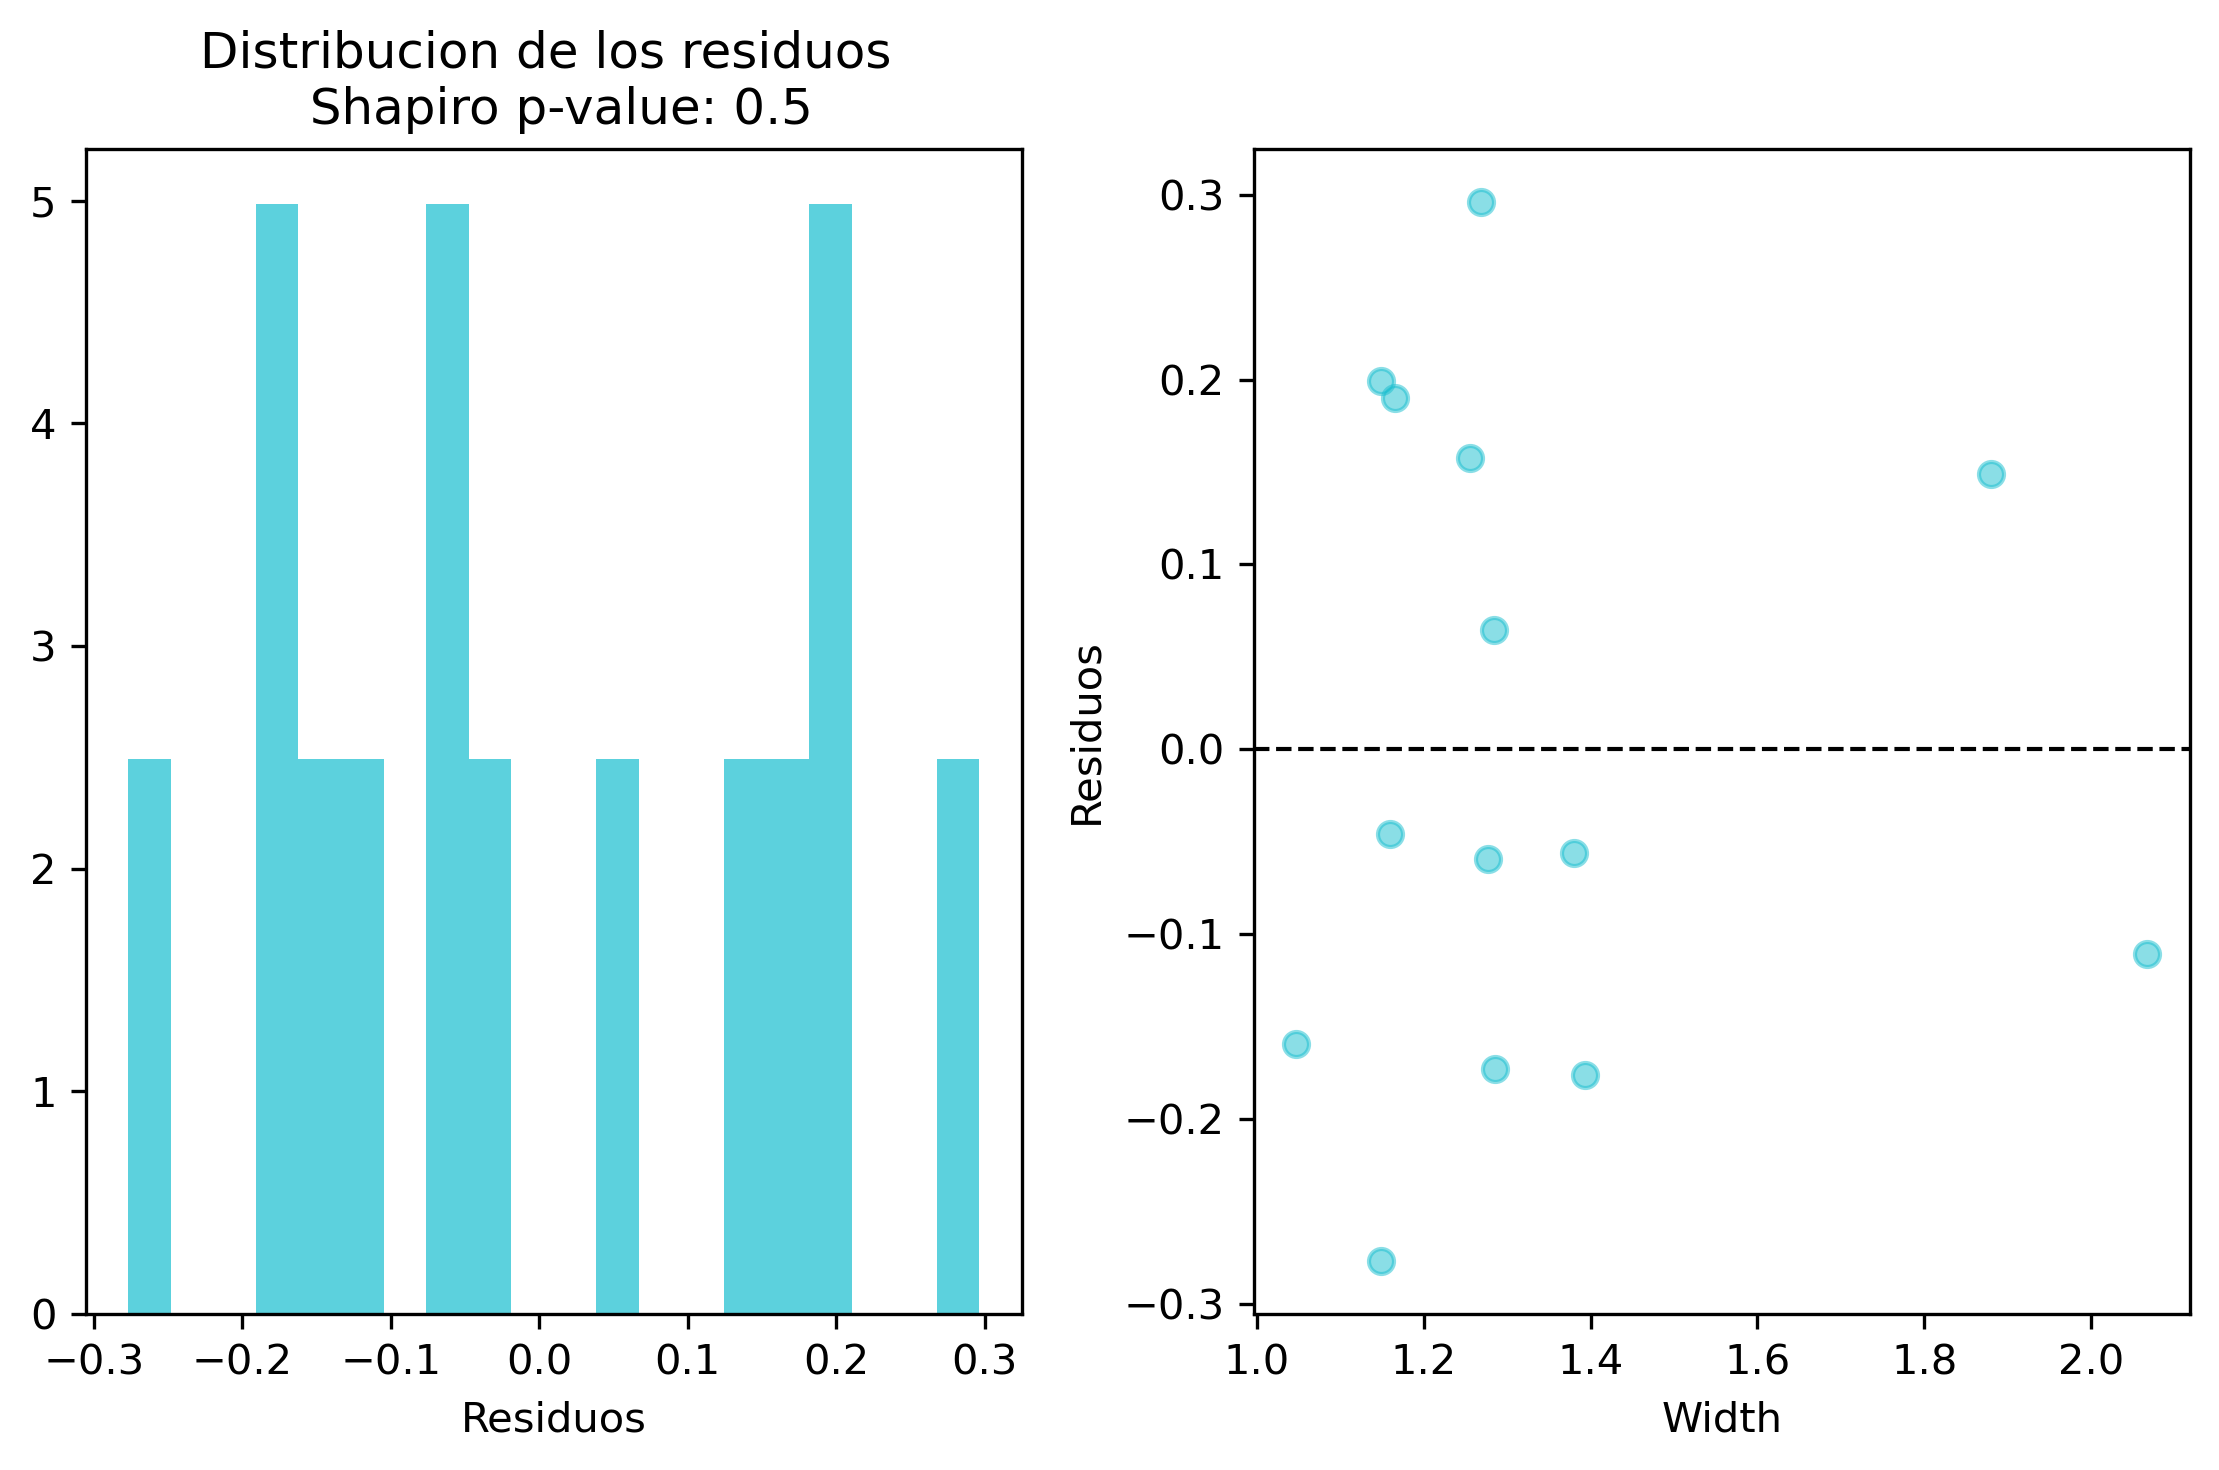

In [64]:
pez = df['Species']
color_pez = {
    'Bream': 'tab:blue', 'Roach': 'tab:orange', 'Whitefish': 'tab:green',
    'Parkki': 'tab:red', 'Perch': 'tab:purple', 'Pike': 'tab:pink', 'Smelt': 'tab:cyan'
}

# Ajustamos un modelo OLS separado para cada especie y evaluamos sus residuos
# Si los residuos por especie son mas normales que los globales, confirma que
# mezclar especies en un solo modelo viola los supuestos
for i in pez.unique():
    fig, ax = plt.subplots(1, 2, figsize=(7.5, 5), dpi=300)

    # Filtramos datos de la especie i y ajustamos el modelo
    modelo_pez = OLS(height[pez == i], sm.add_constant(width[pez == i])).fit()
    resid = modelo_pez.resid  # residuos del modelo para esta especie

    # Shapiro-Wilk sobre los residuos: [1] extrae el p-value
    shapiro_p = stats.shapiro(resid)[1]

    # Panel izquierdo: histograma de residuos con el p-value de normalidad en el titulo
    ax[0].hist(resid, bins=20, alpha=0.7, density=True, color=color_pez[i])
    ax[0].set_xlabel('Residuos')
    ax[0].set_title('Distribucion de los residuos \n Shapiro p-value: {:.1f}'.format(shapiro_p))

    # Panel derecho: residuos vs Width con linea en 0 (residuos sin sesgo sistematico)
    ax[1].scatter(width[pez == i], resid, alpha=0.5, label=i, color=color_pez[i])
    ax[1].set_xlabel('Width')
    ax[1].set_ylabel('Residuos')
    ax[1].axhline(0, color='black', linestyle='--', linewidth=1)  # linea de referencia en 0

    fig.tight_layout()
    plt.show()

Podemos ver como el modelo puede generar mejores resultados al poder agregar la información de los peces.
**¿Qué se concluye al respecto?**

## Regresión Lineal Multivariada

## EDA
> Visualice las relaciones bivariadas entre Height y las demás variables numéricas. ¿Existen correlaciones lineales claras?
>> Genere un reporte con diagramas de dispersión y superponga líneas de regresión. Para cada par, incluya el coeficiente de correlación de Pearson y su valor-$p$ en una etiqueta dentro del gráfico.

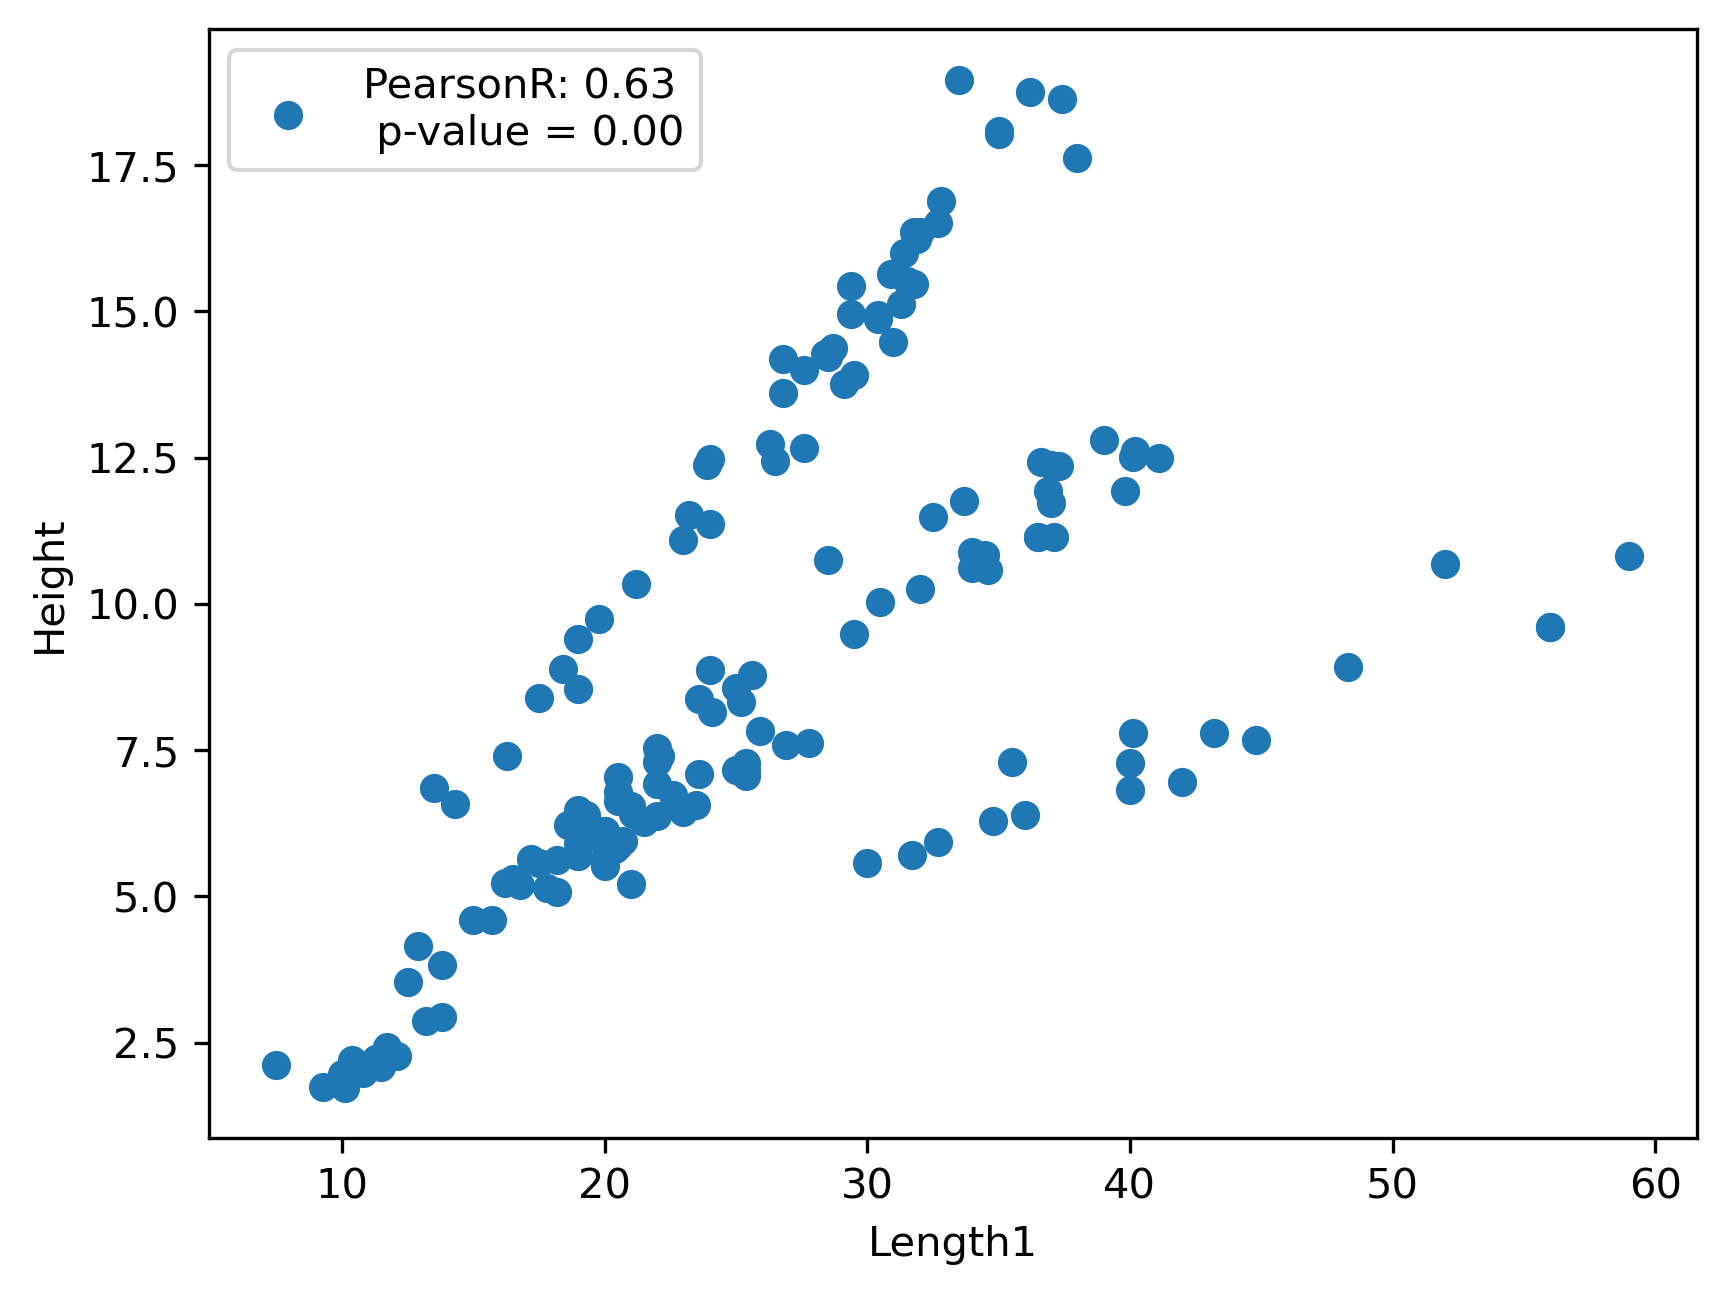

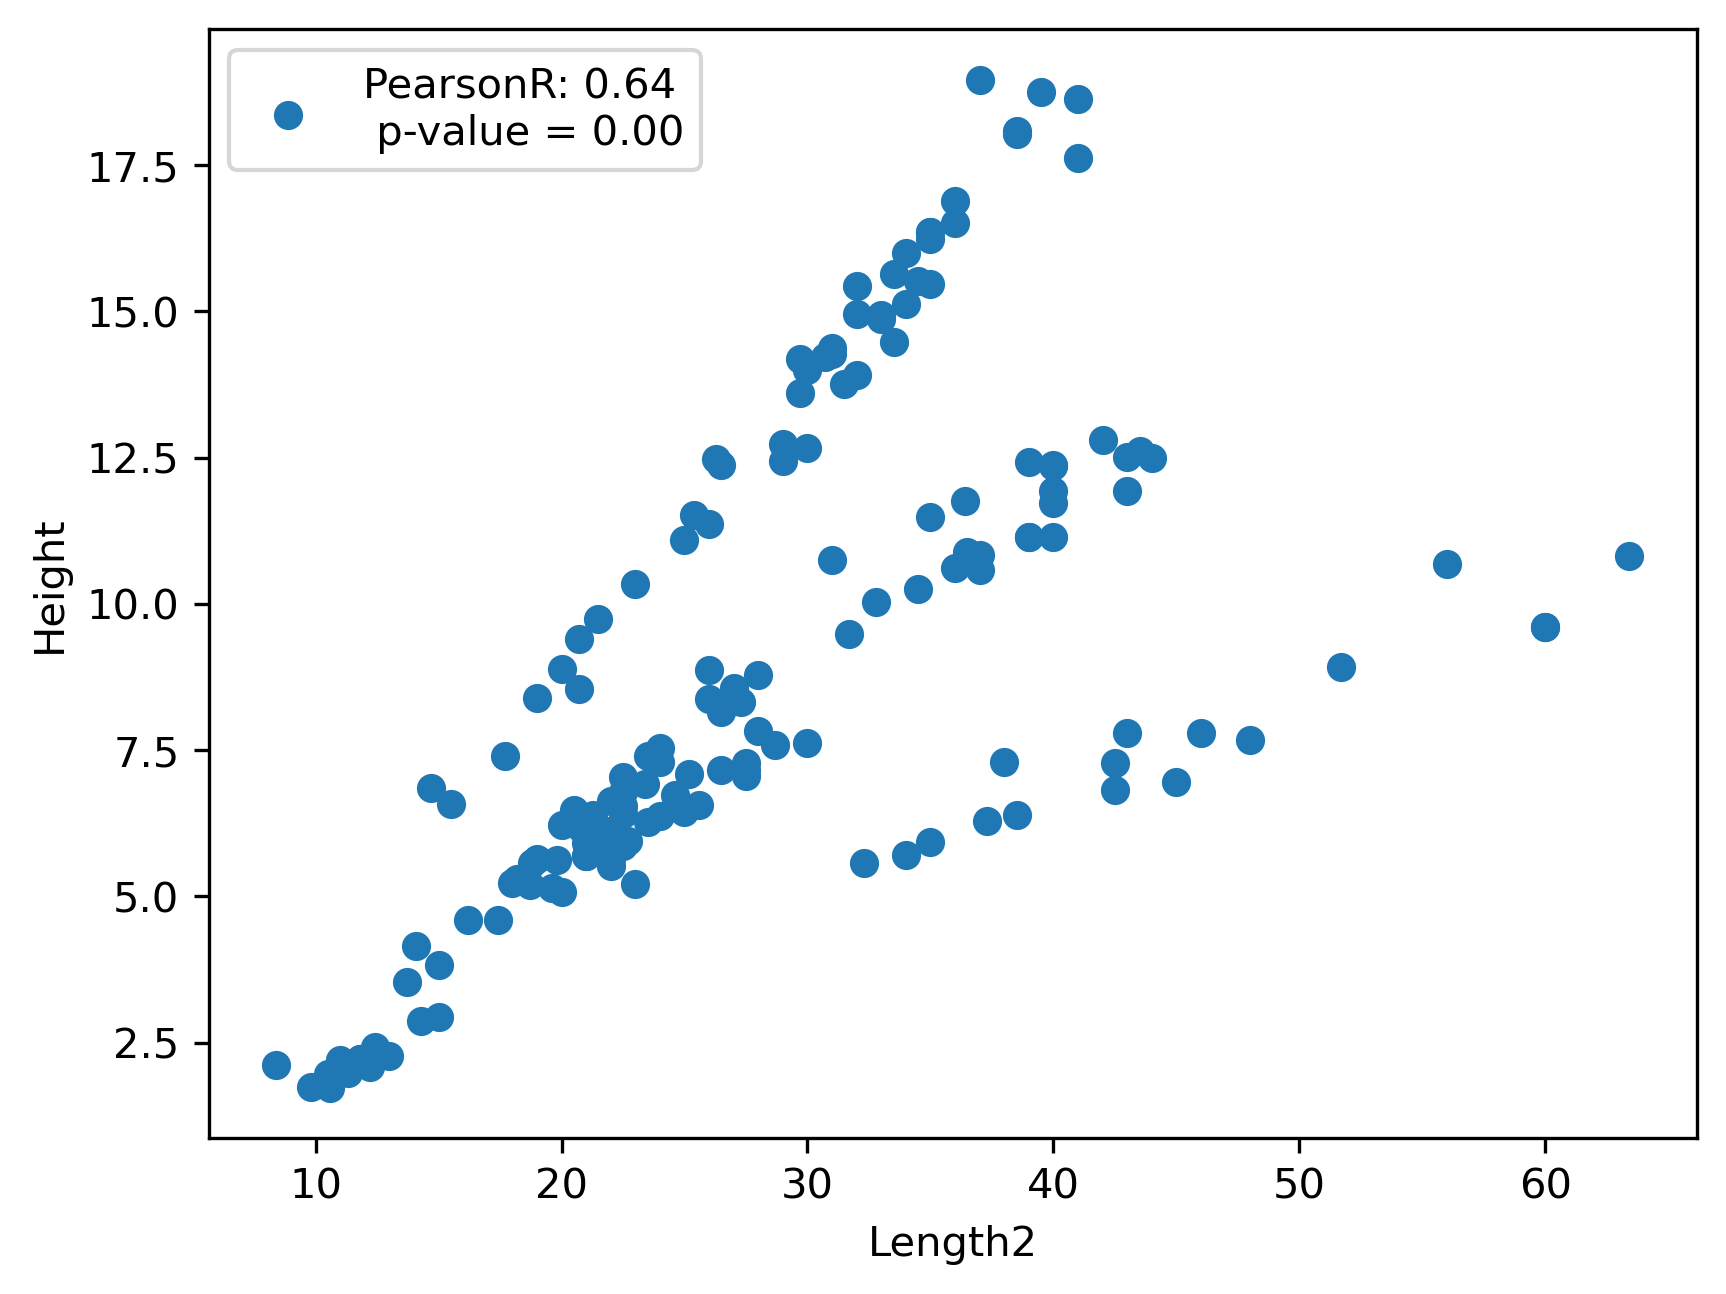

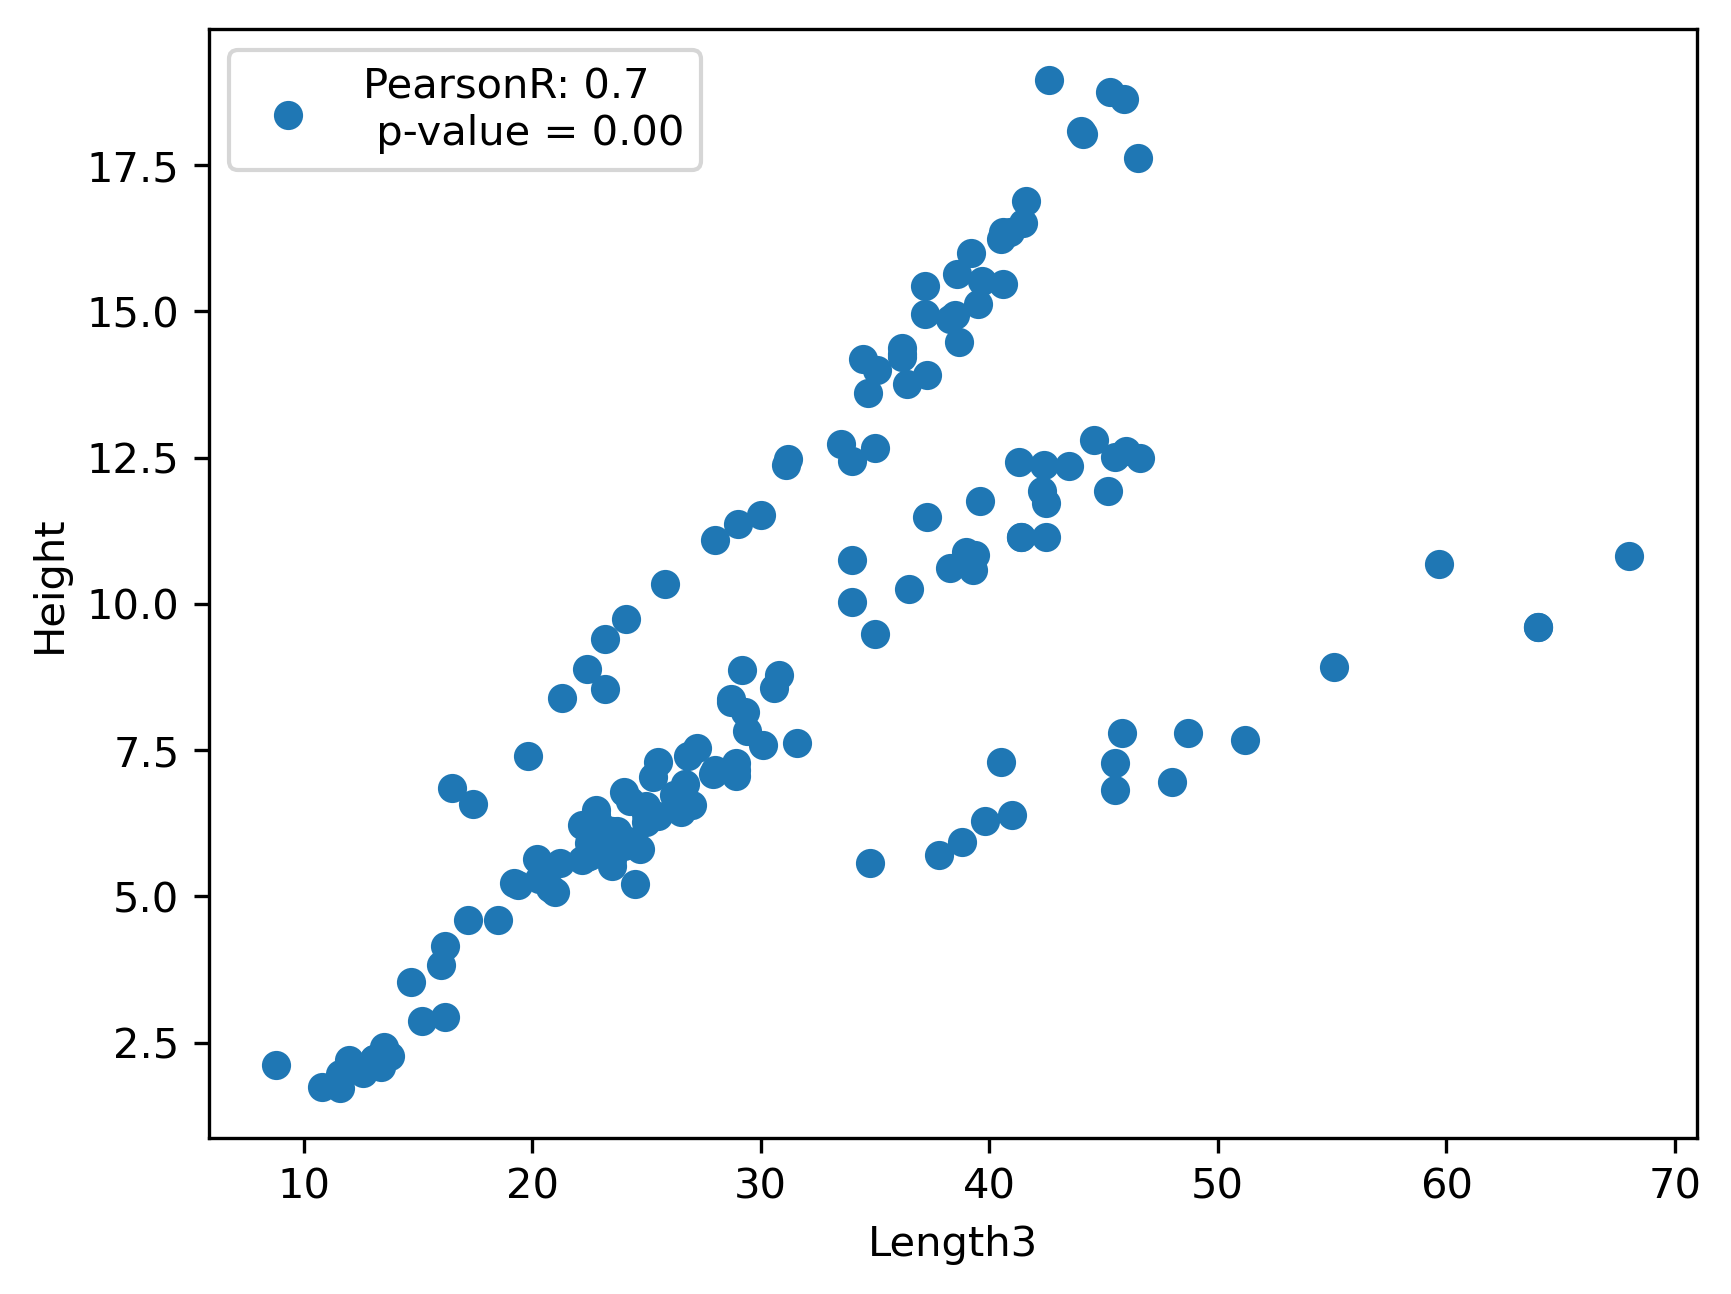

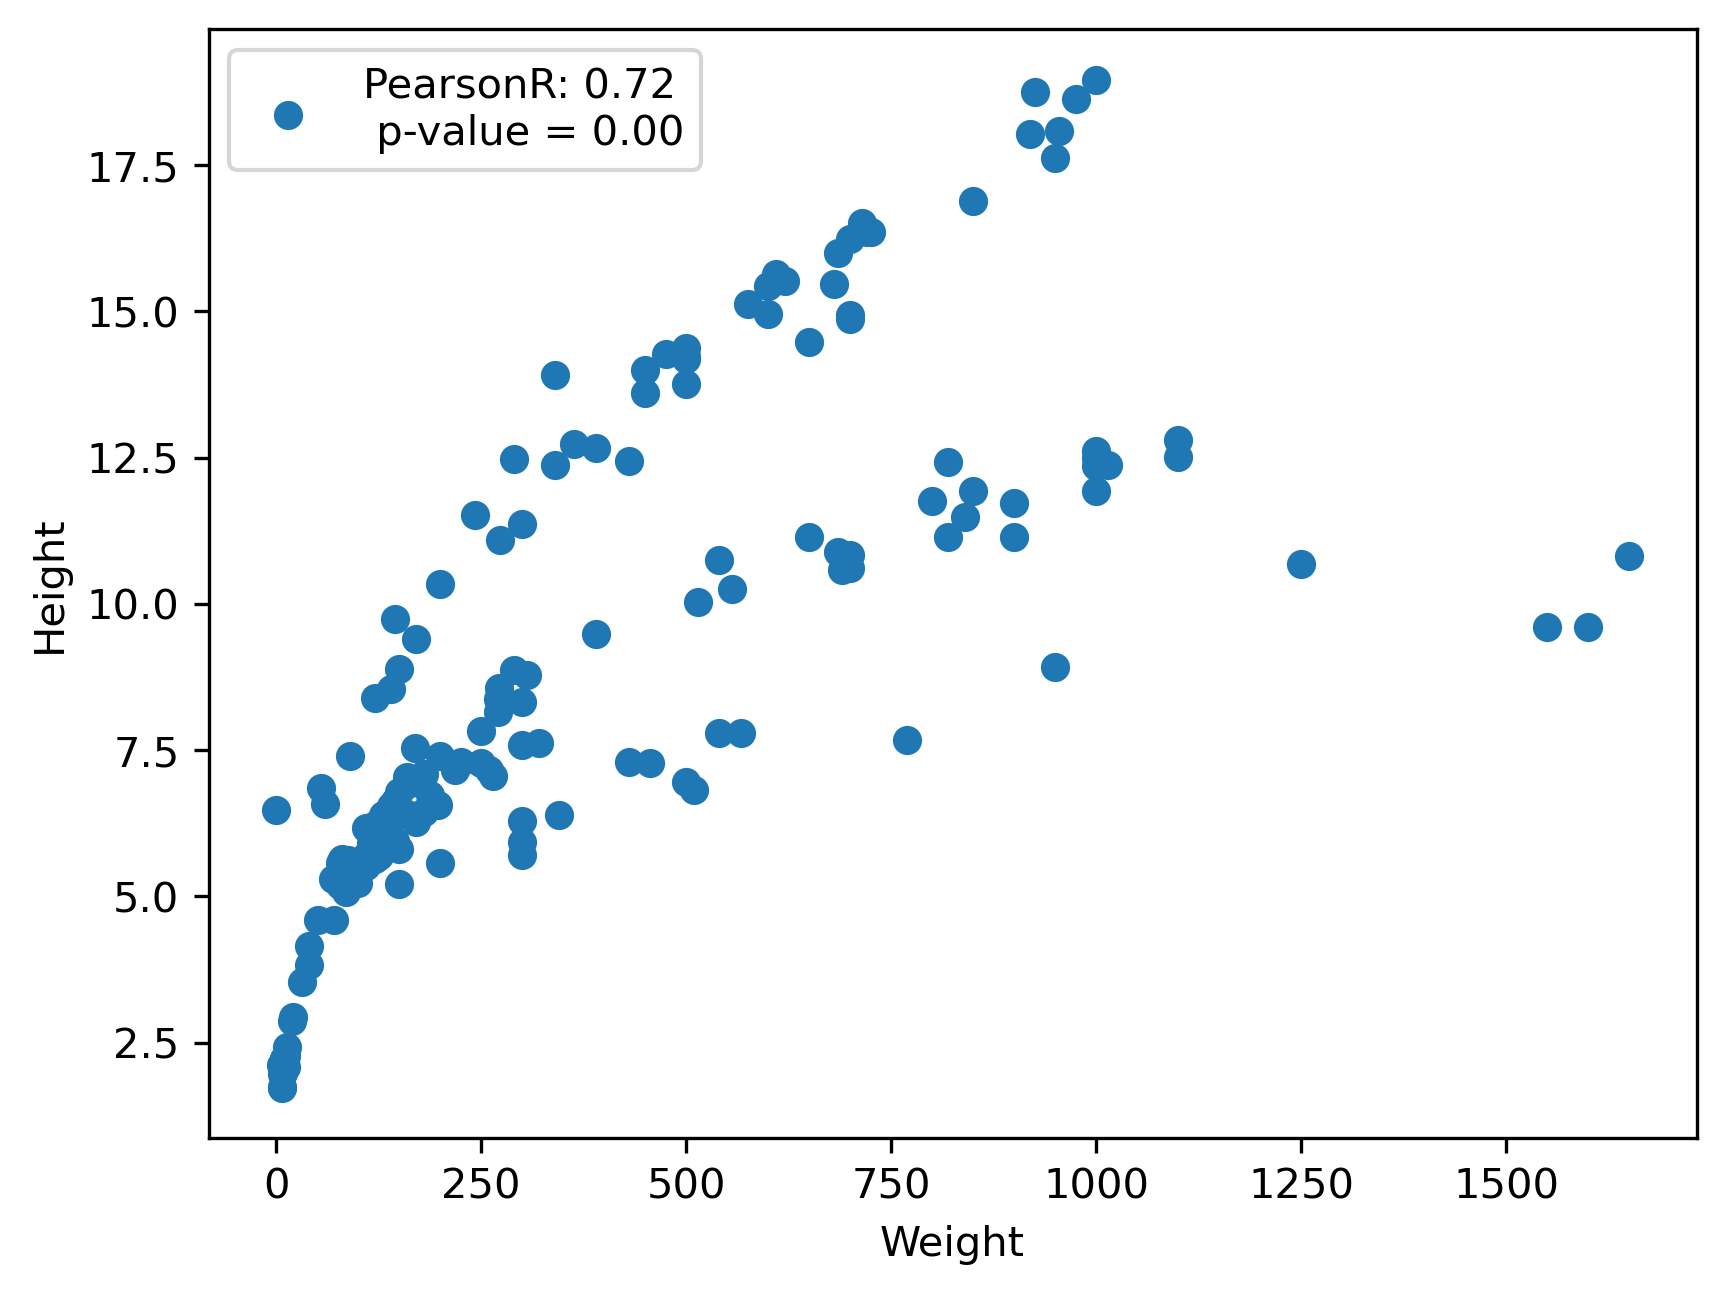

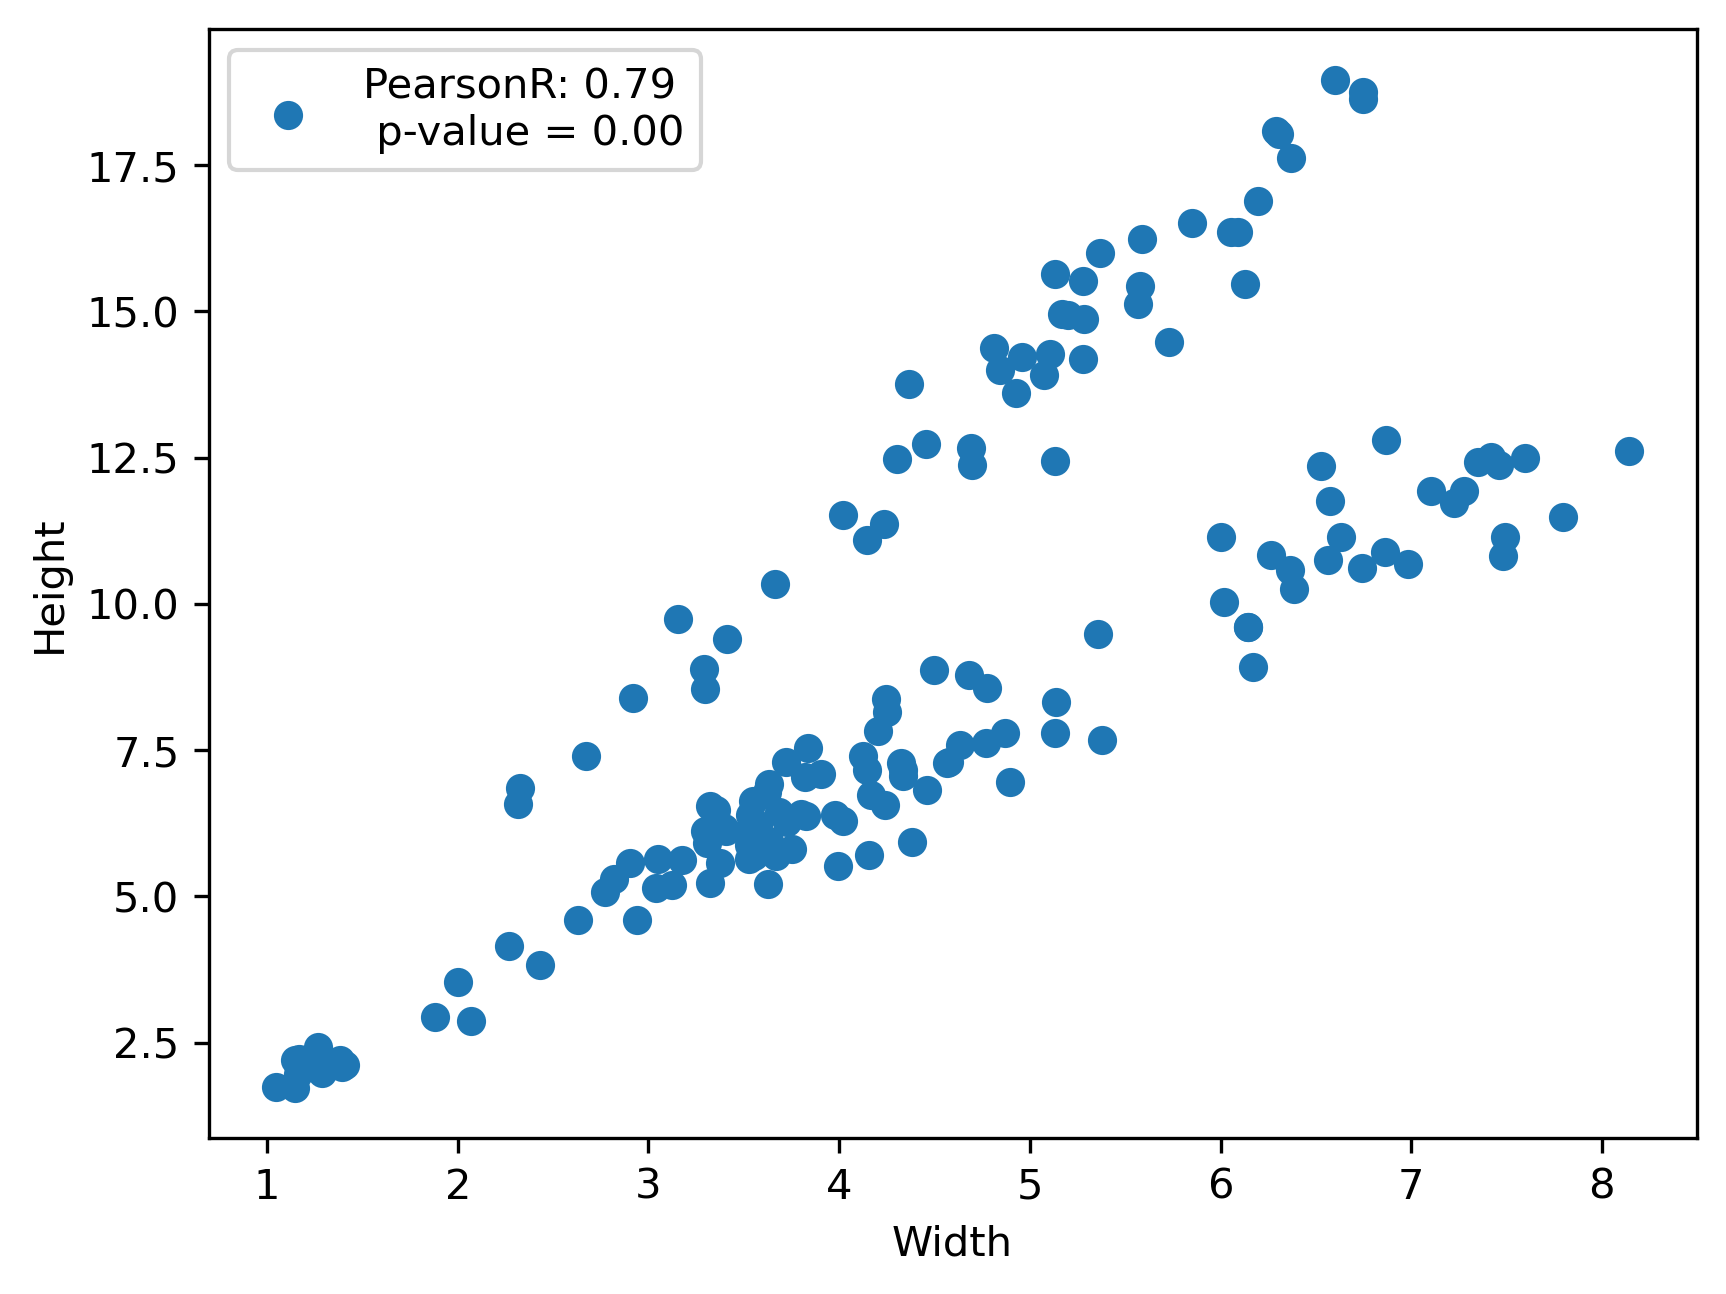

In [65]:
# Graficamos Height vs cada predictor numerico por separado
# Esto nos permite detectar cuales variables tienen una relacion lineal clara con Height
# y cuales podrian ser redundantes o no lineales
columns = ['Length1', 'Length2', 'Length3', 'Weight', 'Width']

for col in columns:
    fig, ax = plt.subplots(dpi=300)
    x = df[col]
    y = df['Height']

    # Coeficiente de Pearson: mide la fuerza y direccion de la relacion lineal en [-1, 1]
    pearson_r, pearson_pval = stats.pearsonr(x, y)

    ax.scatter(x, y, label=f'PearsonR: {pearson_r:.2}\n p-value = {pearson_pval:.2f}')
    ax.legend(loc='upper left')
    ax.set_xlabel(col)
    ax.set_ylabel('Height')

## Cálculo de Regresión Lineal Multivariada

Los modelos de regresión lineal multivariada generalizan sobre la regresión lineal simple, agregando la posibilidad de relacionar multiples variables (>2). Estos tienen la siguiente forma para un set de datos con $n$ datos y $m$ variables explicativas.
$$
\mathbf{y} = \mathbf{X}\mathbf{\beta} + \mathbf{\epsilon}
$$

Donde 
$$
\mathbf{y} = \begin{bmatrix} y_1 \\
 y_2 \\
 \vdots \\
  y_n \end{bmatrix}
$$
$$
\mathbf{X} = \begin{bmatrix} \mathbf{1} &\mathbf{x}_1 & \mathbf{x}_2 & \dots & \mathbf{x}_m \end{bmatrix}
$$
Notar que en este caso, cada columna es un vector de tamaño $n$ representando cada dato. Esta matriz es denominada matrix del modelo o matriz de diseño (dependiendo del libro).
$$
\mathbf{\beta} = \begin{bmatrix} 
\beta_0\\
\beta_1\\
\vdots\\
\beta_m
\end{bmatrix}
$$

$$
\mathbf{\epsilon} = \begin{bmatrix}
\epsilon_1 \\
\epsilon_2 \\
\vdots \\
\epsilon_n
\end{bmatrix}
$$

Para encontrar los parámetros de este modelo, se utiliza una formula un poco más "sencilla" (al menos visualmente). Sabemos que $\widehat{\mathbf{\beta}}$ va a minimizar la ecuación:
$$
L = \sum_{i = 1}^n \epsilon_i^2 = \mathbf{\epsilon }^T \mathbf{\epsilon} = (\mathbf{y} - \mathbf{X}\mathbf{\beta})^T   (\mathbf{y} - \mathbf{X}\mathbf{\beta}) 
$$

Así, llegamos:
$$
\frac{\partial L}{\partial \mathbf{\beta}} = \mathbf{0}
$$
Que se transforma en las denominadas **Ecuaciones Normales**:

$$
\mathbf{X}^T \mathbf{X} \widehat{\mathbf{\beta}} = \mathbf{X}^T \mathbf{y}
$$
Que se transforma en
$$
\widehat{\mathbf{\beta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}
$$

Así, la regresión lineal multivariada queda definida por la siguiente ecuación

$$
\widehat{\mathbf{y}} = \mathbf{X} \widehat{\mathbf{\beta}}
$$

Donde los residuales vienen definidos por 
$$
\mathbf{e} = \mathbf{y} - \mathbf{\widehat{y}}
$$

Ahora pongamoslo en práctica 😎

> Formule el modelo de regresión lineal múltiple para `Height`. Construya explícitamente la matriz del modelo ($X$) y resuelva las ecuaciones normales para estimar el vector de parámetros.

In [66]:
y = df['Height']  # variable respuesta

# Construimos la matriz de diseno X: todas las columnas numericas excepto Height y Species
X = df.copy().drop(columns=['Height', 'Species'])

# sm.add_constant agrega una columna de unos como primera columna
# Esto permite estimar el intercepto beta_0 dentro del sistema matricial
X = sm.add_constant(X)
X

,const,Weight,Length1,Length2,Length3,Width
0,1.0,242.0,23.2,25.4,30.0,4.0200
1,1.0,290.0,24.0,26.3,31.2,4.3056
2,1.0,340.0,23.9,26.5,31.1,4.6961
3,1.0,363.0,26.3,29.0,33.5,4.4555
4,1.0,430.0,26.5,29.0,34.0,5.1340
...,...,...,...,...,...,...
154,1.0,12.2,11.5,12.2,13.4,1.3936
155,1.0,13.4,11.7,12.4,13.5,1.2690
156,1.0,12.2,12.1,13.0,13.8,1.2558
157,1.0,19.7,13.2,14.3,15.2,2.0672


In [67]:
# Convertimos los DataFrames a arrays de NumPy para usar algebra lineal directamente
X_arr = X.to_numpy()   # forma (159, 6): 159 observaciones, 6 columnas (const + 5 predictores)
y_arr = y.to_numpy()   # forma (159,)

# Ecuaciones normales: beta = (X^T X)^{-1} X^T y
# Resuelven el problema de minimos cuadrados dL/dbeta = 0

# Paso 1: X^T  (transpuesta de la matriz de diseno)
X_transpuesta = np.transpose(X_arr)

# Paso 2: X^T X  (matriz de Gram; sus diagonales son las sumas de cuadrados de cada variable)
X_transpuesta_X = X_transpuesta @ X_arr  # @ es el operador de multiplicacion matricial de NumPy

# Paso 3: (X^T X)^{-1}  (inversa; la existencia garantiza que las columnas son linealmente independientes)
X_transpuesta_X_inversa = np.linalg.inv(X_transpuesta_X)

# Paso 4: X^T y  (proyeccion de y sobre el espacio de columnas de X)
X_transpuesta_y = X_transpuesta @ y_arr

# Paso 5: beta = (X^T X)^{-1} X^T y
beta = X_transpuesta_X_inversa @ X_transpuesta_y

# El vector beta tiene 6 entradas: [beta_0, beta_Weight, beta_Length1, beta_Length2, beta_Length3, beta_Width]
print(beta)

[ 0.54402159  0.00227119 -1.42725061 -0.50173888  1.66704131  1.62628402]


Si vemos el vector $\mathbf{\beta}$ tiene un tamaño 6, que corresponde con m = 5 variables explicativas y 1 constante ($\beta_0$).

## ANOVA en Regresión Lineal Multivariada

> Aplique un análisis de varianza (ANOVA) para el modelo múltiple. ¿Qué indica el valor-$p$?

Previamente utilizamos el test anova para estimar si los diferentes componentes de la regresión tenían relación o no con la variable de respuesta. En este caso, ANOVA para una regresión multivariada se encarga de lo mismo pero con todos los $\beta_i$. 

Al igual que antes, ANOVA tiene la siguiente forma:
$$
H_0: \beta_1 = \ldots = \beta_k = 0
$$
$$
H_a: \beta_i \neq 0, \text{para algún i}
$$

En este caso, el estadístico de prueba se define como:
$$
F_0 = \frac{SS_R / m}{SS_E/( n - m - 1)}  = \frac{MS_R}{MS_E}
$$

Donde, 

$$
SS_T = \mathbf{y}^T\mathbf{y} - \frac{(\sum_{i=1}^k y_i )^2}{n}
$$
$$
SS_R = \widehat{\mathbf{\beta}}^T \mathbf{X}^T \mathbf{y} - \frac{(\sum_{i=1}^k y_i )^2}{n}
$$
$$
SS_E = SS_T - SS_R
$$

Y la prueba se realiza sobre una distribución $f_{m, n-m+1}$

In [68]:
m = 5   # numero de variables explicativas (excluye el intercepto)
n = len(y_arr)  # numero de observaciones

# El termino sum(y)^2/n es la "correccion por la media" (correction factor)
# que elimina la contribucion de la media de y de SS_T y SS_R
cf = np.sum(y_arr)**2 / n  # correction factor

# SS_T: variabilidad total de y alrededor de su media
SS_T = y_arr.T @ y_arr - cf

# SS_R: variabilidad explicada por el modelo
# beta^T X^T y = y_hat^T y_hat cuando se usan las ecuaciones normales
SS_R = beta.T @ X_arr.T @ y_arr - cf

# SS_E: variabilidad no explicada (residuos)
SS_E = SS_T - SS_R

# Media cuadratica de la regresion (1 grado de libertad por cada predictor incluido)
MS_R = SS_R / m

# Media cuadratica del error (n - m - 1 grados de libertad: n obs - m predictores - 1 intercepto)
MS_E = SS_E / (n - m - 1)

F_0 = MS_R / MS_E
print(f'F_0 = {F_0:.3f}')

F_0 = 445.867


In [69]:
# el valor p de la prueba ANOVA viene dado entonces por
p_value_F = stats.f.sf(F_0, m, n - m - 1) # p-value para la regresión
print(f'p-value F = {p_value_F:.3e}') # imprimimos el p-value para la regresión

p-value F = 2.870e-89


## Significancia de coeficientes

> Evalúe individualmente los parámetros del modelo mediante pruebas $t$. ¿Cuáles son estadísticamente significativos?

Al igual que cuando se realiza el test-t sobre los parámetros de una regresión lineal simple, es posible evaluar al significancia de un parámetro de una regresión lineal multivariada.

En primer lugar, tenemos el estimador de la varianza del modelo
$$
\widehat{\sigma}^2 = \frac{SS_E}{n-m-1}
$$
El cual posteriormente es utilizado para calcular los errores estándar de cada uno de los parámetros, los cuales se estiman por medio de la siguiente matriz.

$$
cov(\widehat{\mathbf{\beta}}) = \sigma^2 ( \mathbf{X}^T \mathbf{X})^{-1}
$$

La cual nos da la covarianza entre los parámetros estimados, y más aún. Si reemplazamos $\sigma$ por $\widehat{\sigma}$ la diagonal de dicha matriz nos da el error estándar de cada componente. De esta forma
$$
se(\widehat{\beta}_j) = \sqrt{\widehat{\sigma}^2 \mathbf{C}_{jj}}
$$
Donde $  (\mathbf{X}^T \mathbf{X})^{-1} = \mathbf{C}$


Con esto en mente, el test de significancia de los parámetros es sencillo de calcular. Este test tiene el siguiente planteamiento
$$
H_0: \beta_j = 0
$$
$$
H_a: \beta_j \neq 0
$$

Donde el estadístico viene dado por
$$
T_0 = \frac{\widehat{\beta_j}}{\sqrt{\widehat{\sigma}^2 \mathbf{C}_{jj}}} = \frac{\widehat{\beta_j}}{se(\widehat{\beta}_j)}
$$

Luego, el test se evalua sobre una distribución $t_{n-m-1}$.

In [70]:
# C = (X^T X)^{-1}: matriz de covarianza de los estimadores (salvo el factor sigma^2)
# La diagonal de sigma^2 * C da la varianza de cada beta_j
C = np.linalg.inv(X.T @ X)  # X sigue siendo el DataFrame con columna 'const'

# Varianza estimada del error: sigma^2 = SS_E / (n - m - 1)
sigma_hat_2 = SS_E / (n - m - 1)

# Error estandar de cada coeficiente: se(beta_j) = sqrt(sigma^2 * C_jj)
# np.diag extrae la diagonal de la matriz (las varianzas de cada beta_j)
se_vec = np.sqrt(np.diag(sigma_hat_2 * C))

# Estadistico T para cada coeficiente: T_j = beta_j / se(beta_j)
# Bajo H0: beta_j = 0, este estadistico sigue una t con n-m-1 grados de libertad
T = beta / se_vec

print(f'T = {T}')

T = [ 1.218953    3.24167923 -4.14631984 -1.34899047 20.76158369 12.74278347]


In [71]:
# calculamos los p-values
p_values = 2*stats.t.sf(np.abs(T), n - m - 1) # p-value para los coeficientes
print(f'p-values = {p_values}') # imprimimos el p-value para los coeficientes

p-values = [2.24738055e-01 1.45847750e-03 5.57989963e-05 1.79333129e-01
 2.34262603e-46 8.29223645e-26]


**¿Qué podemos interpretar hacerca de esto?**

## Coeficiente de Determinación y Coeficiente de Determinación ajustado

> Calcule el coeficiente de determinación $R^2$ y el coeficiente ajustado $R^2_{\text{adj}}$. ¿Cuál es más informativo en este contexto? Justifique.

En la regresión lineal simple vimos el coeficiente $R^2$ que define la cantidad de varianza capturada por el modelo. Este se cálcula al igual que antes
$$
R^2 = \frac{SS_R}{SS_T} = 1 - \frac{SS_E}{SS_T}
$$

El problema en este caso, es que el modelo, al agregarle más y más información, este va a disminuir el error. Esto se conoce usualmente como *overfitting*. Por lo cuál, $R^2$ aumentará a medida que más datos le demos al modelo. El problema en este caso es que se rompe el princio de parsimonia. Así, es que se utiliza el $R^2_{\text{adj}}$, el cuál se define como:

$$
R^2_{\text{adj}} = 1 - \frac{SS_E/(n - m - 1)}{SS_T / (n-1)}
$$

Que va a penalizar la inclusión de datos que no sean realmente informativos para el modelo.

In [72]:
# R^2 no penaliza la inclusion de variables adicionales:
# siempre aumenta (o no disminuye) cuando se agrega un predictor mas
R2 = SS_R / SS_T
print(f'R2 = {R2:.3f}')

R2 = 0.936


In [73]:
# R^2_adj penaliza cada predictor adicional usando los grados de libertad
# Si un predictor no reduce SS_E lo suficiente, R^2_adj puede bajar al agregarlo
R2_adj = 1 - (SS_E / (n - m - 1)) / (SS_T / (n - 1))
print(f'R2_adj = {R2_adj:.3f}')

R2_adj = 0.934


## Regresión Lineal Multivariada en Python

> Utilice la función `OLS` de `statsmodels` para generar un reporte completo del modelo. Compare los resultados con sus cálculos previos. ¿Cómo comunicaría visualmente los resultados de este modelo?

In [74]:
# X ya contiene la columna 'const' (agregada con sm.add_constant arriba)
# statsmodels calcula internamente todo lo que hicimos a mano: SS_T, SS_R, SS_E, F, t-tests, IC
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Height   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.934
Method:                 Least Squares   F-statistic:                     445.9
Date:                Mon, 27 Apr 2026   Prob (F-statistic):           2.87e-89
Time:                        00:47:55   Log-Likelihood:                -238.26
No. Observations:                 159   AIC:                             488.5
Df Residuals:                     153   BIC:                             506.9
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5440      0.446      1.219      0.2

El problema en este caso, es que si queremos graficar el modelo, no podemos hacer lo anterior que era x = variable explicativa e y = de respuesta. 

**¿Qué podemos hacer?**

En este caso, podemos utilizar un gráfico de *predicted vs observed* que contrasta lo predicho por el modelo con lo observado. Este tipo de gráficos son altamente usados en análisis multivariado y machine learning -en problemas de regresión.

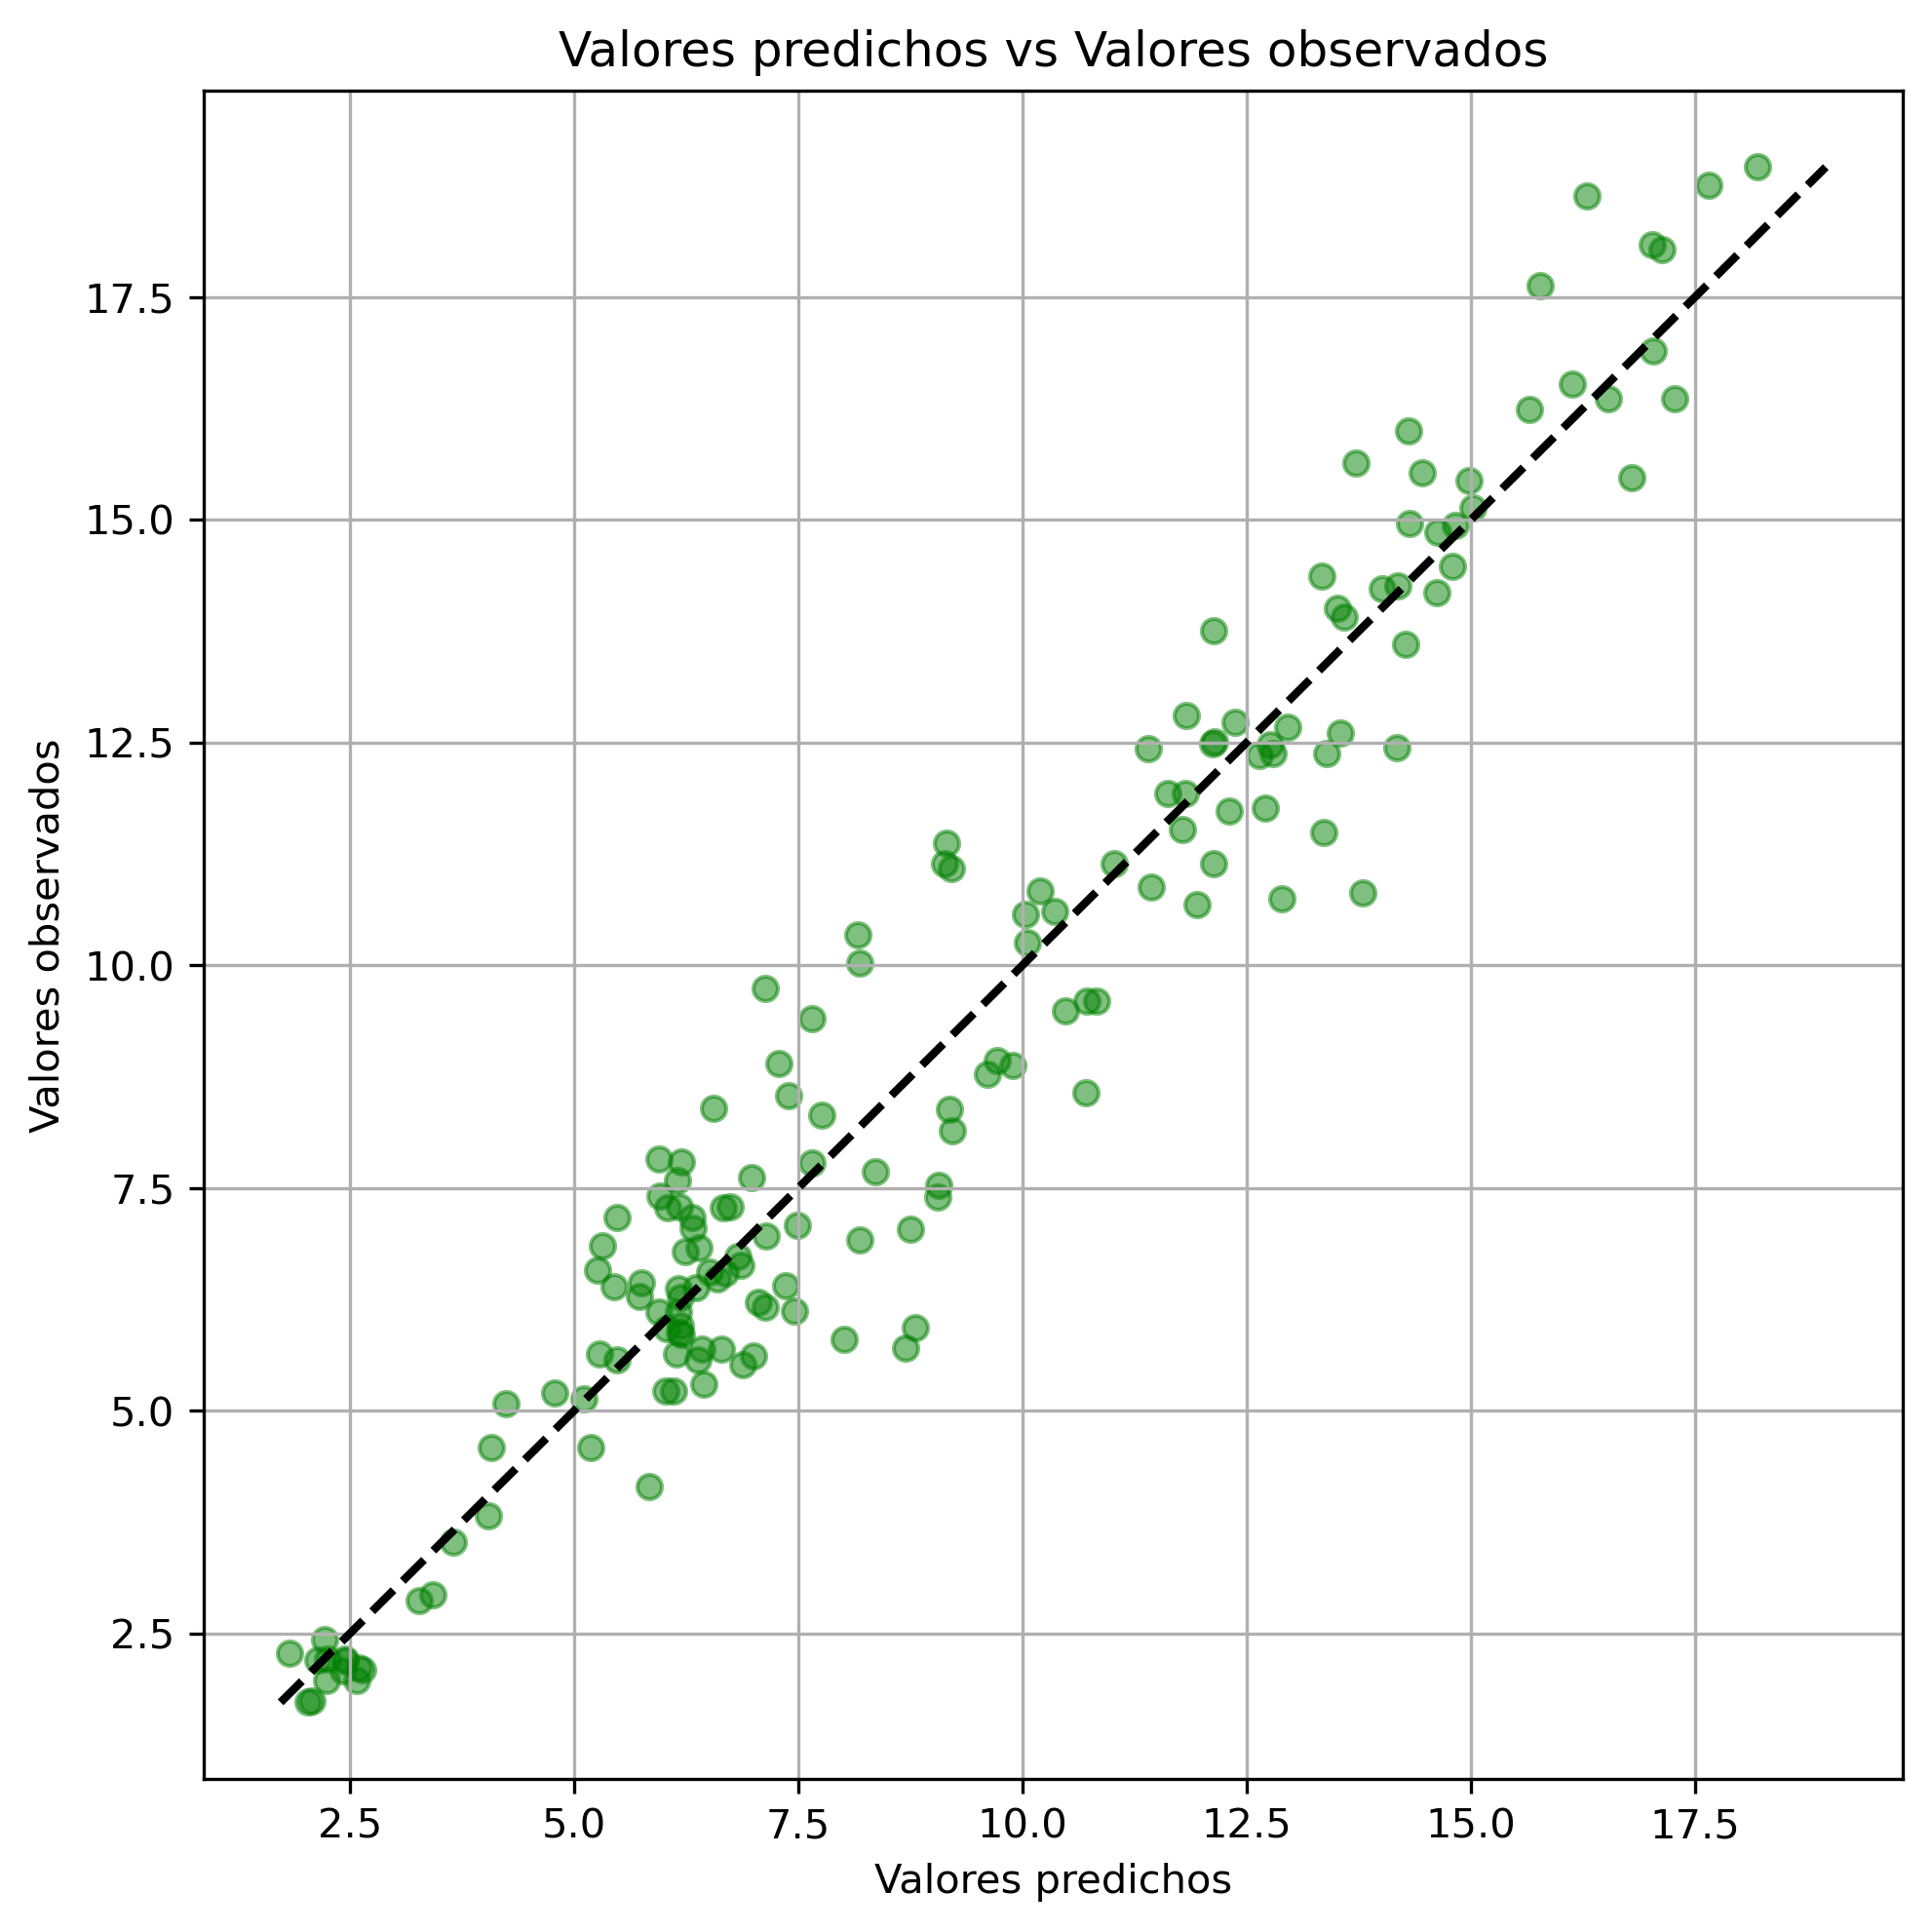

In [75]:
# En modelos multivariados no es posible graficar y = f(x) porque x es multidimensional.
# El grafico "predicted vs observed" es el estandar: si el modelo es perfecto, todos los puntos
# caerian sobre la linea diagonal y = x (linea de referencia punteada)
predicted = model.predict(X)

fig, ax = plt.subplots(1, figsize=(7.5, 7.5), dpi=300)
ax.scatter(predicted, y, alpha=0.5, color='green')

# Linea de referencia: predicted == observed (ajuste perfecto)
ax.plot([y.min(), y.max()], [y.min(), y.max()],
        color='black', linestyle='--', linewidth=2, zorder=2)

ax.set_xlabel('Valores predichos')
ax.set_ylabel('Valores observados')
ax.set_title('Valores predichos vs Valores observados')
ax.grid(zorder=0)
plt.show()

Y ya que estamos, podemos también analizar los residuos.

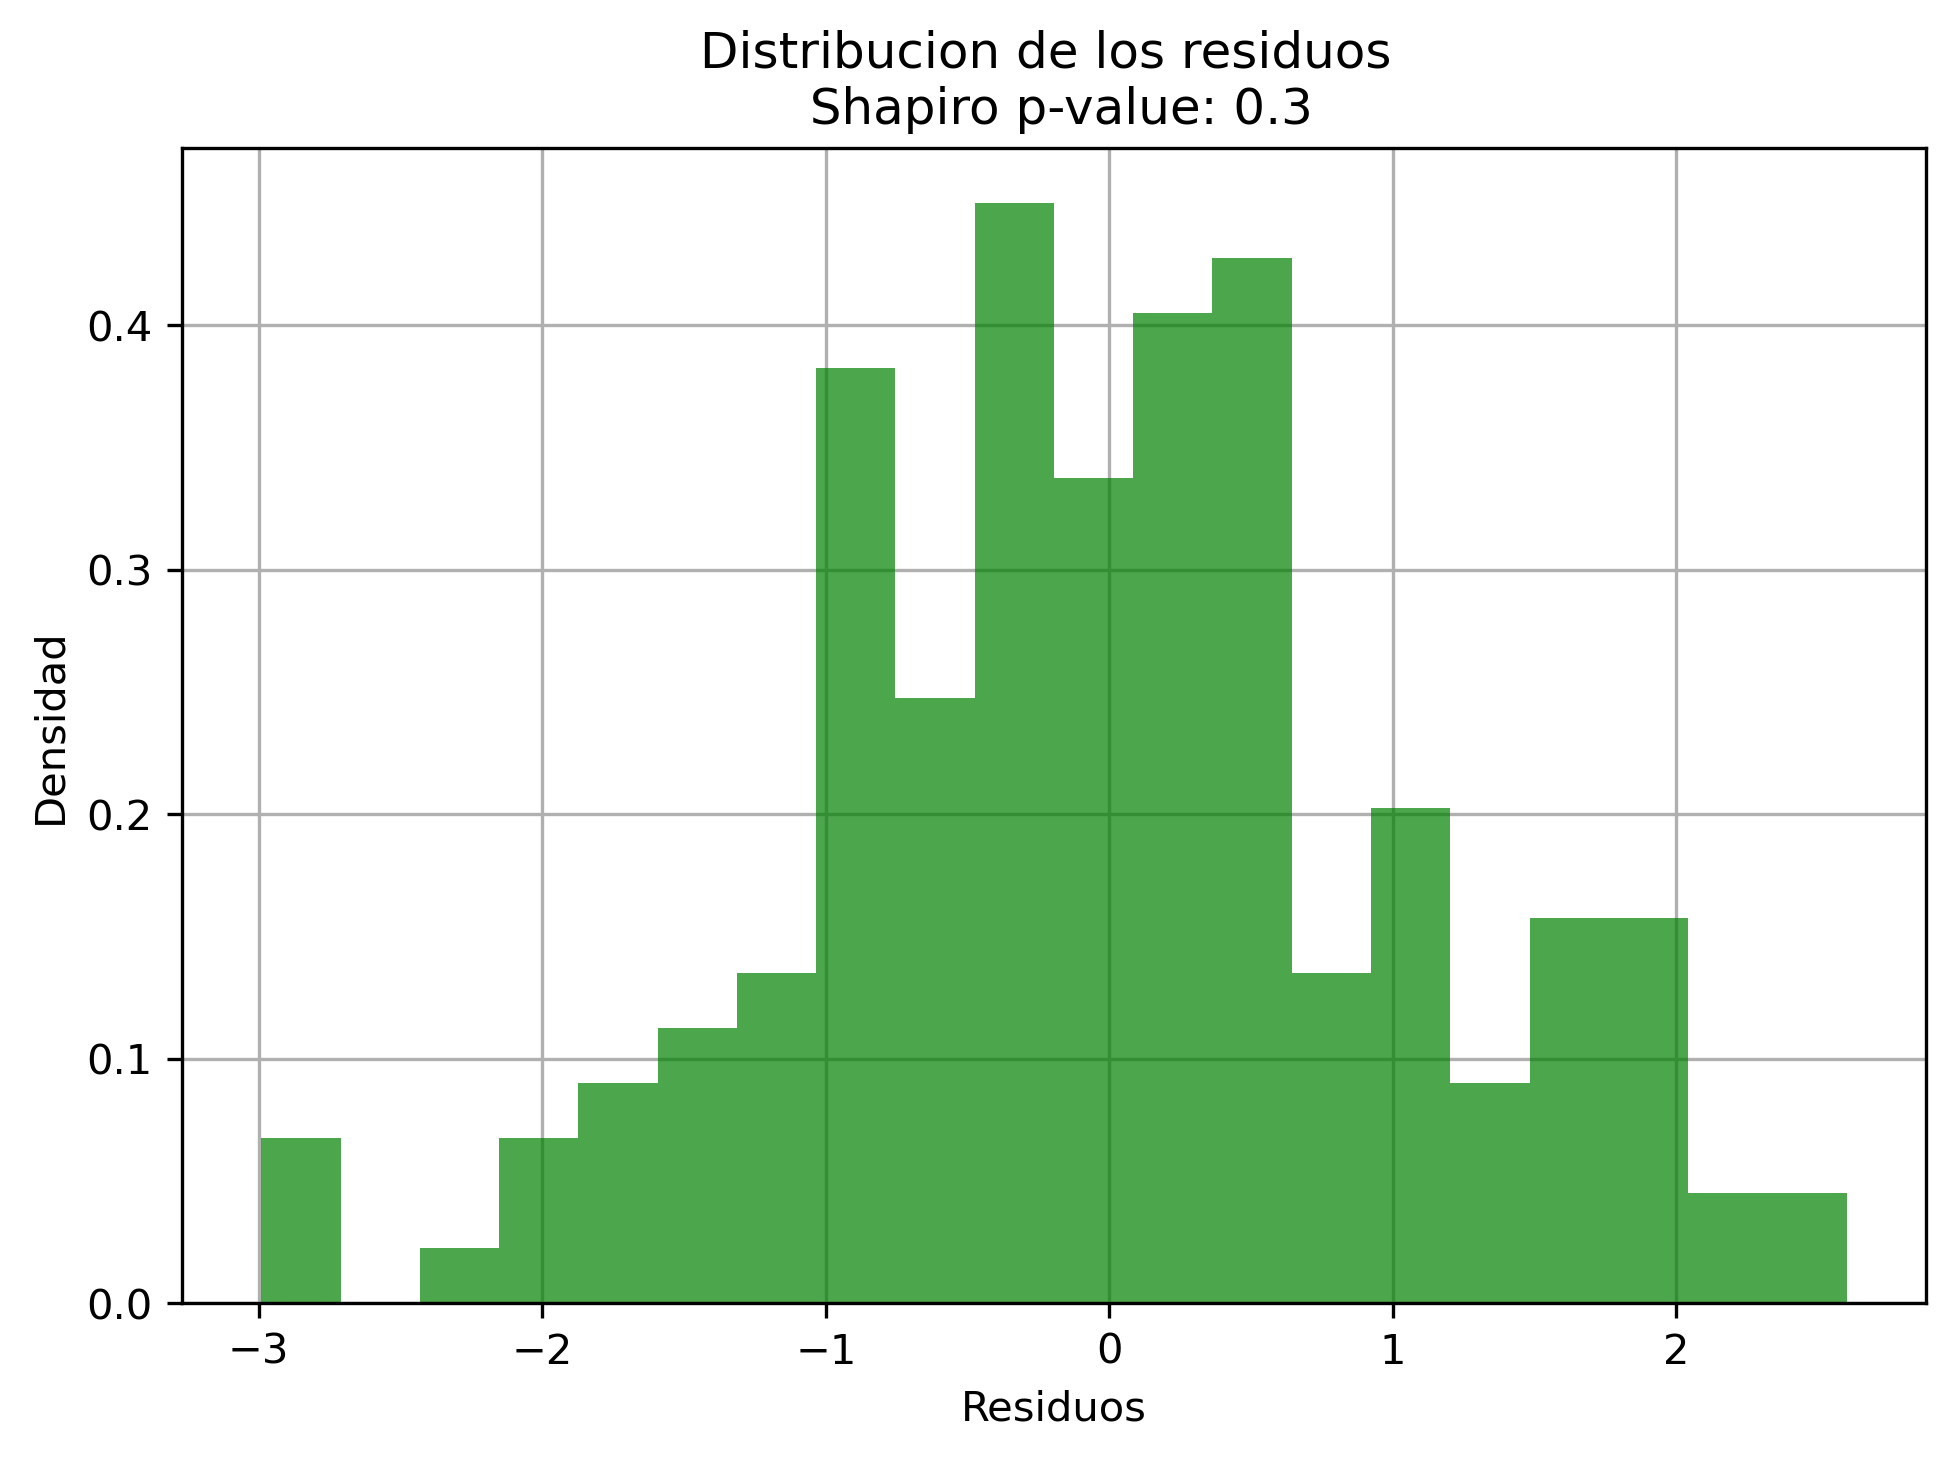

In [76]:
# Verificamos normalidad de los residuos del modelo multivariado
# Un p-value alto en Shapiro-Wilk indica que no rechazamos H0: residuos normales
residuos = model.resid

fig, ax = plt.subplots(1, figsize=(7.5, 5), dpi=300)
shapiro_p = stats.shapiro(residuos)[1]

ax.hist(residuos, bins=20, color='green', alpha=0.7, density=True, zorder=2)
ax.set_title('Distribucion de los residuos \n Shapiro p-value: {:.1f}'.format(shapiro_p))
ax.set_xlabel('Residuos')
ax.set_ylabel('Densidad')
ax.grid(zorder=0)
plt.show()

**¿Qué paso aquí?**

## Selección de Parámetros

Como vimos anteriormente, algunos parámetros no son significativos en el modelo. Y al agregar todos los datos, estamos arriesgando *overfit* el modelo. Así, podemos eliminar parámetros del modelo para cumplir los principios de parsimonia del modelo.

In [77]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression

X = df.copy().drop(columns=['Height', 'Species'])  # predictores candidatos
y = df['Height']  # variable respuesta

# LinearRegression de sklearn es compatible con SequentialFeatureSelector
reg = LinearRegression()

# SequentialFeatureSelector con direction='backward' comienza con todos los predictores
# y elimina de a uno el predictor que menos mejora el rendimiento del modelo
# El criterio por defecto es validacion cruzada (cv=5), que es mas robusto que usar R^2 en muestra
sfs = SequentialFeatureSelector(reg, direction='backward')

sfs.fit(X, y)  # ajusta el selector sobre los datos

# get_feature_names_out retorna los nombres de las columnas seleccionadas
print(sfs.get_feature_names_out())

['Length1' 'Length3' 'Width']


In [78]:
# Comparamos el modelo con todos los predictores vs el modelo reducido por seleccion de variables
# Esperamos que el modelo reducido tenga R^2_adj comparable o mayor, y AIC/BIC menores

print('----Modelo original----')
print(sm.OLS(y, sm.add_constant(X)).fit().summary())
print('-----------------------')
print('')

# X_reducido contiene solo las variables seleccionadas por el algoritmo backward
X_reducido = X[sfs.get_feature_names_out()]

print('----Modelo reducido----')
print(sm.OLS(y, sm.add_constant(X_reducido)).fit().summary())
print('-----------------------')

----Modelo original----
                            OLS Regression Results                            
Dep. Variable:                 Height   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.934
Method:                 Least Squares   F-statistic:                     445.9
Date:                Mon, 27 Apr 2026   Prob (F-statistic):           2.87e-89
Time:                        00:47:55   Log-Likelihood:                -238.26
No. Observations:                 159   AIC:                             488.5
Df Residuals:                     153   BIC:                             506.9
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5440      0

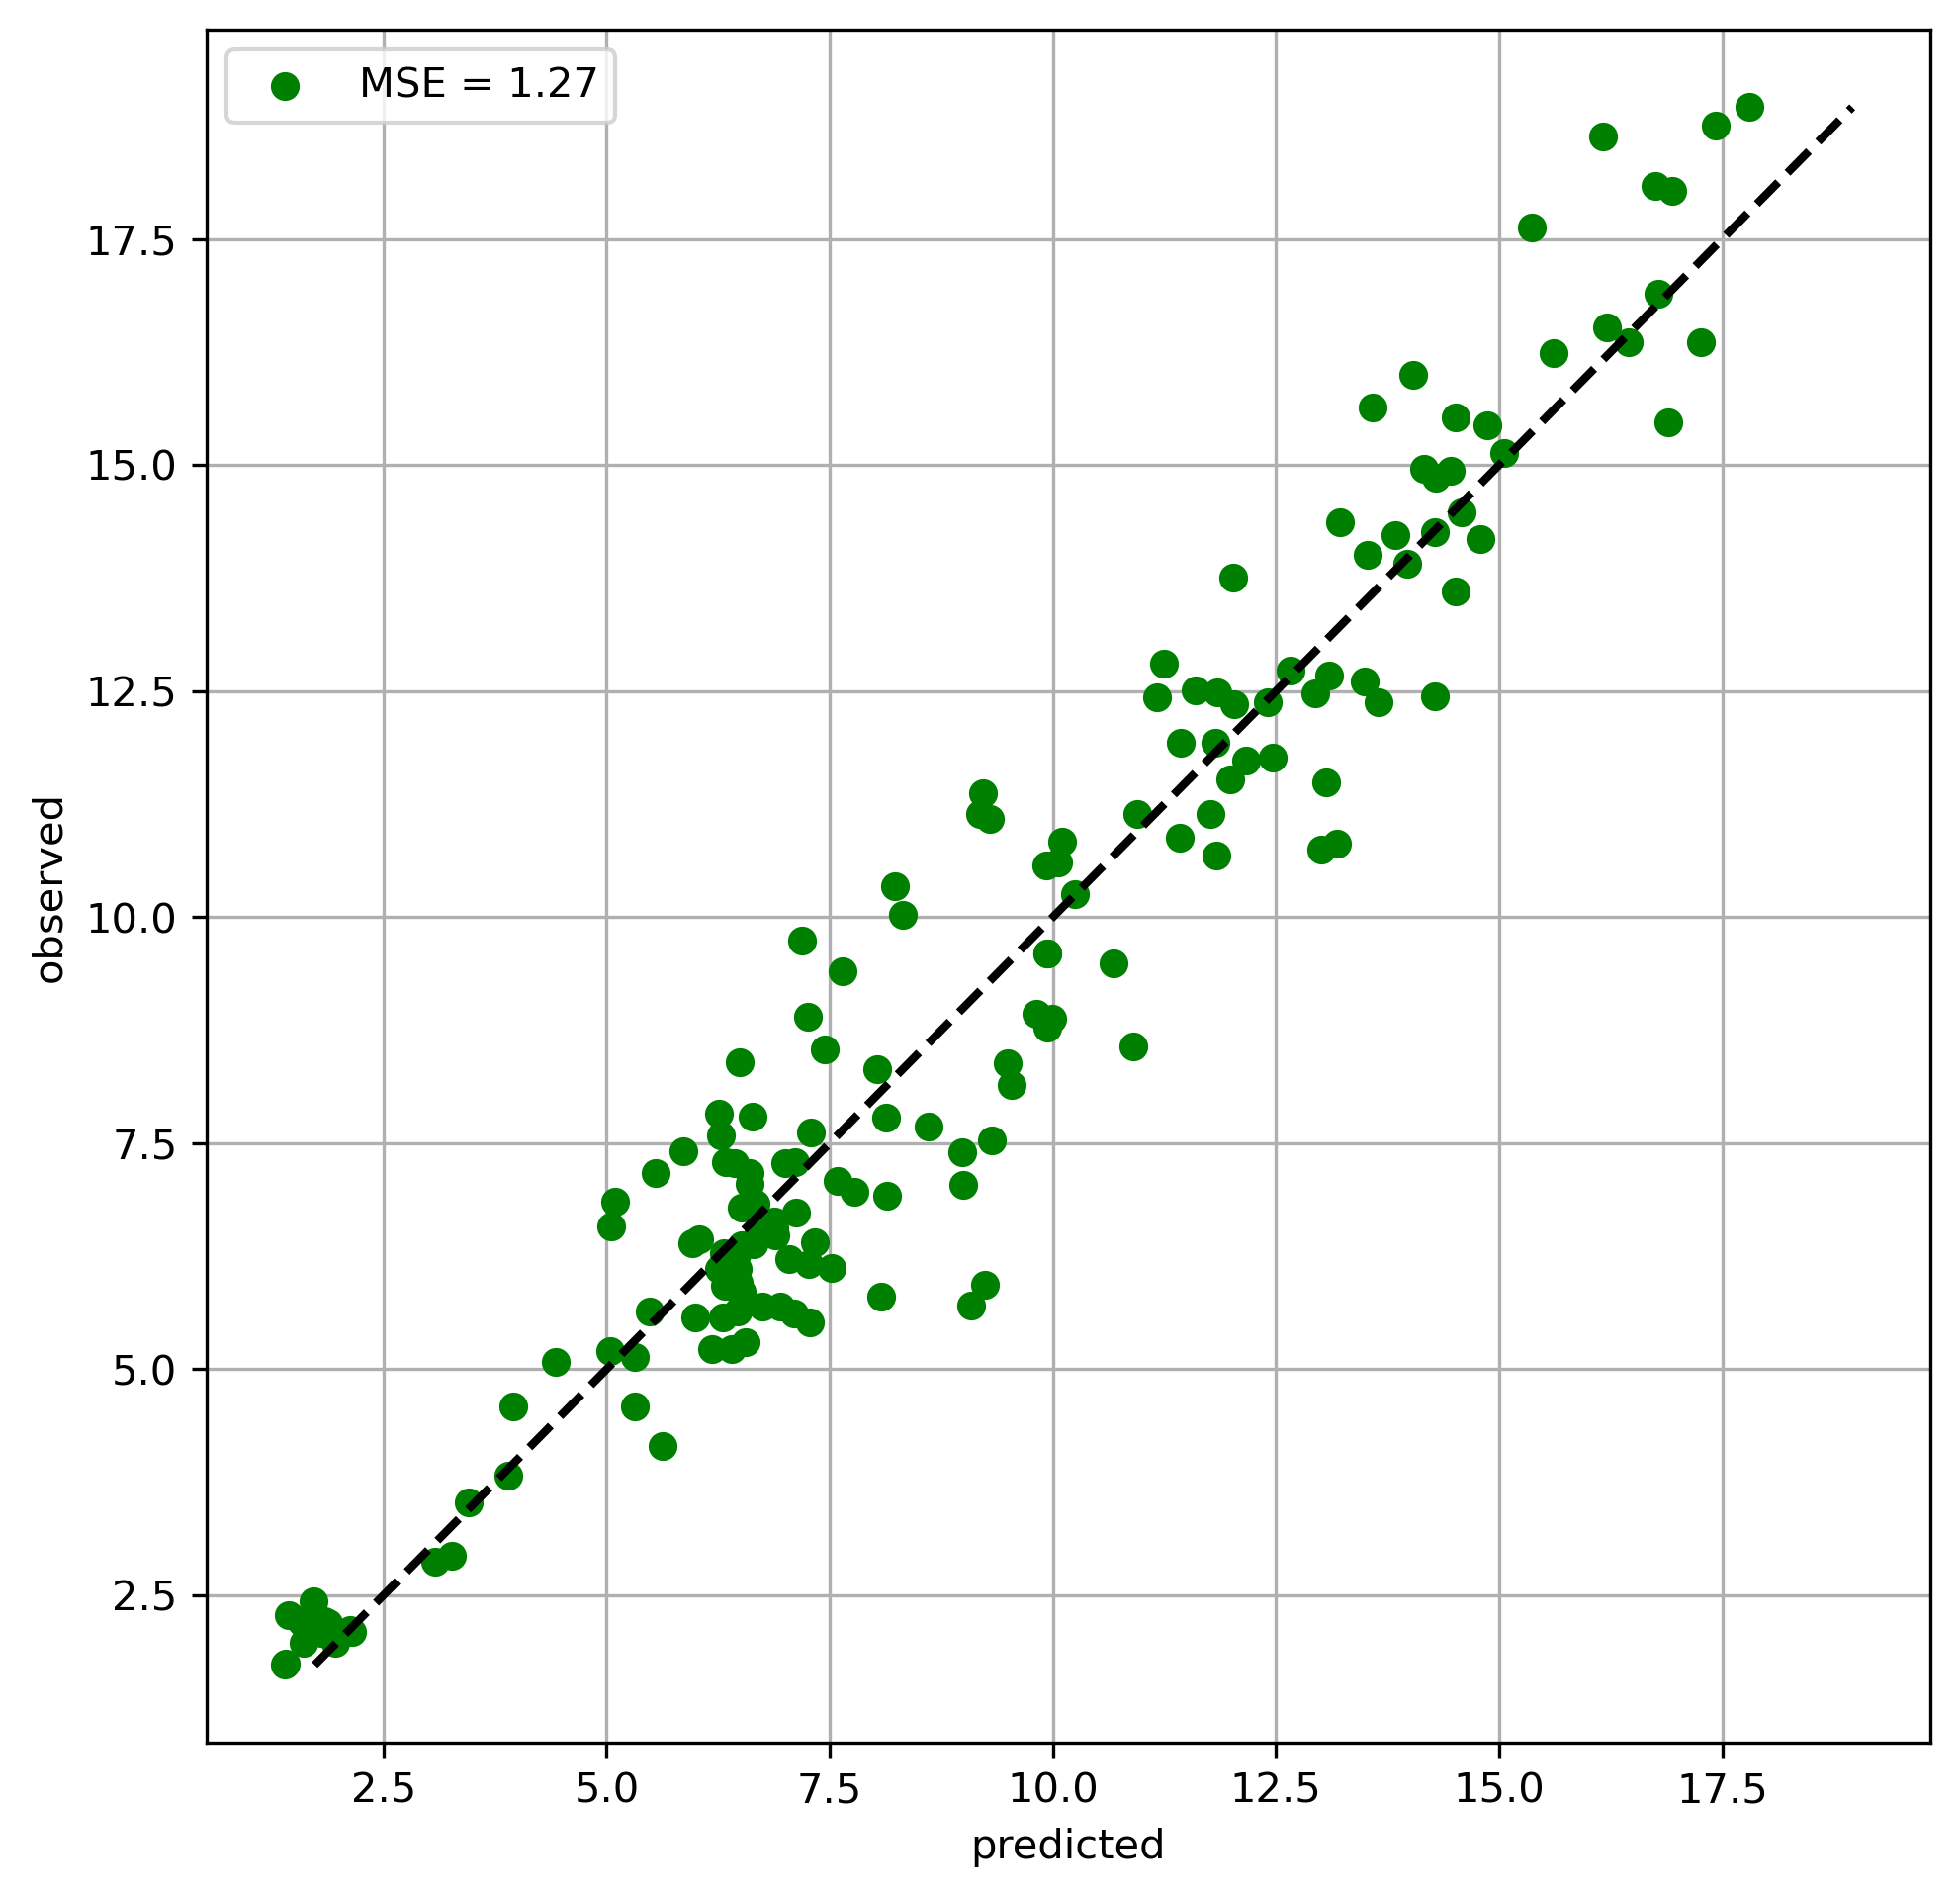

In [79]:
modelo_reducido = sm.OLS(y, sm.add_constant(X_reducido)).fit()
pred = modelo_reducido.predict(sm.add_constant(X_reducido))  # valores predichos del modelo reducido

fig, ax = plt.subplots(figsize=(7.5, 7.5), dpi=300)

# MSE = error cuadratico medio: mide el error promedio al cuadrado entre prediccion y observacion
# Un MSE mas bajo indica mejor ajuste en muestra
mse = np.mean((pred - y)**2)

ax.scatter(pred, y, color='green', label=f'MSE = {mse:.2f}', zorder=2)

# Linea de referencia predicted == observed
ax.plot([y.min(), y.max()], [y.min(), y.max()],
        color='black', linestyle='--', linewidth=2, zorder=2)

ax.legend()
ax.set_xlabel('predicted')
ax.set_ylabel('observed')
ax.grid(zorder=0)

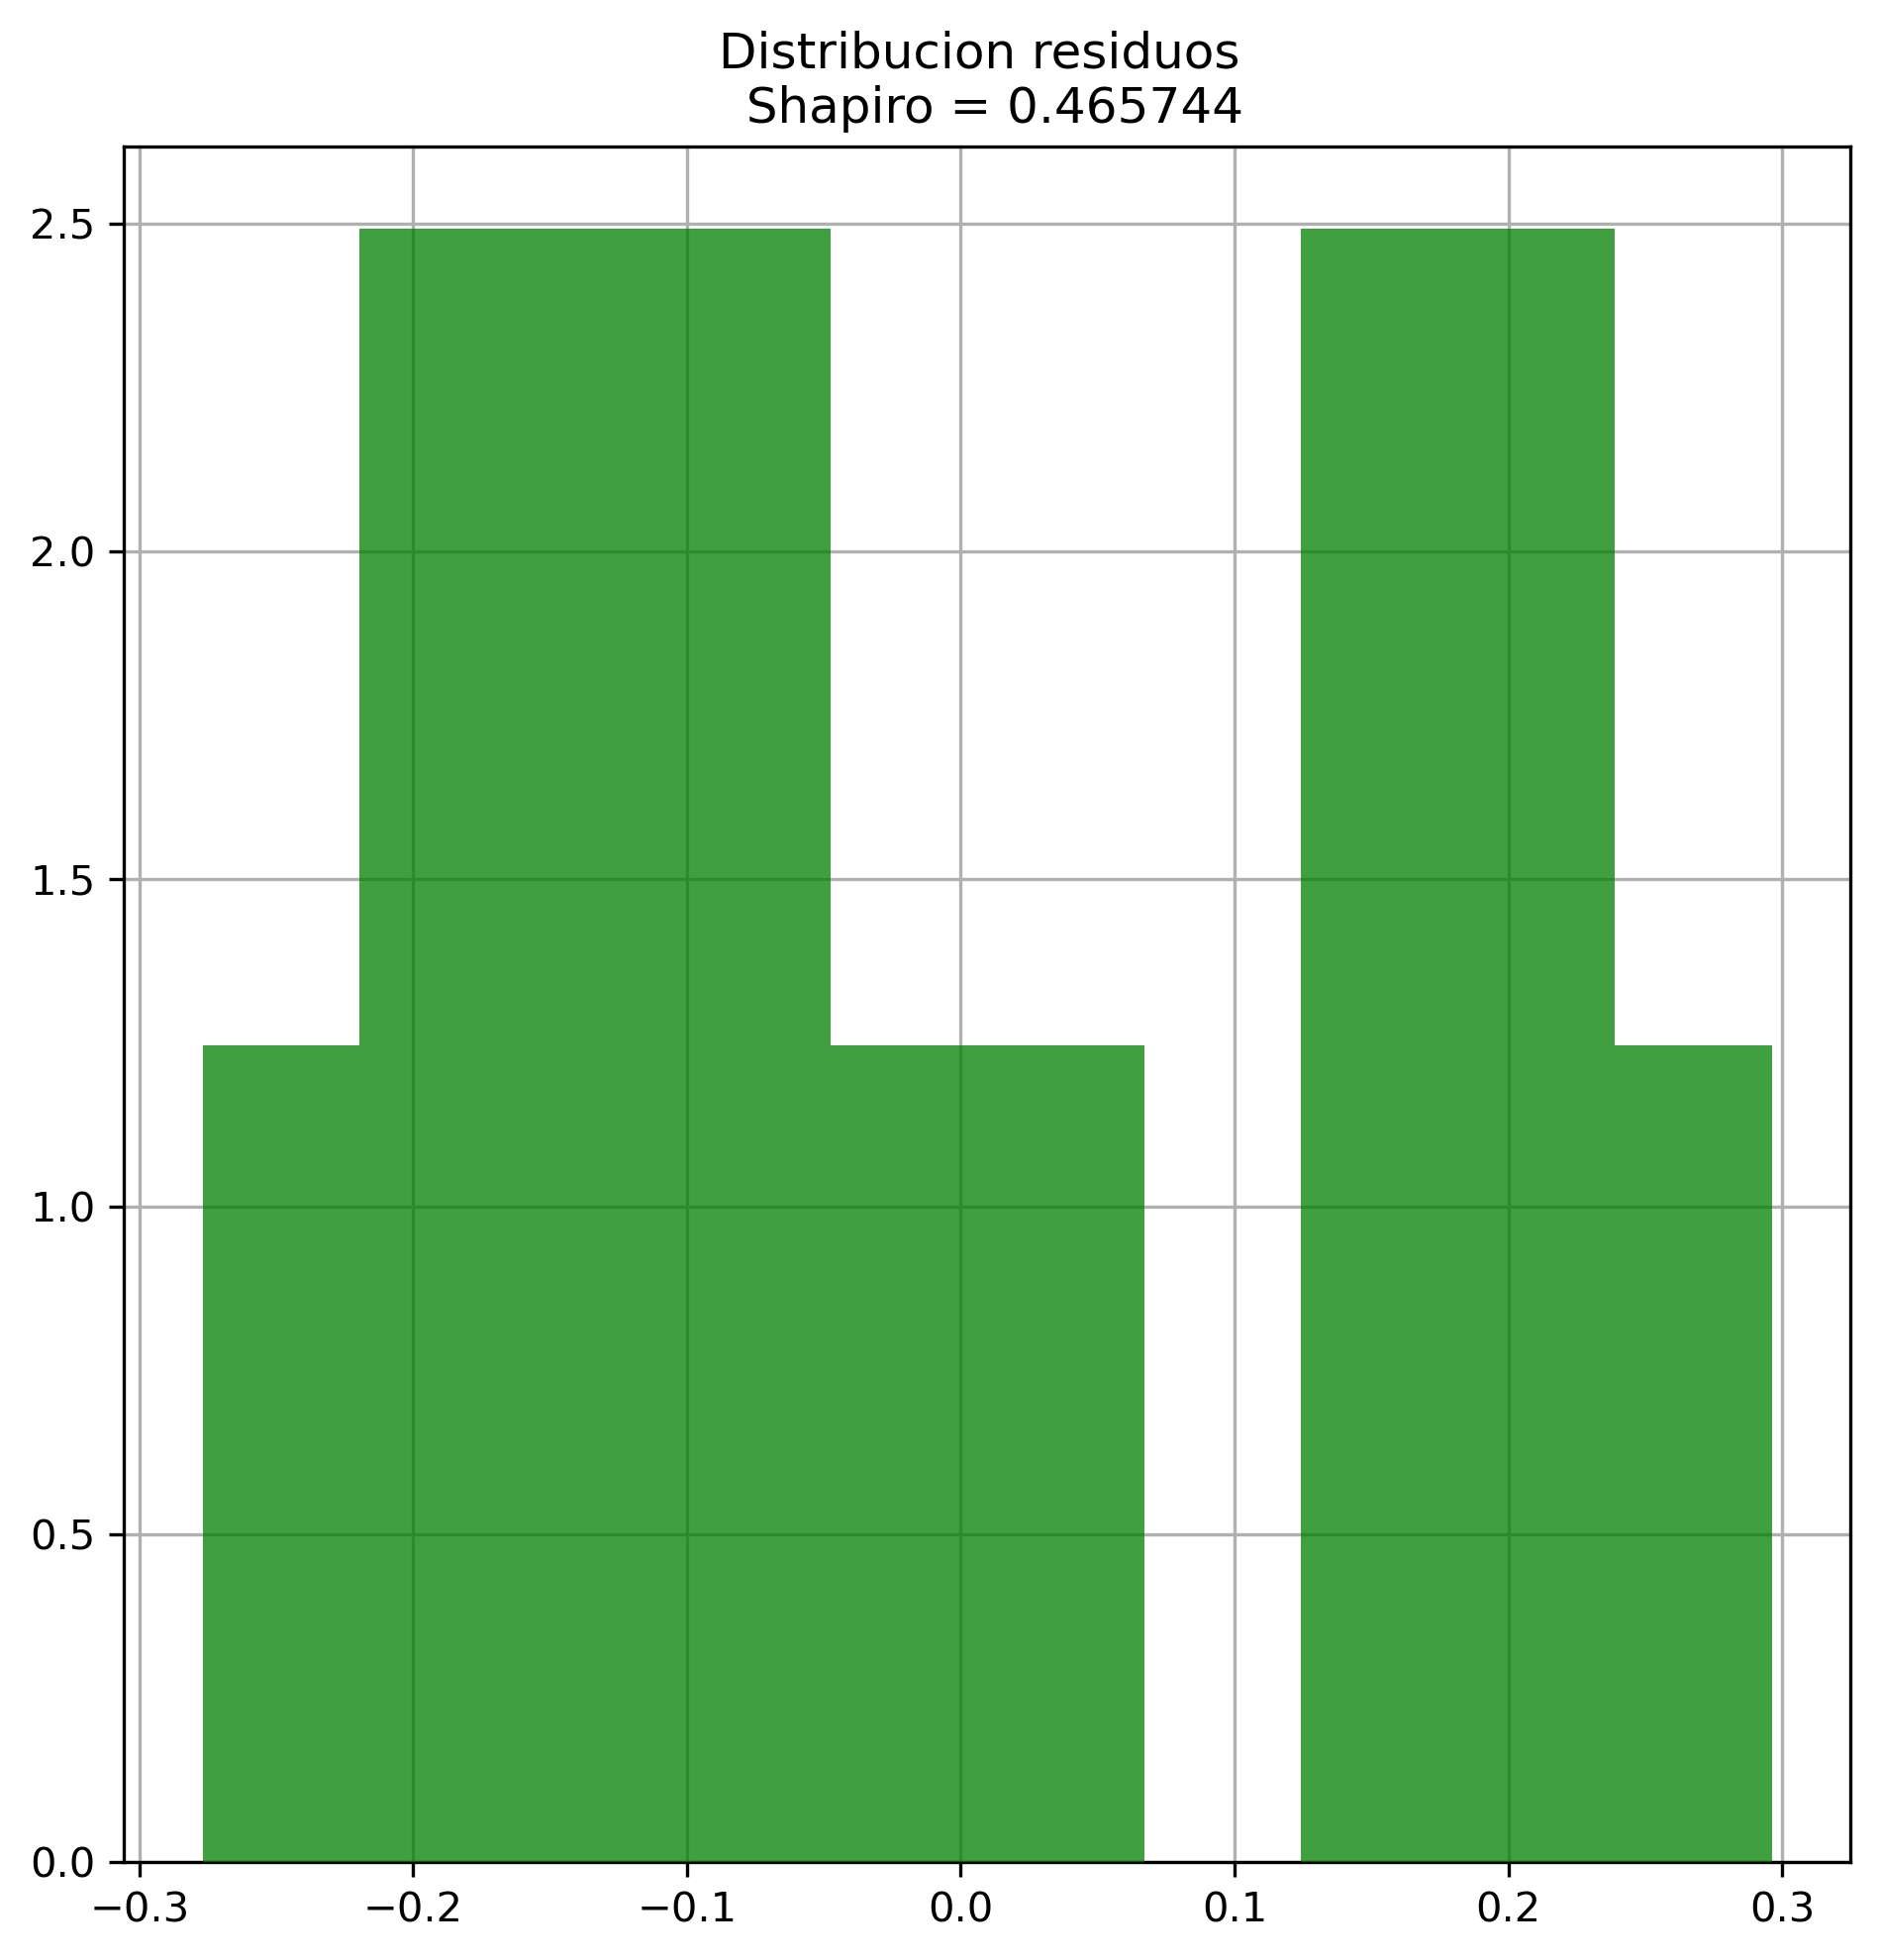

In [80]:
redis = modelo_reducido.resid  # residuos del modelo reducido

fig, ax = plt.subplots(figsize=(7.5, 7.5), dpi=300)

# Shapiro-Wilk sobre los residuos del modelo reducido
shapiro = stats.shapiro(resid)[1]

ax.hist(resid, density=True, color='green', zorder=3, alpha=0.75)
ax.set_title(f'Distribucion residuos \n Shapiro = {shapiro:1f}')
ax.grid(zorder=0)
plt.show()